# 04 — K-Means Clustering | NYC 311 Infrastructure Reporting (2023–2025)

### Objective
Group ZIP/borough areas with similar **reported infrastructure complaint profiles**, comparing baseline, feature-group-balanced, and 90%-variance PCA-reduced inputs. This is unsupervised exploratory analysis; cluster labels are descriptions of reporting behavior, **not a measure of infrastructure health**.

### Analysis principles
- Load the newest outputs of notebooks 02 and 03; use **dynamic** row and feature counts (the prior 100K run used 214 areas and must not be reused).
- Keep **all areas** in the primary experiment. Flag areas with fewer than **30 complaints** consistently with the PCA audit; refit separately without them to assess sensitivity.
- Select a final model only after comparing K, separation indices, cluster sizes, random-seed stability, reporting support, composition, and low-support sensitivity.
- Maintain the original notebook's main CSV/figure filenames where possible. **K=3 is an auditable candidate, not an assumed optimum.**

**Inputs:** `selected_modeling_features.csv`, `kmeans_pca_input.csv`, `kmeans_pca_input_balanced.csv` and fitted PCA artifacts from notebook 03.

In [2]:
import os
# Set before importing sklearn, especially useful with Windows + MKL.
os.environ.setdefault("OMP_NUM_THREADS", "1")

import sys
from pathlib import Path
import itertools
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score,
)

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "config" / "config.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the project root or notebooks/ in VS Code; config/config.py was not found.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from config.config import PROCESSED_DATA_DIR, OUTPUT_DIR, PCA_DIR

KMEANS_TABLES_DIR = OUTPUT_DIR / "tables" / "kmeans"
KMEANS_FIGURES_DIR = OUTPUT_DIR / "figures" / "kmeans"
KMEANS_MODELS_DIR = PROJECT_ROOT / "models" / "kmeans"
PCA_TABLES_DIR = OUTPUT_DIR / "tables" / "pca"
for folder in (KMEANS_TABLES_DIR, KMEANS_FIGURES_DIR, KMEANS_MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
LOW_SUPPORT_THRESHOLD = 30   # Reporting-sufficiency audit, not a quality cutoff.
K_CANDIDATE = 3               # Investigated in depth for comparison with previous work.
print("Project root:", PROJECT_ROOT)
print("Cluster outputs:", KMEANS_TABLES_DIR)
print("Low-support threshold:", LOW_SUPPORT_THRESHOLD)

Project root: d:\Urban-Infrastructure-Pulse-Intelligence
Cluster outputs: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\kmeans
Low-support threshold: 30


## 1. Load and validate the latest geographic feature matrices
Both matrices and the original selected features must have **exactly the same unique area IDs in the same order**. This catches mixed old/new runs. The original selected data is used only for interpretation, not directly to fit K-Means.

In [3]:
input_files = {
    "Baseline": PROCESSED_DATA_DIR / "kmeans_pca_input.csv",
    "Balanced": PROCESSED_DATA_DIR / "kmeans_pca_input_balanced.csv",
    "Source": PROCESSED_DATA_DIR / "selected_modeling_features.csv",
}
for name, path in input_files.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"{name}: missing {path}. Run feature selection and notebook 02 first."
        )

baseline_df = pd.read_csv(input_files["Baseline"])
balanced_df = pd.read_csv(input_files["Balanced"])
source_df = pd.read_csv(input_files["Source"])
for name, frame in (("Baseline", baseline_df), ("Balanced", balanced_df), ("Source", source_df)):
    if "area_id" not in frame:
        raise ValueError(f"{name}: missing area_id")
    if frame["area_id"].isna().any() or frame["area_id"].duplicated().any():
        raise ValueError(f"{name}: missing or duplicate area_id")

area_ids = baseline_df["area_id"].astype(str).tolist()
if area_ids != balanced_df["area_id"].astype(str).tolist():
    raise ValueError("Baseline and balanced rows have different area IDs/order")
if area_ids != source_df["area_id"].astype(str).tolist():
    raise ValueError("Original feature rows do not align; rerun notebooks 02 and 03")
X_baseline = baseline_df.drop(columns="area_id")
X_balanced = balanced_df.drop(columns="area_id")
feature_order = X_baseline.columns.tolist()
if not feature_order or feature_order != X_balanced.columns.tolist():
    raise ValueError("Baseline/balanced numerical features do not match")
if len(area_ids) < 12 or len(feature_order) < 2:
    raise ValueError("Insufficient areas/features for K=2..10 experiments")
for name, X in (("Baseline", X_baseline), ("Balanced", X_balanced)):
    if X.select_dtypes(exclude="number").columns.tolist():
        raise TypeError(f"{name}: non-numeric model input")
    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError(f"{name}: NaN or infinity")
if "total_complaints" not in source_df:
    raise ValueError("Source dataset requires total_complaints for support analysis")
if source_df["total_complaints"].isna().any() or (source_df["total_complaints"] <= 0).any():
    raise ValueError("Source complaint counts must be positive and nonmissing")

support_summary = source_df[["area_id", "total_complaints"]].copy()
support_summary["low_support_flag"] = support_summary["total_complaints"] < LOW_SUPPORT_THRESHOLD
support_mask = (~support_summary["low_support_flag"]).to_numpy()

print("DATASET VALIDATION PASSED")
print("Areas:", len(area_ids))
print("Numerical model features:", len(feature_order))
print("Share features:", sum(c.startswith("share_") for c in source_df))
print(f"Low-support areas (<{LOW_SUPPORT_THRESHOLD} reports):", int((~support_mask).sum()))
print("Baseline:", X_baseline.shape, "Balanced:", X_balanced.shape)
display(support_summary.head())

DATASET VALIDATION PASSED
Areas: 238
Numerical model features: 19
Share features: 14
Low-support areas (<30 reports): 47
Baseline: (238, 19) Balanced: (238, 19)


,area_id,total_complaints,low_support_flag
0,BRONX_10451,3144,False
1,BRONX_10452,3107,False
2,BRONX_10453,3031,False
3,BRONX_10454,2484,False
4,BRONX_10455,2387,False


## 2. Reuse the fitted PCA models (90% variance retained)

Use PCA models **already fitted in notebook 03**. The PCA transform and saved PC1/PC2 projections are checked for agreement with these matrices, so stale PCA models cause a clear failure instead of a misleading experiment. PCA scores are not whitened; preserving score variances preserves the principal-component geometry.

In [4]:
datasets = {"Baseline": X_baseline, "Balanced": X_balanced}
pca_audit_rows = []
pca_component_counts = {}
pca_model_paths = {}

for display_name, X in (("Baseline", X_baseline), ("Balanced", X_balanced)):
    slug = display_name.lower()
    model_path = PCA_DIR / f"{slug}_pca_model.joblib"
    projection_path = PCA_TABLES_DIR / f"{slug}_pca_2d.csv"
    if not model_path.is_file() or not projection_path.is_file():
        raise FileNotFoundError(
            f"Missing PCA model/projection for {display_name}. "
            "Run notebook 03 PCA analysis (Restart Kernel and Run All)."
        )
    payload = joblib.load(model_path)  # Load only your own trusted local project artifacts.
    if payload.get("feature_order") != feature_order:
        raise ValueError(f"{display_name}: PCA feature order differs; rerun notebook 03")
    if payload.get("area_count_at_fit") != len(area_ids):
        raise ValueError(f"{display_name}: PCA fitted on a different number of areas")
    pca = payload["pca"]
    scores = pca.transform(X.to_numpy(dtype=float))
    projection = pd.read_csv(projection_path)
    if (projection["area_id"].astype(str).tolist() != area_ids or
        not np.allclose(projection[["PC1", "PC2"]].to_numpy(), scores[:, :2], rtol=1e-5, atol=1e-5)):
        raise ValueError(
            f"{display_name}: PCA projection differs from current matrix/model. "
            "Rerun notebook 03 before K-Means."
        )
    explained = np.asarray(pca.explained_variance_ratio_)
    n_90 = min(len(explained), int(np.searchsorted(np.cumsum(explained), 0.90) + 1))
    pca_name = f"{display_name} PCA90"
    pc_names = [f"PC{i + 1}" for i in range(n_90)]
    datasets[pca_name] = pd.DataFrame(scores[:, :n_90], columns=pc_names)
    pca_component_counts[pca_name] = n_90
    pca_model_paths[pca_name] = str(model_path)
    pca_audit_rows.append({
        "representation": pca_name,
        "components_90pct": n_90,
        "variance_retained_pct": 100 * float(explained[:n_90].sum()),
        "areas": len(area_ids),
    })

pca_audit = pd.DataFrame(pca_audit_rows)
display(pca_audit.round(3))
pca_audit.to_csv(KMEANS_TABLES_DIR / "pca90_input_audit.csv", index=False)
print("PCA artifact checks passed — candidate representations:", list(datasets))

c:\Users\Administrator\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Administrator\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,representation,components_90pct,variance_retained_pct,areas
0,Baseline PCA90,2,90.142,238
1,Balanced PCA90,5,90.686,238


PCA artifact checks passed — candidate representations: ['Baseline', 'Balanced', 'Baseline PCA90', 'Balanced PCA90']


## 3. K = 2–10: quality, cluster size and support diagnostics

Silhouette (higher), Davies–Bouldin (lower), Calinski–Harabasz (higher), and inertia (within-representation elbow) are **not sufficient by themselves**. Examine tiny clusters, the largest cluster's share, and reporting support. Do not compare raw inertia across the different representations.

In [5]:
K_VALUES = list(range(2, min(10, len(area_ids) - 2) + 1))

def fit_kmeans(X, k, seed=RANDOM_STATE, n_init=20):
    model = KMeans(
        n_clusters=int(k), init="k-means++", n_init=n_init,
        random_state=int(seed), max_iter=500,
    )
    labels = model.fit_predict(X)
    return model, labels

def evaluate_partition(X, labels, model):
    counts = np.bincount(labels, minlength=model.n_clusters)
    return {
        "inertia": float(model.inertia_),
        "silhouette": float(silhouette_score(X, labels)),
        "davies_bouldin": float(davies_bouldin_score(X, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X, labels)),
        "min_cluster_size": int(counts.min()),
        "max_cluster_size": int(counts.max()),
        "largest_cluster_pct": 100 * float(counts.max()) / len(X),
        "singleton_clusters": int((counts == 1).sum()),
    }

evaluation_rows = []
for name, X in datasets.items():
    print("Evaluating:", name)
    matrix = X.to_numpy(dtype=float)
    for k in K_VALUES:
        model, labels = fit_kmeans(matrix, k)
        metrics = evaluate_partition(matrix, labels, model)
        evaluation_rows.append({"representation": name, "k": k, **metrics})

evaluation_all_df = pd.DataFrame(evaluation_rows)
evaluation_df = evaluation_all_df[
    evaluation_all_df["representation"].isin(["Baseline", "Balanced"])
].copy()
evaluation_df.to_csv(KMEANS_TABLES_DIR / "kmeans_k_evaluation.csv", index=False)
evaluation_all_df.to_csv(KMEANS_TABLES_DIR / "kmeans_k_evaluation_all_representations.csv", index=False)
display(evaluation_all_df.round(4))

Evaluating: Baseline
Evaluating: Balanced
Evaluating: Baseline PCA90
Evaluating: Balanced PCA90


,representation,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size,largest_cluster_pct,singleton_clusters
0,Baseline,2,217.8846,0.7300,0.5154,587.6373,45,193,81.0924,0
1,Baseline,3,148.4518,0.6554,0.8215,484.3705,21,174,73.1092,0
2,Baseline,4,106.7146,0.6465,0.8816,477.8037,17,174,73.1092,0
3,Baseline,5,92.2811,0.6301,0.9415,421.7419,10,172,72.2689,0
4,Baseline,6,81.7261,0.6157,1.0524,385.3256,10,172,72.2689,0
5,Baseline,7,71.9579,0.2944,1.1793,368.3485,10,93,39.0756,0
6,Baseline,8,65.9317,0.3038,1.1030,346.0965,4,95,39.9160,0
7,Baseline,9,62.8395,0.2918,1.2159,317.7636,5,92,38.6555,0
8,Baseline,10,57.6155,0.2930,1.1447,309.0183,4,91,38.2353,0
9,Balanced,2,365.8513,0.6745,0.6821,378.1075,45,193,81.0924,0


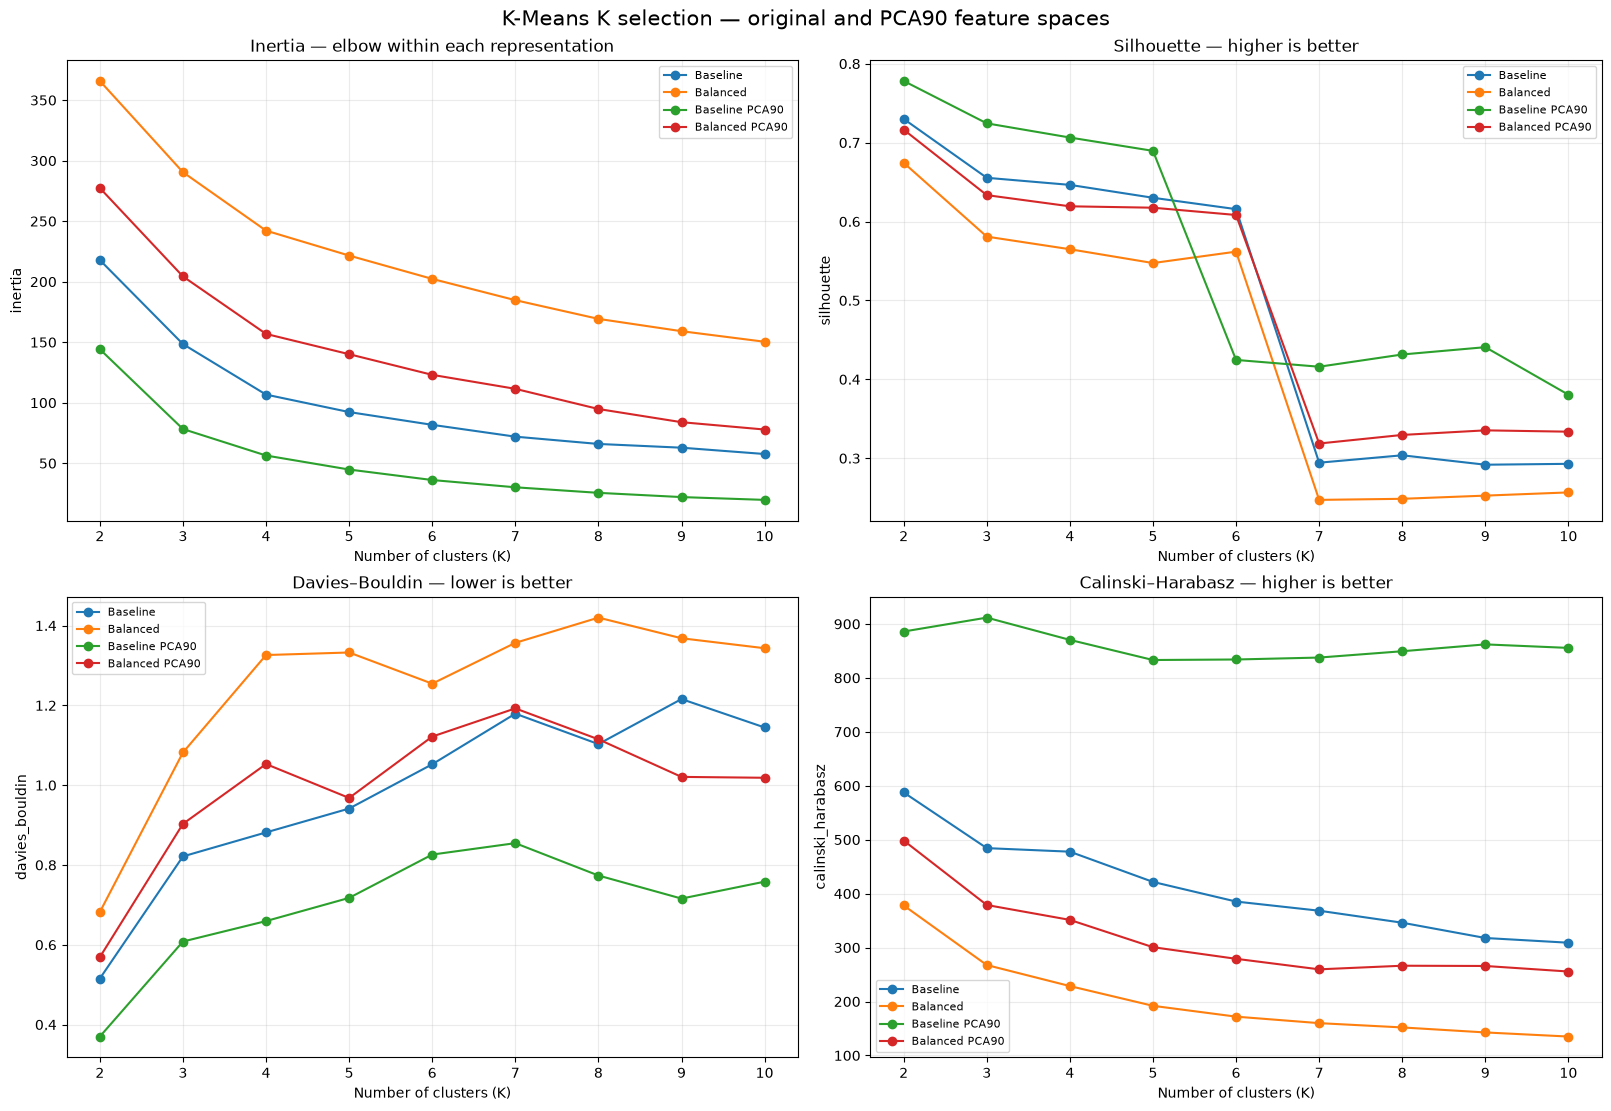

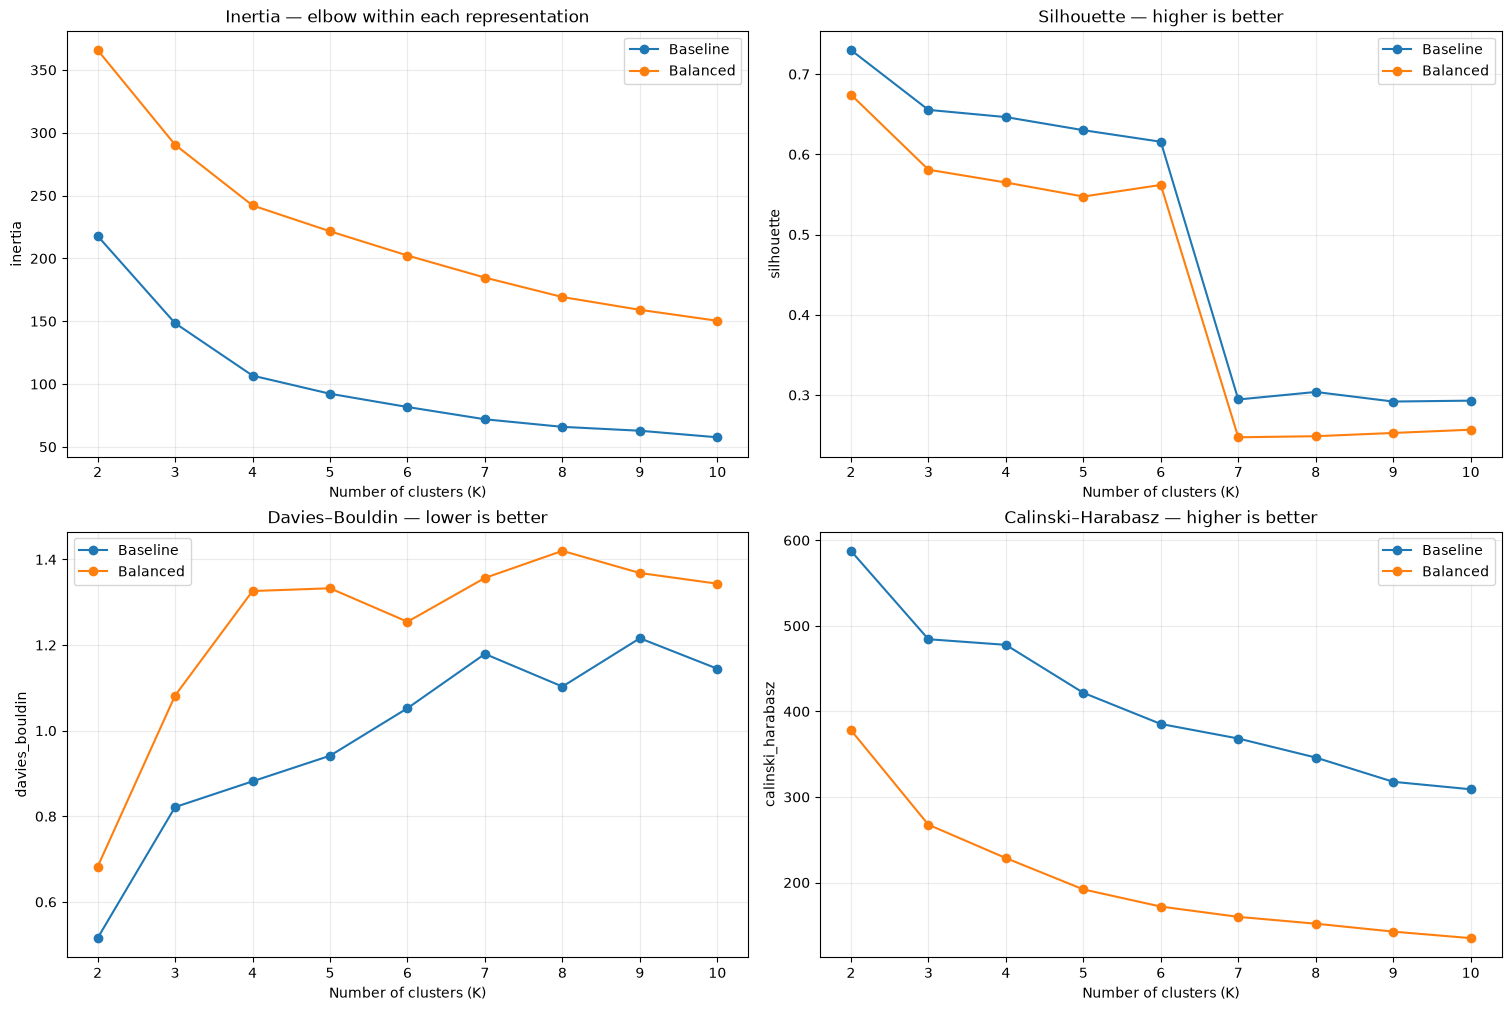

In [6]:
metric_specs = [
    ("inertia", "Inertia — elbow within each representation"),
    ("silhouette", "Silhouette — higher is better"),
    ("davies_bouldin", "Davies–Bouldin — lower is better"),
    ("calinski_harabasz", "Calinski–Harabasz — higher is better"),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for ax, (metric, title) in zip(axes.flat, metric_specs):
    for name in datasets:
        subset = evaluation_all_df[evaluation_all_df["representation"] == name]
        ax.plot(subset["k"], subset[metric], marker="o", label=name)
    ax.set(title=title, xlabel="Number of clusters (K)", ylabel=metric)
    ax.set_xticks(K_VALUES)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("K-Means K selection — original and PCA90 feature spaces", fontsize=15)
fig.savefig(KMEANS_FIGURES_DIR / "kmeans_k_evaluation_all_representations.png", dpi=200, bbox_inches="tight")
plt.show()

# Preserve original figure name for users of the earlier pipeline.
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for ax, (metric, title) in zip(axes.flat, metric_specs):
    for name in ("Baseline", "Balanced"):
        subset = evaluation_df[evaluation_df["representation"] == name]
        ax.plot(subset["k"], subset[metric], marker="o", label=name)
    ax.set(title=title, xlabel="Number of clusters (K)", ylabel=metric)
    ax.set_xticks(K_VALUES)
    ax.grid(alpha=0.25)
    ax.legend()
fig.savefig(KMEANS_FIGURES_DIR / "kmeans_k_evaluation.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
candidate_rows = []
for name in datasets:
    sub = evaluation_all_df[evaluation_all_df["representation"] == name]
    best_sil = sub.loc[sub["silhouette"].idxmax()]
    best_db = sub.loc[sub["davies_bouldin"].idxmin()]
    best_ch = sub.loc[sub["calinski_harabasz"].idxmax()]
    candidate_rows.append({
        "representation": name,
        "best_k_silhouette": int(best_sil["k"]),
        "best_k_davies_bouldin": int(best_db["k"]),
        "best_k_calinski_harabasz": int(best_ch["k"]),
        "best_silhouette_value": float(best_sil["silhouette"]),
        "minimum_cluster_size_at_best_silhouette": int(best_sil["min_cluster_size"]),
        "largest_cluster_pct_at_best_silhouette": float(best_sil["largest_cluster_pct"]),
    })
candidate_summary_all = pd.DataFrame(candidate_rows)
candidate_summary = candidate_summary_all[
    candidate_summary_all["representation"].isin(["Baseline", "Balanced"])
].copy()
candidate_summary.to_csv(KMEANS_TABLES_DIR / "candidate_k_summary.csv", index=False)
candidate_summary_all.to_csv(KMEANS_TABLES_DIR / "candidate_k_summary_all_representations.csv", index=False)
display(candidate_summary_all.round(4))
print("These are metric-specific candidates, NOT a finalized choice of K.")

,representation,best_k_silhouette,best_k_davies_bouldin,best_k_calinski_harabasz,best_silhouette_value,minimum_cluster_size_at_best_silhouette,largest_cluster_pct_at_best_silhouette
0,Baseline,2,2,2,0.7300,45,81.0924
1,Balanced,2,2,2,0.6745,45,81.0924
2,Baseline PCA90,2,2,3,0.7782,45,81.0924
3,Balanced PCA90,2,2,2,0.7164,45,81.0924


These are metric-specific candidates, NOT a finalized choice of K.


## 4. Examine K=3 in depth (provisional comparison only)

The previous 100K notebook used K=3. We retain it for comparability, but **recompute every result** on the new matrices and do not assume K=3 is best. Cluster IDs are arbitrary; compare memberships using Adjusted Rand Index (ARI), not numerical label equality.

In [8]:
if K_CANDIDATE not in K_VALUES:
    raise ValueError("K=3 is not available for this dataset")
cluster_results = {}
candidate_models = {}
for name, X in datasets.items():
    model, labels = fit_kmeans(X.to_numpy(dtype=float), K_CANDIDATE, n_init=50)
    assignments = support_summary.copy()
    assignments["cluster_id"] = labels
    cluster_results[name] = assignments
    candidate_models[name] = model
    filename = name.lower().replace(" ", "_") + "_k3_assignments.csv"
    assignments.to_csv(KMEANS_TABLES_DIR / filename, index=False)
    print("\n", name, "K=3 cluster sizes:")
    display(assignments["cluster_id"].value_counts().sort_index().to_frame("areas"))


 Baseline K=3 cluster sizes:


,areas
cluster_id,
0,174
1,43
2,21



 Balanced K=3 cluster sizes:


,areas
cluster_id,
0,174
1,43
2,21



 Baseline PCA90 K=3 cluster sizes:


,areas
cluster_id,
0,175
1,43
2,20



 Balanced PCA90 K=3 cluster sizes:


,areas
cluster_id,
0,21
1,43
2,174


,representation,cluster_id,number_of_areas,area_percentage,low_support_areas,low_support_percentage,median_complaints,min_complaints
0,Baseline,0,174,73.11,0,0.00,3473.5,284
1,Baseline,1,43,18.07,42,97.67,5.0,1
2,Baseline,2,21,8.82,5,23.81,82.0,11
3,Balanced,0,174,73.11,0,0.00,3473.5,284
4,Balanced,1,43,18.07,42,97.67,5.0,1
5,Balanced,2,21,8.82,5,23.81,82.0,11
6,Baseline PCA90,0,175,73.53,0,0.00,3471.0,89
7,Baseline PCA90,1,43,18.07,42,97.67,5.0,1
8,Baseline PCA90,2,20,8.40,5,25.00,71.0,11
9,Balanced PCA90,0,21,8.82,5,23.81,82.0,11


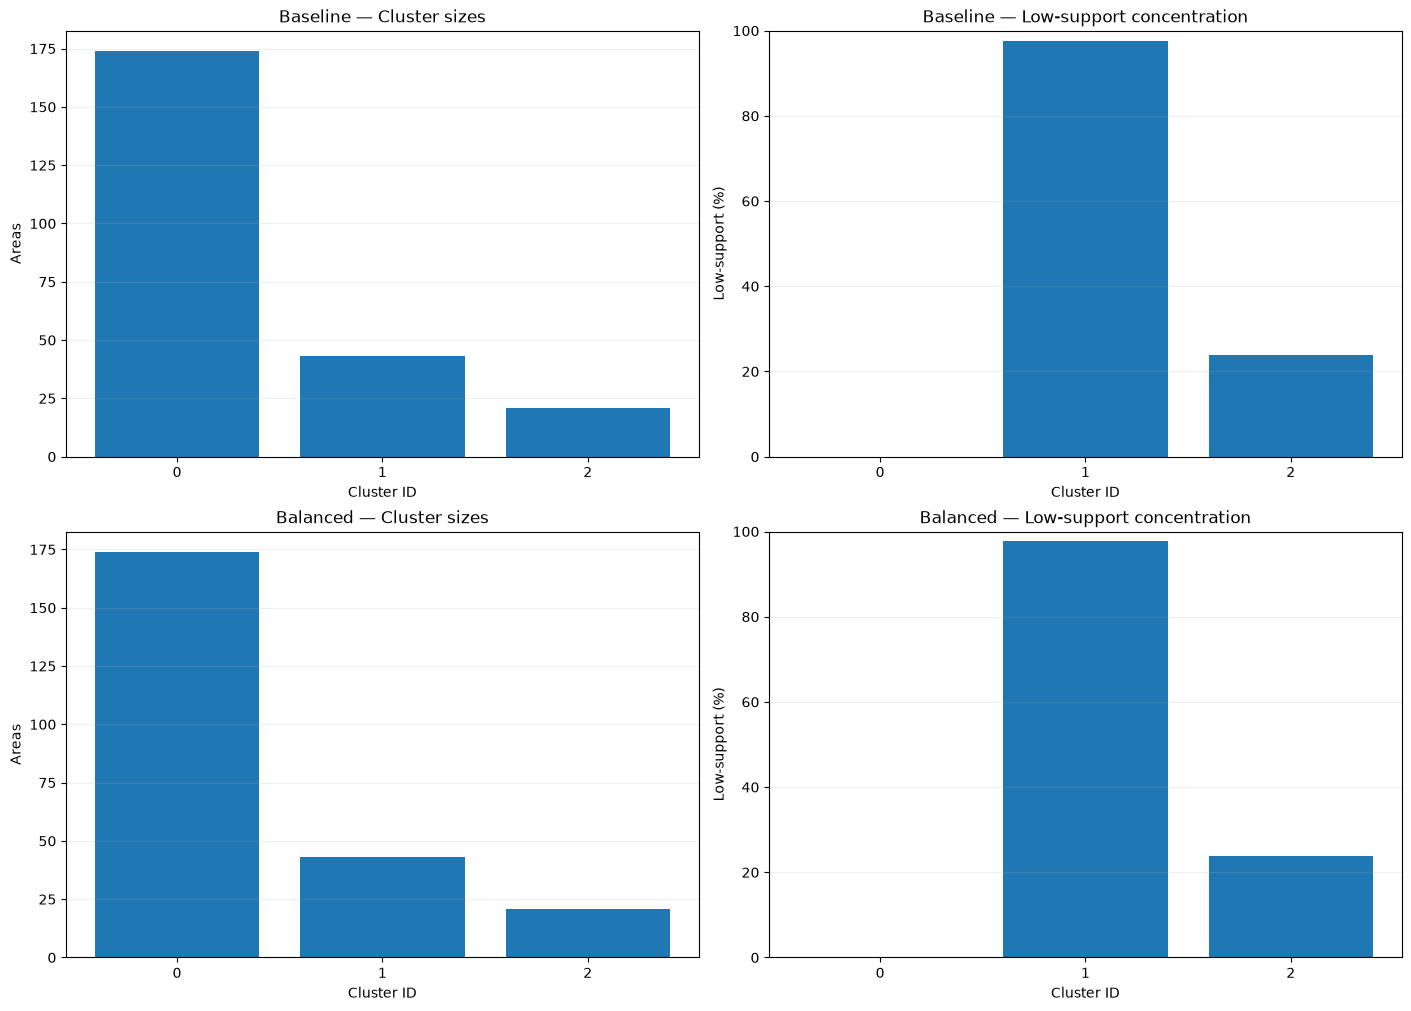

In [9]:
diagnostic_rows = []
for name, frame in cluster_results.items():
    for cid, group in frame.groupby("cluster_id"):
        low = int(group["low_support_flag"].sum())
        diagnostic_rows.append({
            "representation": name,
            "cluster_id": int(cid),
            "number_of_areas": len(group),
            "area_percentage": 100 * len(group) / len(frame),
            "low_support_areas": low,
            "low_support_percentage": 100 * low / len(group),
            "median_complaints": float(group["total_complaints"].median()),
            "min_complaints": int(group["total_complaints"].min()),
        })
diagnostics_all = pd.DataFrame(diagnostic_rows)
diagnostics_df = diagnostics_all[
    diagnostics_all["representation"].isin(["Baseline", "Balanced"])
].copy()
diagnostics_df.to_csv(KMEANS_TABLES_DIR / "k3_cluster_diagnostics.csv", index=False)
diagnostics_all.to_csv(KMEANS_TABLES_DIR / "k3_cluster_diagnostics_all_representations.csv", index=False)
display(diagnostics_all.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for i, name in enumerate(("Baseline", "Balanced")):
    subset = diagnostics_df[diagnostics_df["representation"] == name].sort_values("cluster_id")
    axes[i, 0].bar(subset["cluster_id"].astype(str), subset["number_of_areas"])
    axes[i, 0].set(title=f"{name} — Cluster sizes", xlabel="Cluster ID", ylabel="Areas")
    axes[i, 1].bar(subset["cluster_id"].astype(str), subset["low_support_percentage"])
    axes[i, 1].set(title=f"{name} — Low-support concentration", xlabel="Cluster ID", ylabel="Low-support (%)", ylim=(0, 100))
    for ax in axes[i]:
        ax.grid(axis="y", alpha=0.2)
fig.savefig(KMEANS_FIGURES_DIR / "k3_cluster_support_diagnostics.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Interpret cluster profiles in **original** units

Use unscaled `selected_modeling_features.csv` rather than transformed model inputs. Compare medians of volume, active months, variability, and recurrence; inspect category shares separately. **Do not name clusters before examining these new tables.**

In [10]:
profile_features = [
    "total_complaints", "active_months", "monthly_cv",
    "repeated_complaint_rate", "persistent_complaint_rate",
    "avg_recurrence_span_days",
]
profile_features = [c for c in profile_features if c in source_df.columns]
if not profile_features:
    raise ValueError("No interpretable original profile features found")
share_cols = sorted(c for c in source_df.columns if c.startswith("share_"))
if not share_cols:
    raise ValueError("Missing share_* complaint composition features")

cluster_profiles = {}
category_profiles = {}
for name, assigned in cluster_results.items():
    original_with_labels = source_df.merge(
        assigned[["area_id", "cluster_id"]], on="area_id",
        validate="one_to_one", how="inner",
    )
    if len(original_with_labels) != len(source_df):
        raise ValueError(f"Incomplete profile merge for {name}")
    medians = original_with_labels.groupby("cluster_id")[profile_features].median()
    means = original_with_labels.groupby("cluster_id")[share_cols].mean()
    cluster_profiles[name] = medians
    category_profiles[name] = means
    slug = name.lower().replace(" ", "_")
    medians.to_csv(KMEANS_TABLES_DIR / f"{slug}_k3_cluster_profiles.csv")
    means.to_csv(KMEANS_TABLES_DIR / f"{slug}_k3_category_profiles.csv")
    print(f"\n{name}: original-feature medians")
    display(medians.round(4))
    print(f"{name}: top categories by cluster")
    for cid, share_row in means.iterrows():
        print("  cluster", cid, ":", ", ".join(f"{c.removeprefix('share_')} {v:.1%}" for c, v in share_row.nlargest(3).items()))


Baseline: original-feature medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3473.5,36.0,0.2260,0.6624,0.3587,689.4356
1,5.0,4.0,3.0426,0.3333,0.0000,0.0000
2,82.0,23.0,1.3363,0.7500,0.6000,715.0093


Baseline: top categories by cluster
  cluster 0 : street_condition 30.8%, traffic_signal_condition 18.0%, street_light_condition 14.6%
  cluster 1 : street_condition 40.5%, sidewalk_condition 27.2%, street_light_condition 7.7%
  cluster 2 : street_condition 32.2%, street_light_condition 25.7%, traffic_signal_condition 25.0%

Balanced: original-feature medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3473.5,36.0,0.2260,0.6624,0.3587,689.4356
1,5.0,4.0,3.0426,0.3333,0.0000,0.0000
2,82.0,23.0,1.3363,0.7500,0.6000,715.0093


Balanced: top categories by cluster
  cluster 0 : street_condition 30.8%, traffic_signal_condition 18.0%, street_light_condition 14.6%
  cluster 1 : street_condition 40.5%, sidewalk_condition 27.2%, street_light_condition 7.7%
  cluster 2 : street_condition 32.2%, street_light_condition 25.7%, traffic_signal_condition 25.0%

Baseline PCA90: original-feature medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3471.0,36.0,0.2263,0.6615,0.3556,689.4644
1,5.0,4.0,3.0426,0.3333,0.0000,0.0000
2,71.0,22.5,1.3370,0.7917,0.6000,713.2377


Baseline PCA90: top categories by cluster
  cluster 0 : street_condition 30.9%, traffic_signal_condition 18.0%, street_light_condition 14.6%
  cluster 1 : street_condition 40.5%, sidewalk_condition 27.2%, street_light_condition 7.7%
  cluster 2 : street_condition 31.6%, traffic_signal_condition 25.8%, street_light_condition 25.6%

Balanced PCA90: original-feature medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,82.0,23.0,1.3363,0.7500,0.6000,715.0093
1,5.0,4.0,3.0426,0.3333,0.0000,0.0000
2,3473.5,36.0,0.2260,0.6624,0.3587,689.4356


Balanced PCA90: top categories by cluster
  cluster 0 : street_condition 32.2%, street_light_condition 25.7%, traffic_signal_condition 25.0%
  cluster 1 : street_condition 40.5%, sidewalk_condition 27.2%, street_light_condition 7.7%
  cluster 2 : street_condition 30.8%, traffic_signal_condition 18.0%, street_light_condition 14.6%


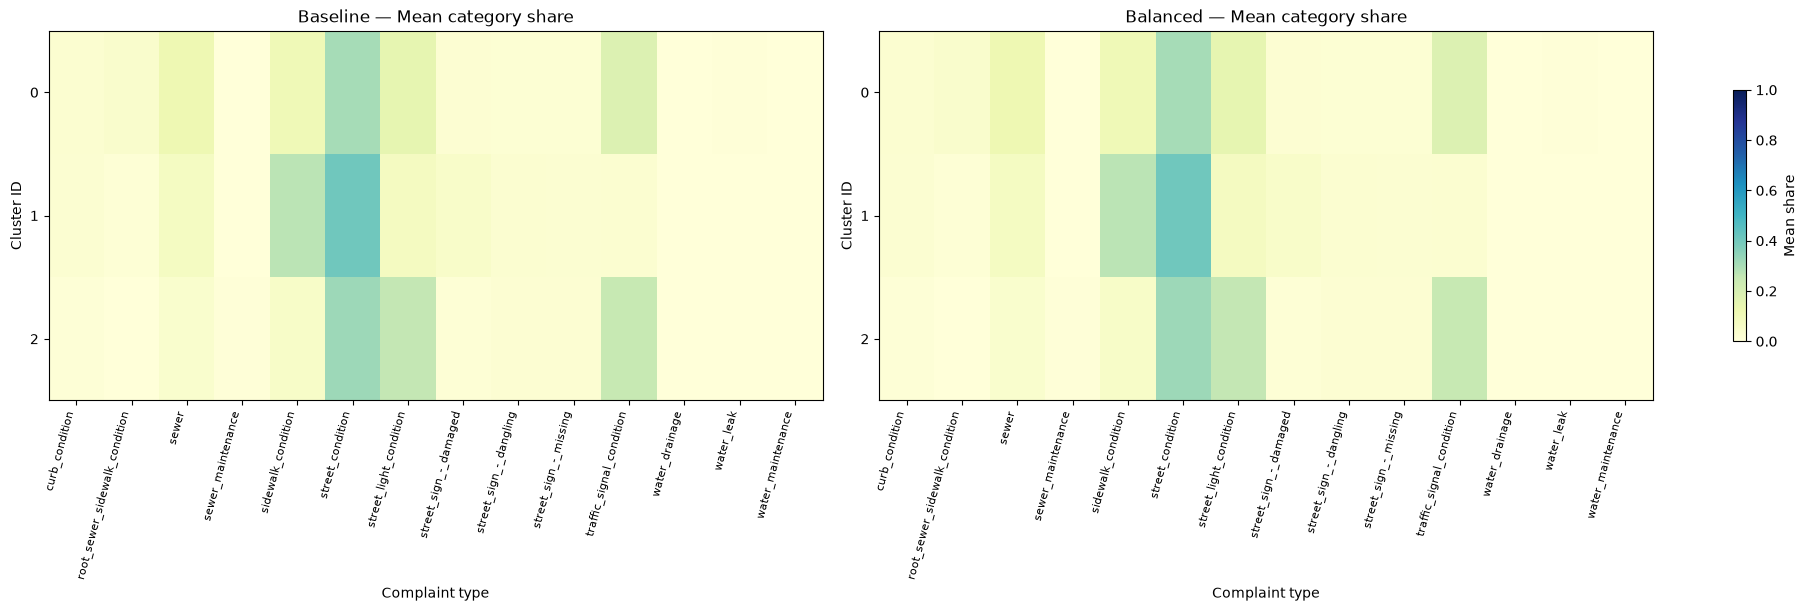

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)
for ax, name in zip(axes, ("Baseline", "Balanced")):
    composition = category_profiles[name]
    image = ax.imshow(composition.to_numpy(), aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
    ax.set_xticks(range(len(composition.columns)))
    ax.set_xticklabels([s.removeprefix("share_") for s in composition.columns], rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(len(composition.index)))
    ax.set_yticklabels(composition.index.astype(str))
    ax.set(title=f"{name} — Mean category share", xlabel="Complaint type", ylabel="Cluster ID")
fig.colorbar(image, ax=axes, shrink=0.68, label="Mean share")
fig.savefig(KMEANS_FIGURES_DIR / "k3_category_composition_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Cross-representation agreement

ARI = 1 denotes identical partitions (ignoring label permutations); ARI near 0 means agreement comparable with chance. Neither agreement nor separation alone guarantees meaningful infrastructure groups.

In [12]:
agreement_rows = []
for name_a, name_b in itertools.combinations(datasets.keys(), 2):
    a = cluster_results[name_a].set_index("area_id").loc[area_ids, "cluster_id"]
    b = cluster_results[name_b].set_index("area_id").loc[area_ids, "cluster_id"]
    agreement_rows.append({
        "representation_a": name_a, "representation_b": name_b,
        "adjusted_rand_index": adjusted_rand_score(a, b),
    })
agreement_df = pd.DataFrame(agreement_rows)
agreement_df.to_csv(KMEANS_TABLES_DIR / "k3_representation_agreement.csv", index=False)
display(agreement_df.round(4))
comparison = cluster_results["Baseline"][["area_id", "cluster_id"]].rename(columns={"cluster_id": "baseline_cluster"}).merge(
    cluster_results["Balanced"][["area_id", "cluster_id"]].rename(columns={"cluster_id": "balanced_cluster"}),
    on="area_id", validate="one_to_one",
)
comparison.to_csv(KMEANS_TABLES_DIR / "k3_membership_comparison.csv", index=False)
print("Baseline/Balanced membership cross-tab:")
display(pd.crosstab(comparison["baseline_cluster"], comparison["balanced_cluster"]))

,representation_a,representation_b,adjusted_rand_index
0,Baseline,Balanced,1.0000
1,Baseline,Baseline PCA90,0.9859
2,Baseline,Balanced PCA90,1.0000
3,Balanced,Baseline PCA90,0.9859
4,Balanced,Balanced PCA90,1.0000
5,Baseline PCA90,Balanced PCA90,0.9859


Baseline/Balanced membership cross-tab:


balanced_cluster,0,1,2
baseline_cluster,,,
0,174,0,0
1,0,43,0
2,0,0,21


## 7. Random-seed stability (K=3)

Fit K-Means at multiple seeds, compare partitions by ARI, and check sensitivity to initialization. Stability alone is not proof of substantive validity, particularly if clusters only reflect complaint volume.

In [13]:
STABILITY_SEEDS = [0, 1, 2, 3, 4, 5, 7, 11, 21, 42]
stability_rows = []
for name, X in datasets.items():
    sample_labels = []
    for seed in STABILITY_SEEDS:
        _, labels = fit_kmeans(X.to_numpy(dtype=float), K_CANDIDATE, seed=seed, n_init=10)
        sample_labels.append(labels)
    pairwise_aris = [
        adjusted_rand_score(sample_labels[i], sample_labels[j])
        for i, j in itertools.combinations(range(len(STABILITY_SEEDS)), 2)
    ]
    stability_rows.append({
        "representation": name, "k": K_CANDIDATE,
        "seeds": len(STABILITY_SEEDS),
        "mean_pairwise_ari": float(np.mean(pairwise_aris)),
        "min_pairwise_ari": float(np.min(pairwise_aris)),
        "max_pairwise_ari": float(np.max(pairwise_aris)),
    })
stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv(KMEANS_TABLES_DIR / "k3_random_seed_stability.csv", index=False)
display(stability_df.round(4))

,representation,k,seeds,mean_pairwise_ari,min_pairwise_ari,max_pairwise_ari
0,Baseline,3,10,1.0,1.0,1.0
1,Balanced,3,10,1.0,1.0,1.0
2,Baseline PCA90,3,10,1.0,1.0,1.0
3,Balanced PCA90,3,10,1.0,1.0,1.0


## 8. Low-support sensitivity: refit K=3 without sparse areas

A threshold of **30 complaints** is a sensitivity scenario matching the PCA audit, not a universal statistical requirement. Fit on higher-support areas only and compare their labels to labels from the full-data solution, restricted to those same areas. The raw baseline and balanced matrices are kept fixed to isolate the effect of excluding areas during K-Means fitting. A stronger future experiment could also refit preprocessing on the filtered population.

In [14]:
sensitivity_rows = []
kept_count = int(support_mask.sum())
removed_count = int((~support_mask).sum())
for name in ("Baseline", "Balanced"):
    full_labels = cluster_results[name].set_index("area_id").loc[area_ids, "cluster_id"].to_numpy()
    if kept_count <= K_CANDIDATE:
        sensitivity_rows.append({
            "representation": name, "areas_retained": kept_count,
            "areas_excluded": removed_count,
            "ari_full_vs_refit_on_retained": np.nan,
            "min_refit_cluster_size": np.nan,
            "note": "Too few higher-support areas for refit",
        })
        continue
    kept_matrix = datasets[name].to_numpy(dtype=float)[support_mask]
    refit, refit_labels = fit_kmeans(kept_matrix, K_CANDIDATE, n_init=50)
    counts = np.bincount(refit_labels, minlength=K_CANDIDATE)
    sensitivity_rows.append({
        "representation": name, "areas_retained": kept_count,
        "areas_excluded": removed_count,
        "ari_full_vs_refit_on_retained": float(adjusted_rand_score(full_labels[support_mask], refit_labels)),
        "min_refit_cluster_size": int(counts.min()),
        "note": "Only K-Means refitted; earlier feature transformations held fixed",
    })
sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv(KMEANS_TABLES_DIR / "k3_low_support_sensitivity.csv", index=False)
display(sensitivity_df.round(4))

,representation,areas_retained,areas_excluded,ari_full_vs_refit_on_retained,min_refit_cluster_size,note
0,Baseline,191,47,0.8863,9,Only K-Means refitted; earlier feature transfo...
1,Balanced,191,47,0.9189,9,Only K-Means refitted; earlier feature transfo...


## 9. Visualize the candidate partitions on the fitted PCA coordinates

Plots display **PCA projections** of the original representations, colored by K=3 assignments. K-Means itself was fitted in the original high-dimensional baseline/balanced spaces (or separately on PCA90 spaces), not on the two-dimensional plots.

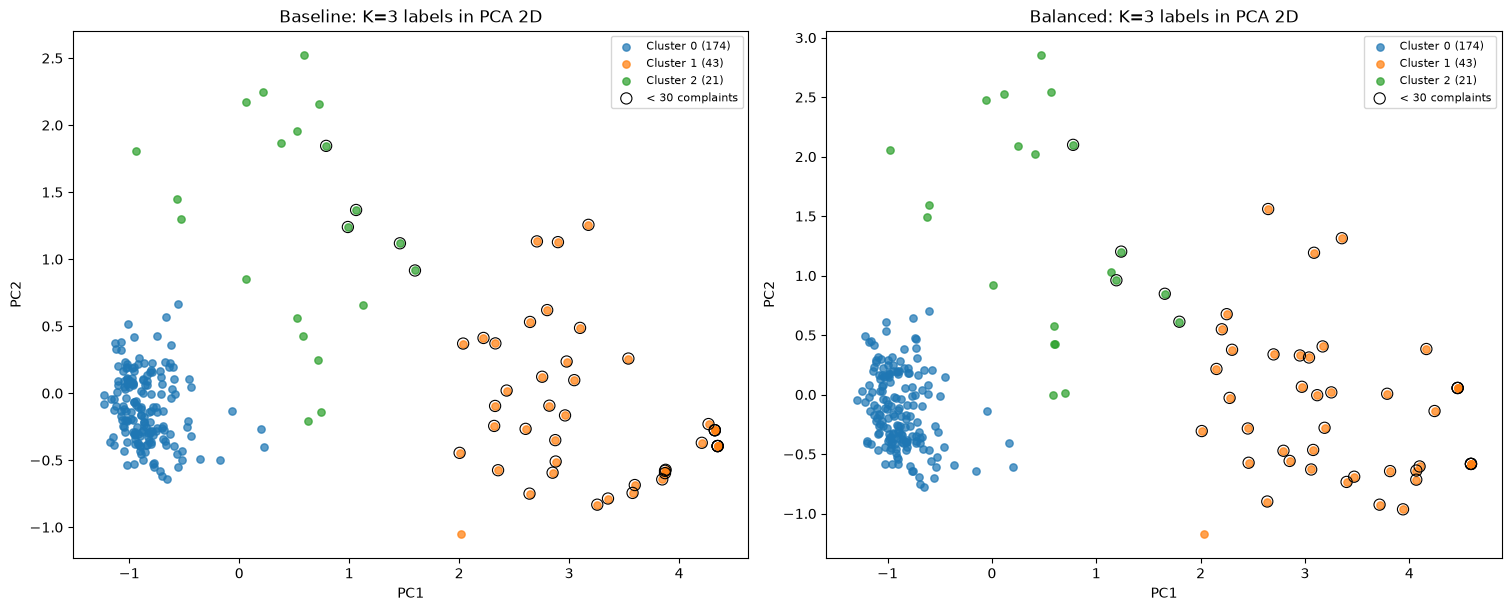

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, name in zip(axes, ("Baseline", "Balanced")):
    projection = pd.read_csv(PCA_TABLES_DIR / f"{name.lower()}_pca_2d.csv")
    labeled = projection.merge(
        cluster_results[name][["area_id", "cluster_id", "low_support_flag"]],
        on="area_id", validate="one_to_one",
    )
    for cid, group in labeled.groupby("cluster_id"):
        ax.scatter(group["PC1"], group["PC2"], s=28, alpha=0.72, label=f"Cluster {cid} ({len(group)})")
    sparse = labeled[labeled["low_support_flag"]]
    ax.scatter(sparse["PC1"], sparse["PC2"], facecolors="none", edgecolors="black", s=65, linewidth=0.8, label=f"< {LOW_SUPPORT_THRESHOLD} complaints")
    ax.set(title=f"{name}: K=3 labels in PCA 2D", xlabel="PC1", ylabel="PC2")
    ax.legend(fontsize=8)
fig.savefig(KMEANS_FIGURES_DIR / "k3_pca_projection_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Save candidate models and a reproducible run summary

K=3 models saved below are **candidate fits**, not an approved or automatically selected production solution. Keep the preprocessing and PCA artifacts alongside the model; a model applied to differently transformed features is invalid.

In [16]:
saved_model_rows = []
for name, model in candidate_models.items():
    slug = name.lower().replace(" ", "_")
    filepath = KMEANS_MODELS_DIR / f"{slug}_k3_kmeans_model.joblib"
    source_rep = "Balanced" if name.startswith("Balanced") else "Baseline"
    joblib.dump({
        "model": model,
        "representation": name,
        "k": K_CANDIDATE,
        "feature_order": list(datasets[name].columns),
        "training_area_count": len(area_ids),
        "random_state": RANDOM_STATE,
        "low_support_threshold": LOW_SUPPORT_THRESHOLD,
        "pca_source_model": pca_model_paths.get(name),
        "preprocessing_input_file": str(input_files[source_rep]),
        "status": "candidate_not_final",
    }, filepath)
    saved_model_rows.append({"representation": name, "model_path": str(filepath)})
model_manifest = pd.DataFrame(saved_model_rows)
model_manifest.to_csv(KMEANS_TABLES_DIR / "k3_model_manifest.csv", index=False)

summary_rows = [
    {"metric": "geographic_areas", "value": len(area_ids)},
    {"metric": "numerical_model_features", "value": len(feature_order)},
    {"metric": "complaint_category_share_features", "value": len(share_cols)},
    {"metric": "low_support_threshold", "value": LOW_SUPPORT_THRESHOLD},
    {"metric": "low_support_areas", "value": removed_count},
    {"metric": "candidate_k_detailed_analysis", "value": K_CANDIDATE},
    {"metric": "final_model_selected", "value": "NO — review comparative diagnostics"},
]
for _, row in candidate_summary_all.iterrows():
    slug = row["representation"].lower().replace(" ", "_")
    summary_rows.extend([
        {"metric": f"{slug}_best_k_silhouette", "value": int(row["best_k_silhouette"])},
        {"metric": f"{slug}_max_silhouette", "value": round(float(row["best_silhouette_value"]), 4)},
    ])
run_summary_df = pd.DataFrame(summary_rows)
run_summary_df.to_csv(KMEANS_TABLES_DIR / "kmeans_run_summary.csv", index=False)
display(run_summary_df)
print("\nALL K-MEANS INPUT AND OUTPUT INTEGRITY CHECKS PASSED")
print("Detailed K=3 models are saved as CANDIDATES; final K/model selection remains open.")
print("Tables:", KMEANS_TABLES_DIR)
print("Figures:", KMEANS_FIGURES_DIR)
print("Candidate models:", KMEANS_MODELS_DIR)

,metric,value
0,geographic_areas,238
1,numerical_model_features,19
2,complaint_category_share_features,14
3,low_support_threshold,30
4,low_support_areas,47
5,candidate_k_detailed_analysis,3
6,final_model_selected,NO — review comparative diagnostics
7,baseline_best_k_silhouette,2
8,baseline_max_silhouette,0.73
9,balanced_best_k_silhouette,2



ALL K-MEANS INPUT AND OUTPUT INTEGRITY CHECKS PASSED
Detailed K=3 models are saved as CANDIDATES; final K/model selection remains open.
Tables: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\kmeans
Figures: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\figures\kmeans
Candidate models: d:\Urban-Infrastructure-Pulse-Intelligence\models\kmeans


## 11. Interpretation checklist and next decision

Before finalizing a clustering approach, use the **newly generated** outputs (do not copy K=3 metrics or 174/34/6 cluster sizes from the previous 100K run):

1. **Candidate K:** Compare `candidate_k_summary_all_representations.csv` with the full K evaluation, considering silhouette/DB/CH **and** the size of the smallest and largest clusters.
2. **Initialization stability:** Inspect `k3_random_seed_stability.csv` (ARI), especially if K=3 isolates tiny groups.
3. **Sparse-area sensitivity:** Inspect `k3_low_support_sensitivity.csv` and `k3_cluster_diagnostics_all_representations.csv`. Sparse clusters indicate limited reporting evidence, not good infrastructure.
4. **Meaning:** Examine medians and category shares in `*_k3_cluster_profiles.csv` and `*_k3_category_profiles.csv`; compare recurring-location indicators with reporting volume.
5. **Agreement:** Read `k3_representation_agreement.csv`. ARI is invariant to label permutations.
6. **Limitations:** Reports are not ground-truth infrastructure condition; neither K-Means nor PCA establishes causal effects, true hotspots, or service blind spots by itself.

**Result:** This notebook provides an auditable comparison, preserves primary-area coverage, saves provisional models, and documents whether sparse or extreme ZIP/borough records disproportionately shape the clusters. Choose the final model only after inspecting the new findings.

# K-Means Clustering — Final Analysis Summary

## 1. Objective

K-Means clustering was applied to the NYC 311 infrastructure complaint dataset (2023–2025) to identify groups of ZIP/borough areas exhibiting similar infrastructure complaint-reporting patterns.

The clustering analysis considered complaint volume, temporal activity, recurrence, persistence, and complaint-category composition.

Four feature representations were compared to evaluate clustering quality, interpretability, stability, and the influence of sparsely reported geographic areas.

## 2. Dataset and Modeling Configuration

| Parameter | Result |
|---|---|
| Geographic areas | 238 |
| Numerical modeling features | 19 |
| Complaint-category share features | 14 |
| Clustering algorithm | K-Means |
| Candidate K values | 2–10 |
| Feature representations | 4 |
| Low-support threshold | Fewer than 30 complaints |
| Low-support areas | 47 (19.75%) |
| Data integrity checks | Passed |

The four evaluated representations were:

1. **Baseline:** Original transformed and scaled modeling features.
2. **Balanced:** Feature-group-balanced modeling features.
3. **Baseline PCA90:** Two principal components retaining 90.14% of variance.
4. **Balanced PCA90:** Five principal components retaining 90.69% of variance.

All representations used the same 238 geographic areas. Input alignment, numeric validity, and saved PCA artifact consistency were verified.

## 3. Optimal Number of Clusters

K-Means was evaluated for K values ranging from 2 to 10 using silhouette score, Davies–Bouldin index, Calinski–Harabasz index, inertia, and cluster-size diagnostics.

### Best K based on silhouette score

| Representation | Best K | Silhouette score |
|---|---:|---:|
| Baseline | 2 | 0.7300 |
| Balanced | 2 | 0.6745 |
| Baseline PCA90 | 2 | **0.7782** |
| Balanced PCA90 | 2 | 0.7164 |

**Key finding:** K=2 achieved the highest silhouette score in all four representations.

The Davies–Bouldin index also favored K=2 across all representations. The Calinski–Harabasz index favored K=2 in three representations and K=3 for Baseline PCA90.

These results provide consistent evidence that the feature space contains a strong two-group separation.

However, K=2 also produced an imbalanced partition of 193 and 45 areas, with the larger group containing 81.09% of all areas.

Therefore, the highest silhouette score alone is insufficient to establish the most useful clustering solution.

## 4. Detailed K=3 Evaluation

K=3 was retained as a candidate to investigate whether a more detailed segmentation provides additional insight.

### Clustering performance

| Representation | K=3 silhouette score |
|---|---:|
| Baseline | 0.6554 |
| Balanced | 0.5809 |
| Baseline PCA90 | **0.7244** |
| Balanced PCA90 | 0.6335 |

Baseline PCA90 again achieved the strongest silhouette score among the four representations at K=3.

Although K=3 performed less strongly than K=2 on silhouette score, its cluster profiles provided additional distinctions between geographic reporting patterns.

### Cluster distribution

The Baseline and Balanced representations produced identical K=3 cluster memberships.

| Cluster | Areas | Percentage | Median complaints |
|---|---:|---:|---:|
| Cluster 0 | 174 | 73.11% | 3,473.5 |
| Cluster 1 | 43 | 18.07% | 5 |
| Cluster 2 | 21 | 8.82% | 82 |

The Baseline PCA90 representation produced a similar distribution of 175, 43, and 20 areas.

Cluster sizes remained substantially imbalanced, with one dominant cluster and two smaller groups.

## 5. Interpretation of K=3 Cluster Profiles

Cluster profiles were interpreted using the original, unscaled modeling features.

### Cluster 0 — High-volume, consistently reporting areas

**174 areas (73.11%)**

| Indicator | Median |
|---|---:|
| Total complaints | 3,473.5 |
| Active months | 36 |
| Monthly coefficient of variation | 0.2260 |
| Repeated complaint rate | 0.6624 |
| Persistent complaint rate | 0.3587 |
| Average recurrence span | 689.44 days |

The cluster exhibited sustained complaint-reporting activity throughout the study period and relatively low month-to-month variability.

The most prominent complaint categories were Street Condition (30.8%), Traffic Signal Condition (18.0%), and Street Light Condition (14.6%).

**Interpretation:** These areas represent geographically established, consistently active complaint-reporting profiles. Higher reporting activity does not necessarily indicate worse infrastructure conditions.

### Cluster 1 — Very-low-volume and irregular reporting areas

**43 areas (18.07%)**

| Indicator | Median |
|---|---:|
| Total complaints | 5 |
| Active months | 4 |
| Monthly coefficient of variation | 3.0426 |
| Repeated complaint rate | 0.3333 |
| Persistent complaint rate | 0.0000 |
| Average recurrence span | 0 days |

This cluster exhibited very limited complaint activity and substantial temporal concentration.

The most prominent complaint categories were Street Condition (40.5%), Sidewalk Condition (27.2%), and Street Light Condition (7.7%).

**Interpretation:** These areas represent sparse and irregular reporting profiles. The absence of observed persistence may reflect insufficient reporting evidence rather than the absence of recurring infrastructure issues.

### Cluster 2 — Moderate-volume reporting with high observed recurrence

**21 areas (8.82%)**

| Indicator | Median |
|---|---:|
| Total complaints | 82 |
| Active months | 23 |
| Monthly coefficient of variation | 1.3363 |
| Repeated complaint rate | 0.7500 |
| Persistent complaint rate | 0.6000 |
| Average recurrence span | 715.01 days |

This cluster exhibited intermediate complaint volumes, greater temporal variability than Cluster 0, and higher observed repeated and persistent complaint rates.

Its most prominent categories were Street Condition (32.2%), Street Light Condition (25.7%), and Traffic Signal Condition (25.0%).

**Interpretation:** These areas represent moderate-volume profiles with relatively concentrated recurrence and persistence indicators. Their observed patterns warrant further investigation but do not establish confirmed recurring infrastructure defects.

## 6. Cross-Representation Agreement

Adjusted Rand Index (ARI) was used to compare cluster membership across feature representations.

| Comparison | ARI |
|---|---:|
| Baseline vs. Balanced | 1.0000 |
| Baseline vs. Baseline PCA90 | 0.9859 |
| Baseline vs. Balanced PCA90 | 1.0000 |
| Balanced vs. Balanced PCA90 | 1.0000 |

**Key finding:** The four K=3 representations produced highly similar cluster memberships.

Baseline and Balanced assigned all 238 areas to identical groups. Balanced PCA90 also produced the same partition after accounting for arbitrary cluster-label numbering.

Baseline PCA90 differed slightly, with an ARI of 0.9859 relative to the other representations.

This indicates that the main clustering structure is largely preserved across the evaluated transformations.

However, high agreement may also reflect the dominance of complaint volume and temporal variability across representations.

## 7. Random-Seed Stability

K=3 was fitted repeatedly using ten random seeds.

| Representation | Mean pairwise ARI | Minimum ARI |
|---|---:|---:|
| Baseline | 1.0000 | 1.0000 |
| Balanced | 1.0000 | 1.0000 |
| Baseline PCA90 | 1.0000 | 1.0000 |
| Balanced PCA90 | 1.0000 | 1.0000 |

All tested representations achieved perfect agreement across the ten random-seed runs.

**Interpretation:** The K=3 assignments were stable under the tested initialization settings.

This supports computational reproducibility, but does not establish that the clusters correspond to meaningful underlying infrastructure conditions.

## 8. Impact of Low-Support Geographic Areas

The earlier PCA analysis identified sparse reporting as a potential source of distortion. The K-Means analysis therefore examined areas with fewer than 30 complaints.

### Distribution of low-support areas

| Cluster | Total areas | Low-support areas | Low-support share |
|---|---:|---:|---:|
| Cluster 0 | 174 | 0 | 0.00% |
| Cluster 1 | 43 | 42 | 97.67% |
| Cluster 2 | 21 | 5 | 23.81% |

A total of 47 areas fell below the 30-complaint threshold.

Of these, 42 were concentrated in Cluster 1.

**Key finding:** Cluster 1 is almost entirely composed of low-support areas. Its separation is therefore strongly associated with sparse complaint activity.

This finding is especially important because low reporting cannot be interpreted directly as low infrastructure need or good infrastructure performance.

### Sensitivity analysis

K-Means was refitted after excluding the 47 low-support areas.

| Metric | Baseline | Balanced |
|---|---:|---:|
| Areas retained | 191 | 191 |
| Areas excluded | 47 | 47 |
| Full vs. refitted partition ARI | 0.8863 | 0.9189 |
| Smallest refitted cluster | 9 | 9 |

The retained-area partitions remained reasonably similar to the original clustering, but membership changed.

This demonstrates that sparse areas influence the fitted K-Means structure.

The sensitivity experiment kept the earlier feature transformations fixed and refitted only K-Means. It therefore represents a partial robustness check, not a complete retraining of the entire preprocessing pipeline.

## 9. Main Findings

The analysis produced five major findings.

**Finding 1 — K=2 provides stronger numerical separation.**

All four representations achieved their highest silhouette scores at K=2. Baseline PCA90 achieved the highest observed silhouette score of 0.7782.

**Finding 2 — K=3 reveals additional reporting-profile distinctions.**

K=3 separated areas into high-volume consistent reporting, very-low-volume irregular reporting, and moderate-volume reporting with relatively high recurrence indicators.

**Finding 3 — Cluster memberships are highly reproducible.**

The evaluated K=3 partitions showed strong cross-representation agreement and perfect stability across the tested initialization seeds.

**Finding 4 — Sparse areas substantially affect clustering.**

Almost 98% of Cluster 1 contained areas with fewer than 30 complaints. Excluding these areas changed the fitted clustering partitions.

**Finding 5 — Reporting intensity remains a dominant clustering dimension.**

The strong differences in total complaints, active months, and monthly variability suggest that clustering is largely separating areas by reporting intensity and continuity, rather than infrastructure complaint composition alone.

## 10. Limitations

Several limitations must be considered when interpreting these results.

- NYC 311 complaints reflect public reporting behaviour and service-request activity, not direct measurements of infrastructure quality.
- Complaint totals are not normalized by population, infrastructure exposure, or service demand.
- ZIP-level grouping may include sparse or geographically unusual identifiers.
- The 30-complaint threshold is a sensitivity-analysis choice rather than a universally validated minimum.
- High silhouette scores can reflect strong separation between reporting-volume groups without establishing useful infrastructure subtypes.
- K-Means assumes distance-based, approximately compact clusters and may not represent irregular geographic patterns.
- Silhouette scores across differently transformed feature spaces are informative but not strictly equivalent measures of real-world usefulness.
- Recurrence metrics identify repeated reports near similar coordinates, not independently verified unresolved defects.

## 11. Model Selection and Next Steps

The current experiments do not justify automatically selecting either K=2 or K=3 as the final model.

K=2 offers stronger internal clustering metrics, while K=3 provides an additional reporting-pattern distinction.

Further validation should examine whether the clusters remain interpretable after reducing the influence of low-support areas and complaint volume.

Recommended next evaluations include:

1. Comparing K=2 and K=3 profiles for the 191 higher-support areas.
2. Testing whether complaint-category composition produces meaningful distinctions beyond reporting volume.
3. Evaluating alternative feature weighting and volume-normalized indicators.
4. Examining geographic plausibility and reporting coverage.
5. Comparing the resulting area groups with hierarchical clustering and future spatial analyses.

The saved K=3 models should continue to be treated as **candidate models**, not finalized production clustering solutions.

## 12. Final Conclusion

K-Means successfully identified reproducible groupings among 238 NYC ZIP/borough areas using 19 numerical infrastructure complaint-reporting features.

The analysis found that K=2 provided the strongest internal clustering metrics, particularly with the two-component Baseline PCA90 representation.

The K=3 solution revealed three interpretable reporting profiles, but these were strongly differentiated by complaint volume, temporal activity, and reporting support.

Cross-representation agreement and random-seed stability were high, while the low-support sensitivity experiment demonstrated that sparse areas influence cluster structure.

**Overall, the main contribution of K-Means is the systematic discovery and comparison of multidimensional infrastructure complaint-reporting profiles. The results should be viewed as exploratory geographic reporting patterns, not confirmed infrastructure condition rankings, hotspots, or service blind spots.**

The next stage should prioritize robustness, alternative clustering approaches, and spatial validation before drawing stronger infrastructure-planning conclusions.

Keep both K=2 and K=3 as candidates.  next important experiment is clustering the 191 higher-support areas and examining whether meaningful differences remain once sparse reporting is less influential. That will strengthen the machine-learning justification of 
 project.

We will now compare two candidate models in the same notebook. Your current notebook already evaluates four feature representations:
- Baseline
- Balanced
- Baseline PCA90
- Balanced PCA90
The full-data results show a best Silhouette Score of 0.7782 for Baseline PCA90 at K=2, but K=3 gives an additional reporting-profile distinction.

Our immediate question is:

Does K=3 reveal meaningful reporting behaviour that K=2 combines into a larger cluster?


K=2 Versus K=3 Model Comparison

### Objective

Compare K=2 and K=3 clustering solutions across all four feature representations.

### Evaluation Criteria

- Silhouette Score
- Davies–Bouldin Index
- Cluster-size imbalance
- Low-support concentration
- Cluster agreement between K=2 and K=3
- Original-feature interpretability

### Methodological Decision

All 238 geographic areas remain included in the primary analysis.

The threshold of 30 complaints is used only for sensitivity and reliability diagnostics.

K=2 and K=3 remain candidate models until the final comparison is completed.


In [17]:
#Train and compare candidate models
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)
import numpy as np
import pandas as pd

K_COMPARE = [2, 3]

comparison_models = {}
comparison_labels = {}
comparison_rows = []

for name, X in datasets.items():

    matrix = X.to_numpy(dtype=float)

    for k in K_COMPARE:

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=50,
            random_state=42,
            max_iter=500
        )

        labels = model.fit_predict(matrix)

        sizes = np.bincount(labels, minlength=k)

        key = (name, k)

        comparison_models[key] = model
        comparison_labels[key] = labels

        comparison_rows.append({
            "representation": name,
            "k": k,
            "silhouette": silhouette_score(
                matrix, labels
            ),
            "davies_bouldin": davies_bouldin_score(
                matrix, labels
            ),
            "min_cluster_size": int(sizes.min()),
            "max_cluster_size": int(sizes.max()),
            "largest_cluster_pct": (
                100 * sizes.max() / len(labels)
            ),
            "cluster_sizes": str(sorted(sizes.tolist()))
        })

k2_k3_comparison = pd.DataFrame(comparison_rows)

display(k2_k3_comparison.round(4))

k2_k3_comparison.to_csv(
    KMEANS_TABLES_DIR / "k2_k3_comparison.csv",
    index=False
)

,representation,k,silhouette,davies_bouldin,min_cluster_size,max_cluster_size,largest_cluster_pct,cluster_sizes
0,Baseline,2,0.7300,0.5154,45,193,81.0924,"[45, 193]"
1,Baseline,3,0.6554,0.8215,21,174,73.1092,"[21, 43, 174]"
2,Balanced,2,0.6745,0.6821,45,193,81.0924,"[45, 193]"
3,Balanced,3,0.5809,1.0820,21,174,73.1092,"[21, 43, 174]"
4,Baseline PCA90,2,0.7782,0.3700,45,193,81.0924,"[45, 193]"
5,Baseline PCA90,3,0.7244,0.6082,20,175,73.5294,"[20, 43, 175]"
6,Balanced PCA90,2,0.7164,0.5690,45,193,81.0924,"[45, 193]"
7,Balanced PCA90,3,0.6335,0.9031,21,174,73.1092,"[21, 43, 174]"


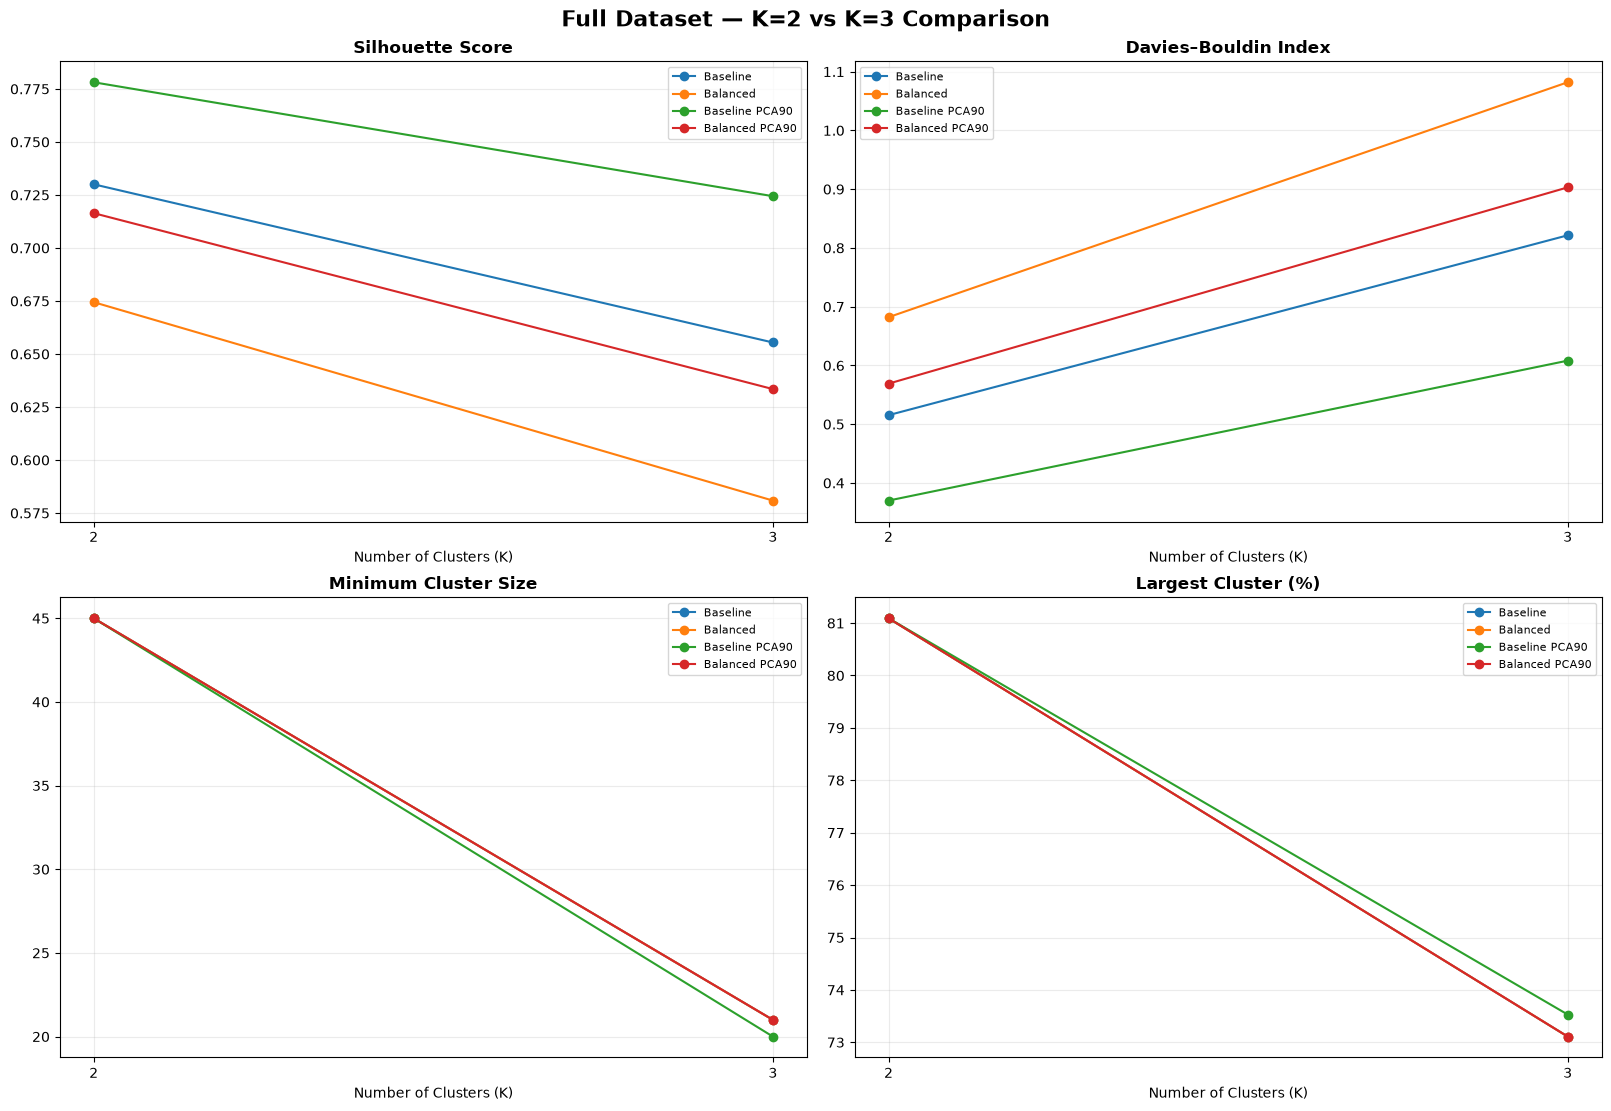

In [18]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

metrics = [
    ("silhouette", "Silhouette Score"),
    ("davies_bouldin", "Davies–Bouldin Index"),
    ("min_cluster_size", "Minimum Cluster Size"),
    ("largest_cluster_pct", "Largest Cluster (%)")
]

for ax, (metric, title) in zip(axes.flat, metrics):

    for name in datasets:

        sub = k2_k3_comparison[
            k2_k3_comparison["representation"] == name
        ].sort_values("k")

        ax.plot(
            sub["k"],
            sub[metric],
            marker="o",
            label=name
        )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_xticks(K_COMPARE)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Full Dataset — K=2 vs K=3 Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.savefig(
    KMEANS_FIGURES_DIR / "k2_vs_k3_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
#Examine how K=2 splits into K=3
from sklearn.metrics import adjusted_rand_score

for name in datasets:

    labels_k2 = comparison_labels[(name, 2)]
    labels_k3 = comparison_labels[(name, 3)]

    print(f"\n{name.upper()} — K=2 VS K=3")

    transition = pd.crosstab(
        pd.Series(labels_k2, name="K2_cluster"),
        pd.Series(labels_k3, name="K3_cluster")
    )

    display(transition)

    print(
        "Adjusted Rand Index:",
        round(
            adjusted_rand_score(labels_k2, labels_k3),
            4
        )
    )

    transition.to_csv(
        KMEANS_TABLES_DIR /
        f"{name.lower().replace(' ', '_')}_k2_k3_transition.csv"
    )


BASELINE — K=2 VS K=3


K3_cluster,0,1,2
K2_cluster,,,
0,174,0,19
1,0,43,2


Adjusted Rand Index: 0.7423

BALANCED — K=2 VS K=3


K3_cluster,0,1,2
K2_cluster,,,
0,174,0,19
1,0,43,2


Adjusted Rand Index: 0.7423

BASELINE PCA90 — K=2 VS K=3


K3_cluster,0,1,2
K2_cluster,,,
0,175,0,18
1,0,43,2


Adjusted Rand Index: 0.7531

BALANCED PCA90 — K=2 VS K=3


K3_cluster,0,1,2
K2_cluster,,,
0,19,0,174
1,2,43,0


Adjusted Rand Index: 0.7423


In [20]:
profile_cols = [
    "total_complaints",
    "active_months",
    "monthly_cv",
    "repeated_complaint_rate",
    "persistent_complaint_rate",
    "avg_recurrence_span_days"
]

profile_cols = [
    c for c in profile_cols
    if c in source_df.columns
]

for name in datasets:

    for k in K_COMPARE:

        labels = comparison_labels[(name, k)]

        temp = source_df.copy()
        temp["cluster_id"] = labels

        summary = temp.groupby(
            "cluster_id"
        )[profile_cols].median()

        print(f"\n{name} — K={k} Original Feature Medians")
        display(summary.round(4))

        summary.to_csv(
            KMEANS_TABLES_DIR /
            f"{name.lower().replace(' ', '_')}_k{k}_profile_comparison.csv"
        )


Baseline — K=2 Original Feature Medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3343.0,36.0,0.2305,0.6641,0.3636,693.368
1,5.0,4.0,2.8685,0.3333,0.0000,0.000



Baseline — K=3 Original Feature Medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3473.5,36.0,0.2260,0.6624,0.3587,689.4356
1,5.0,4.0,3.0426,0.3333,0.0000,0.0000
2,82.0,23.0,1.3363,0.7500,0.6000,715.0093



Balanced — K=2 Original Feature Medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3343.0,36.0,0.2305,0.6641,0.3636,693.368
1,5.0,4.0,2.8685,0.3333,0.0000,0.000


... (6 outputs left out)


Balanced PCA90 — K=2 Original Feature Medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,3343.0,36.0,0.2305,0.6641,0.3636,693.368
1,5.0,4.0,2.8685,0.3333,0.0000,0.000



Balanced PCA90 — K=3 Original Feature Medians


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
cluster_id,,,,,,
0,82.0,23.0,1.3363,0.7500,0.6000,715.0093
1,5.0,4.0,3.0426,0.3333,0.0000,0.0000
2,3473.5,36.0,0.2260,0.6624,0.3587,689.4356



## K=2 — Original Feature Cluster Profiles

| Metric | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Geographic Areas | 193 | 45 |
| Median Total Complaints | 3343.0 | 5.0 |
| Median Active Months | 36.0 | 4.0 |
| Median Monthly CV | 0.2305 | 2.8685 |
| Median Repeated Complaint Rate | 0.6641 | 0.3333 |
| Median Persistent Complaint Rate | 0.3636 | 0.0000 |
| Median Recurrence Span (Days) | 693.3680 | 0.0000 |
| Provisional Profile | Sustained High-Volume Reporting | Sparse Irregular Reporting |


Interpretation
Cluster 0 — Sustained High-Volume Reporting

These areas have many complaints and active reporting throughout the 36-month observation window. They also show considerable complaint recurrence.

Cluster 1 — Sparse Irregular Reporting

These areas have very few complaints, limited active months and high monthly variability.

A zero median persistence rate does not necessarily mean infrastructure problems are absent. There may simply be insufficient observations to establish persistence.


## K=3 — Original Feature Cluster Profiles

| Metric | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---:|---:|---:|
| Geographic Areas | 174 | 43 | 21 |
| Median Total Complaints | 3473.5 | 5.0 | 82.0 |
| Median Active Months | 36.0 | 4.0 | 23.0 |
| Median Monthly CV | 0.2260 | 3.0426 | 1.3363 |
| Median Repeated Complaint Rate | 0.6624 | 0.3333 | 0.7500 |
| Median Persistent Complaint Rate | 0.3587 | 0.0000 | 0.6000 |
| Median Recurrence Span (Days) | 689.4356 | 0.0000 | 715.0093 |
| Provisional Profile | Sustained High-Volume Reporting | Sparse Irregular Reporting | Lower-Volume High-Persistence Reporting |



## K-Means Model Selection — Current Assessment

| Criterion | K=2 | K=3 |
|---|---|---|
| Silhouette Score | Higher | Lower |
| Davies-Bouldin Index | Better | Worse |
| Cluster Separation | Stronger | Weaker |
| Cluster Interpretability | Two broad profiles | Three more detailed profiles |
| Separate High-Persistence Group | No | Yes |
| Low-Support Influence | Requires further validation | Requires further validation |
| Final Selection | Pending | Pending |



## Original-Feature Cluster Interpretation

### Objective

Investigate whether the best-performing K=2 solution represents meaningful differences in infrastructure reporting behaviour or primarily separates areas with sparse complaint records.

### Approach

- Preserve all 238 geographic areas.
- Match cluster assignments using area_id.
- Compare K=2 and K=3 using Baseline PCA90.
- Examine complaint volume, recurrence, persistence, and temporal behaviour.
- Measure low-support concentration without excluding areas.
- Review the infrastructure complaint composition before assigning permanent cluster labels.


In [21]:
import numpy as np
import pandas as pd

REPRESENTATION = "Baseline PCA90"
LOW_SUPPORT_THRESHOLD = 30

# Confirm the original source data contains unique areas
assert source_df["area_id"].is_unique
assert baseline_df["area_id"].is_unique

assert set(source_df["area_id"]) == set(
    baseline_df["area_id"]
)

# Align original features to the model input area ordering
source_aligned = (
    baseline_df[["area_id"]]
    .merge(
        source_df,
        on="area_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(source_aligned) == 238
assert source_aligned["total_complaints"].notna().all()

# PCA matrices must have been produced without
# reordering the baseline input rows.
# Verify this against the PCA creation cell.
assert len(datasets[REPRESENTATION]) == len(source_aligned)

profile_features = [
    "total_complaints",
    "active_months",
    "monthly_cv",
    "repeated_complaint_rate",
    "persistent_complaint_rate",
    "avg_recurrence_span_days"
]

profile_results = {}
profile_tables = []

for k in [2, 3]:

    labels = comparison_labels[(REPRESENTATION, k)]

    df_profile = source_aligned.copy()
    df_profile["cluster_id"] = labels

    df_profile["low_support_flag"] = (
        df_profile["total_complaints"]
        < LOW_SUPPORT_THRESHOLD
    )

    profile_results[k] = df_profile

    summary = df_profile.groupby("cluster_id").agg(
        areas=("area_id", "size"),
        median_complaints=("total_complaints", "median"),
        median_active_months=("active_months", "median"),
        median_monthly_cv=("monthly_cv", "median"),
        median_repeat_rate=(
            "repeated_complaint_rate", "median"
        ),
        median_persistence=(
            "persistent_complaint_rate", "median"
        ),
        median_recurrence_days=(
            "avg_recurrence_span_days", "median"
        ),
        low_support_areas=("low_support_flag", "sum")
    )

    summary["low_support_pct"] = (
        100 * summary["low_support_areas"]
        / summary["areas"]
    )

    summary.insert(0, "k", k)

    profile_tables.append(
        summary.reset_index()
    )

    print(f"\nBASELINE PCA90 — K={k}")
    display(summary.round(4))

full_profile_comparison = pd.concat(
    profile_tables,
    ignore_index=True
)

full_profile_comparison.to_csv(
    KMEANS_TABLES_DIR
    / "baseline_pca90_k2_k3_profiles.csv",
    index=False
)


BASELINE PCA90 — K=2


,k,areas,median_complaints,median_active_months,median_monthly_cv,median_repeat_rate,median_persistence,median_recurrence_days,low_support_areas,low_support_pct
cluster_id,,,,,,,,,,
0,2,193,3343.0,36.0,0.2305,0.6641,0.3636,693.368,3,1.5544
1,2,45,5.0,4.0,2.8685,0.3333,0.0000,0.000,44,97.7778



BASELINE PCA90 — K=3


,k,areas,median_complaints,median_active_months,median_monthly_cv,median_repeat_rate,median_persistence,median_recurrence_days,low_support_areas,low_support_pct
cluster_id,,,,,,,,,,
0,3,175,3471.0,36.0,0.2263,0.6615,0.3556,689.4644,0,0.0000
1,3,43,5.0,4.0,3.0426,0.3333,0.0000,0.0000,42,97.6744
2,3,20,71.0,22.5,1.3370,0.7917,0.6000,713.2377,5,25.0000


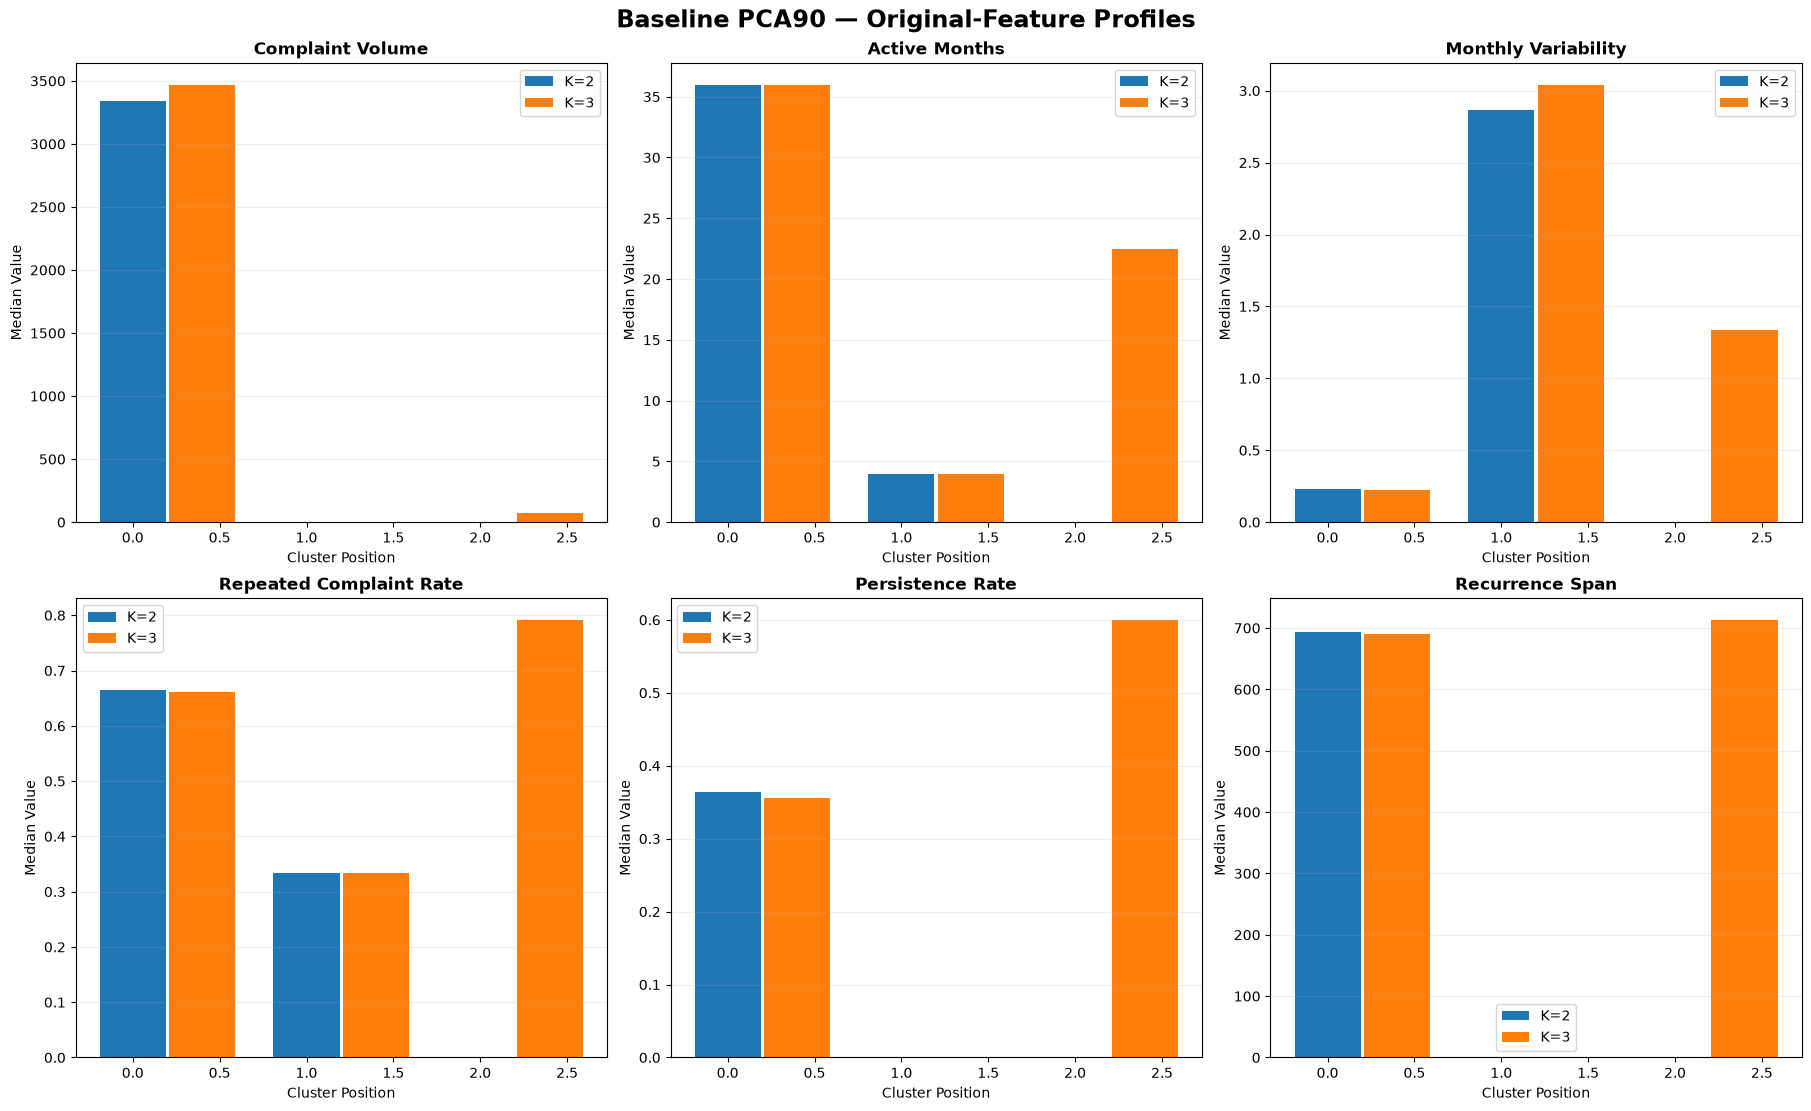

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    ("total_complaints", "Complaint Volume"),
    ("active_months", "Active Months"),
    ("monthly_cv", "Monthly Variability"),
    ("repeated_complaint_rate", "Repeated Complaint Rate"),
    ("persistent_complaint_rate", "Persistence Rate"),
    ("avg_recurrence_span_days", "Recurrence Span")
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11),
    constrained_layout=True
)

for ax, (feature, title) in zip(axes.flat, features):

    for k in [2, 3]:

        medians = (
            profile_results[k]
            .groupby("cluster_id")[feature]
            .median()
        )

        x_positions = (
            np.arange(len(medians))
            + (k - 2) * 0.4
        )

        ax.bar(
            x_positions,
            medians.values,
            width=0.38,
            label=f"K={k}"
        )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Cluster Position")
    ax.set_ylabel("Median Value")
    ax.grid(axis="y", alpha=0.2)
    ax.legend()

fig.suptitle(
    "Baseline PCA90 — Original-Feature Profiles",
    fontsize=17,
    fontweight="bold"
)

plt.savefig(
    KMEANS_FIGURES_DIR
    / "baseline_pca90_k2_k3_feature_profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

We should not choose K=3 merely because it produces a more interesting label. Nor should we choose K=2 solely because its Silhouette Score is higher.

### Check Low-Support Concentration in Both Models


##  K-Means Low-Support Cluster Diagnostics

### Objective

Evaluate whether K=2 and K=3 cluster assignments are disproportionately influenced by geographic areas with limited complaint records.

### Methodology

- Use Baseline PCA90 for the primary candidate comparison.
- Retain all 238 geographic areas.
- Flag areas containing fewer than 30 complaints.
- Compare low-support concentration across K=2 and K=3.
- Examine complaint-volume distributions within clusters.
- Do not automatically exclude low-support observations.

The threshold of 30 complaints is a diagnostic choice, not an exclusion rule.


In [23]:
import pandas as pd
import numpy as np

support_diagnostics = []

for k in [2, 3]:

    df = profile_results[k].copy()

    for cluster_id, group in df.groupby("cluster_id"):

        n = len(group)

        low_support = (
            group["total_complaints"] < 30
        ).sum()

        support_diagnostics.append({
            "k": k,
            "cluster_id": cluster_id,
            "number_of_areas": n,
            "percentage_of_areas": 100 * n / len(df),
            "low_support_areas": int(low_support),
            "low_support_pct": 100 * low_support / n,
            "minimum_complaints": group["total_complaints"].min(),
            "median_complaints": group["total_complaints"].median(),
            "maximum_complaints": group["total_complaints"].max()
        })

support_comparison_df = pd.DataFrame(
    support_diagnostics
)

display(support_comparison_df.round(2))

support_comparison_df.to_csv(
    KMEANS_TABLES_DIR /
    "k2_k3_low_support_comparison.csv",
    index=False
)

,k,cluster_id,number_of_areas,percentage_of_areas,low_support_areas,low_support_pct,minimum_complaints,median_complaints,maximum_complaints
0,2,0,193,81.09,3,1.55,15,3343.0,10646
1,2,1,45,18.91,44,97.78,1,5.0,30
2,3,0,175,73.53,0,0.00,89,3471.0,10646
3,3,1,43,18.07,42,97.67,1,5.0,30
4,3,2,20,8.40,5,25.00,11,71.0,830


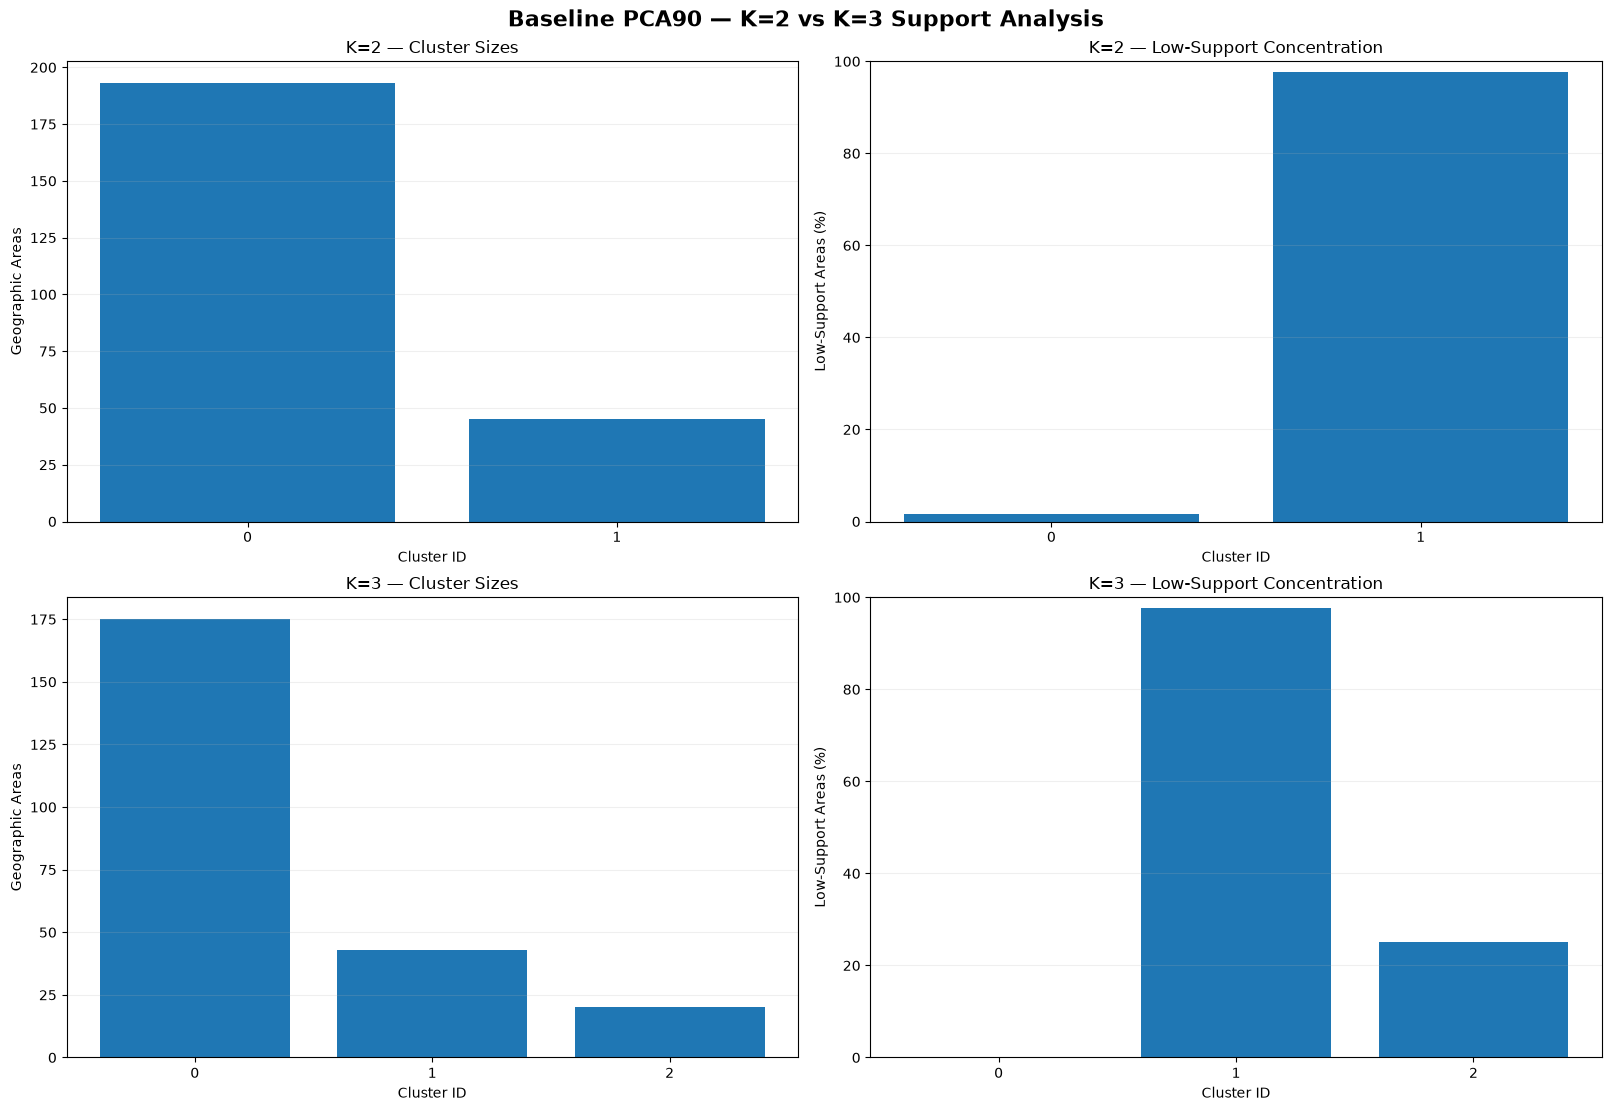

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

for row, k in enumerate([2, 3]):

    df = profile_results[k].copy()

    sizes = df.groupby("cluster_id").size()

    low_support_pct = (
        df.groupby("cluster_id")["low_support_flag"]
        .mean() * 100
    )

    axes[row, 0].bar(
        sizes.index.astype(str),
        sizes.values
    )

    axes[row, 0].set_title(
        f"K={k} — Cluster Sizes"
    )

    axes[row, 0].set_ylabel("Geographic Areas")
    axes[row, 0].set_xlabel("Cluster ID")

    axes[row, 1].bar(
        low_support_pct.index.astype(str),
        low_support_pct.values
    )

    axes[row, 1].set_title(
        f"K={k} — Low-Support Concentration"
    )

    axes[row, 1].set_ylabel("Low-Support Areas (%)")
    axes[row, 1].set_xlabel("Cluster ID")
    axes[row, 1].set_ylim(0, 100)

    for ax in axes[row]:
        ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Baseline PCA90 — K=2 vs K=3 Support Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.savefig(
    KMEANS_FIGURES_DIR /
    "k2_k3_support_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## K-Means — Low-Support Diagnostics

| K | Cluster ID | Areas | Low-Support Areas | Low-Support Percentage | Median Complaints |
|---|---:|---:|---:|---:|---:|
| 2 | 0 | 193 | 3 | 1.55% | 3343 |
| 2 | 1 | 45 | 44 | 97.78% | 5 |
| 3 | 0 | 175 | 0 | 0.00% | 3471 |
| 3 | 1 | 43 | 42 | 97.67% | 5 |
| 3 | 2 | 20 | 5 | 25.00% | 71 |


Interpretation of the clustering solutions
K=2 — Strong separation, limited behavioral detail
- 193
areas
- Cluster 0 — Sustained Reporting

- Median 3,343 complaints, 36 active months, relatively low monthly variability and considerable recurrence.



- 45
 areas
- Cluster 1 — Sparse Reporting

- Median 5 complaints, 4 active months and 97.78% of areas below our diagnostic support threshold.



- This helps explain why K=2 achieved such a high Silhouette Score of 0.7782 with Baseline PCA90: it separates two strongly different reporting populations.

- But that separation is driven largely by differences in complaint volume and reporting history.
- K=3 — Additional persistence information
- 175
- areas
- Cluster 0 — Sustained High-Volume Reporting

- Median 3,471 complaints, 36 active months, and zero areas below 30 complaints.



- 43
 areas
- Cluster 1 — Sparse Irregular Reporting

 Median 5 complaints, 42 low-support areas, and limited evidence of sustained recurrence.



- 20 areas
- Cluster 2 — Lower-Volume, High-Persistence Reporting

 Median 71 complaints, 79.17% repeated complaint rate and 60% persistent complaint rate. Five of these areas have fewer than 30 complaints.



- The third cluster is potentially valuable because it identifies areas with strong recurrence characteristics despite much lower complaint volumes.

- However, we must consider that persistence rates calculated from relatively few records can be unstable.


## K-Means — Model Selection Assessment

| Criterion | K=2 | K=3 |
|---|---|---|
| Silhouette Score (Baseline PCA90) | 0.7782 | 0.7244 |
| Davies-Bouldin Index | 0.3700 | 0.6082 |
| Separation Quality | Stronger | Weaker |
| Sparse Reporting Cluster | 45 areas | 43 areas |
| Separate Persistence Group | No | Yes, 20 areas |
| Highest Cluster Median Complaints | 3343 | 3471 |
| Low-Support Influence | Strong | Strong in sparse cluster |
| Behavioral Detail | Lower | Higher |
| Final Selection | Pending | Pending |



## Infrastructure Category Reliability Analysis

### Objective

Compare infrastructure complaint composition across K=2 and K=3 clustering solutions using the 2023–2025 NYC 311 dataset.

### Methodology

- Use Baseline PCA90 cluster assignments.
- Preserve all 238 geographic areas.
- Use the original, unscaled infrastructure category shares.
- Compare equal-area and complaint-weighted category proportions.
- Examine differences between cluster profiles.
- Avoid final cluster labeling until reliability has been evaluated.

### Research Question

Does K=3 identify a distinctive infrastructure complaint composition, or does its additional cluster primarily describe reporting persistence?


In [25]:
import numpy as np
import pandas as pd

# Original category-share features
category_cols = [
    col for col in source_aligned.columns
    if col.startswith("share_")
]

print("Infrastructure categories:", len(category_cols))

assert len(category_cols) == 14, (
    "Expected 14 infrastructure category-share features."
)

category_results = []

for k in [2, 3]:

    df = profile_results[k].copy()

    assert len(df) == 238
    assert df["area_id"].is_unique
    assert df["total_complaints"].notna().all()

    for cluster_id, group in df.groupby("cluster_id"):

        weights = group["total_complaints"].to_numpy()

        assert (weights >= 0).all()
        assert weights.sum() > 0

        for category in category_cols:

            values = group[category].to_numpy(
                dtype=float
            )

            assert np.isfinite(values).all()
            assert ((values >= 0) & (values <= 1)).all()

            equal_area_mean = values.mean()

            weighted_mean = np.average(
                values,
                weights=weights
            )

            category_results.append({
                "k": k,
                "cluster_id": cluster_id,
                "category": category,
                "equal_area_share": equal_area_mean,
                "weighted_share": weighted_mean,
                "difference": (
                    weighted_mean - equal_area_mean
                )
            })

category_comparison_df = pd.DataFrame(
    category_results
)

display(category_comparison_df.round(4))

category_comparison_df.to_csv(
    KMEANS_TABLES_DIR /
    "k2_k3_category_reliability.csv",
    index=False
)

print("Category reliability analysis completed.")

Infrastructure categories: 14


,k,cluster_id,category,equal_area_share,weighted_share,difference
0,2,0,share_curb_condition,0.0286,0.0317,0.0032
1,2,0,share_root_sewer_sidewalk_condition,0.0381,0.0451,0.0070
2,2,0,share_sewer,0.1109,0.1227,0.0118
3,2,0,share_sewer_maintenance,0.0037,0.0044,0.0007
4,2,0,share_sidewalk_condition,0.1027,0.1103,0.0076
...,...,...,...,...,...,...
65,3,2,share_street_sign_-_missing,0.0214,0.0172,-0.0042
66,3,2,share_traffic_signal_condition,0.2582,0.2343,-0.0239
67,3,2,share_water_drainage,0.0000,0.0000,0.0000
68,3,2,share_water_leak,0.0015,0.0012,-0.0003


Category reliability analysis completed.


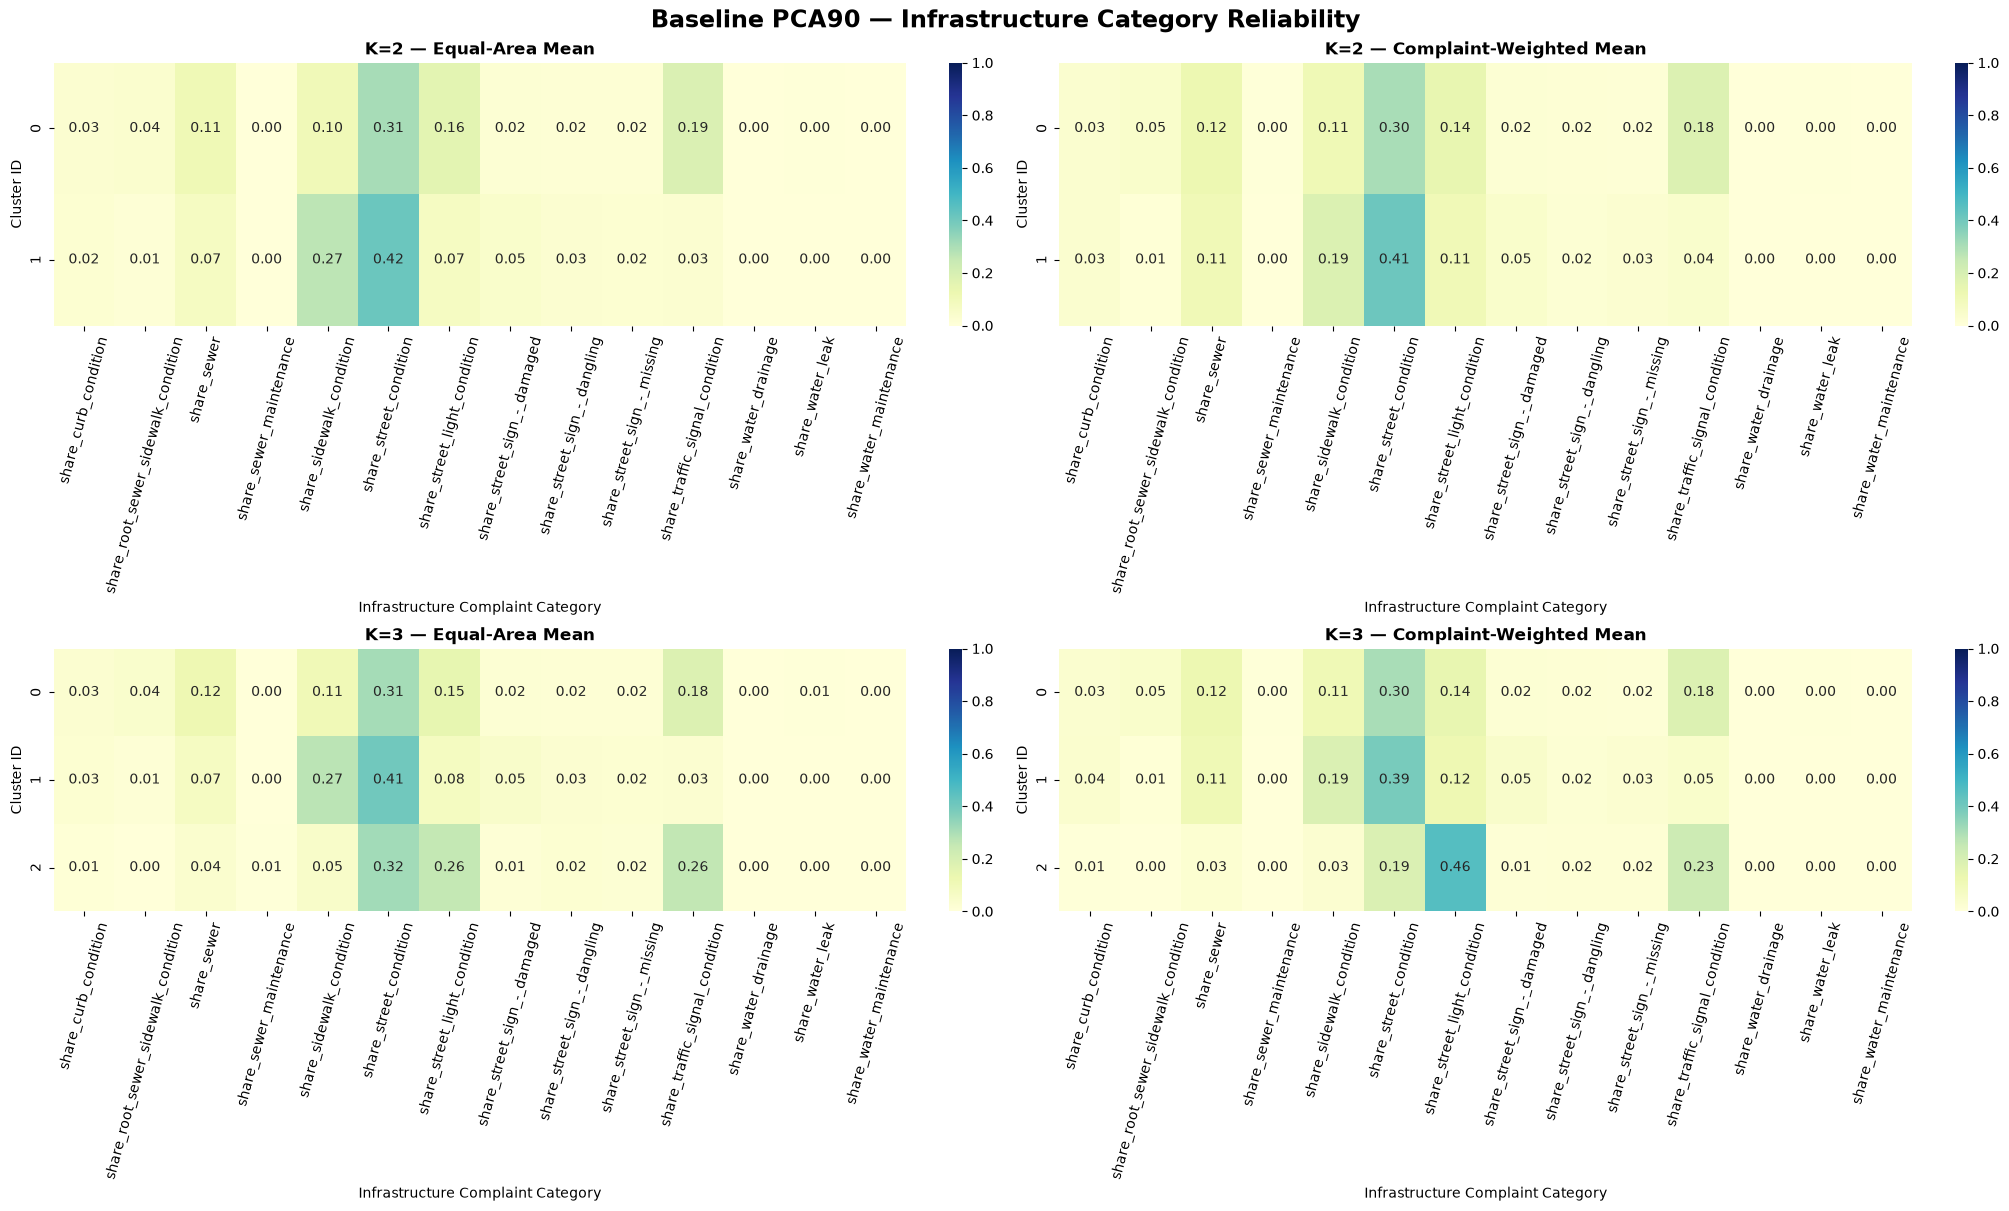

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    2, 2,
    figsize=(20, 12),
    constrained_layout=True
)

for row, k in enumerate([2, 3]):

    subset = category_comparison_df[
        category_comparison_df["k"] == k
    ]

    for col, (metric, title) in enumerate([
        ("equal_area_share", "Equal-Area Mean"),
        ("weighted_share", "Complaint-Weighted Mean")
    ]):

        matrix = subset.pivot(
            index="cluster_id",
            columns="category",
            values=metric
        )

        sns.heatmap(
            matrix,
            annot=True,
            fmt=".2f",
            cmap="YlGnBu",
            vmin=0,
            vmax=1,
            ax=axes[row, col]
        )

        axes[row, col].set_title(
            f"K={k} — {title}",
            fontweight="bold"
        )

        axes[row, col].set_xlabel(
            "Infrastructure Complaint Category"
        )

        axes[row, col].set_ylabel("Cluster ID")

        axes[row, col].tick_params(
            axis="x",
            rotation=75
        )

fig.suptitle(
    "Baseline PCA90 — Infrastructure Category Reliability",
    fontsize=17,
    fontweight="bold"
)

plt.savefig(
    KMEANS_FIGURES_DIR /
    "k2_k3_category_reliability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
#Identify the top three categories in each cluster
top_category_results = []

for (k, cluster_id), group in (
    category_comparison_df.groupby(["k", "cluster_id"])
):

    top_categories = group.nlargest(
        3,
        "weighted_share"
    )

    for rank, (_, row) in enumerate(
        top_categories.iterrows(),
        start=1
    ):

        top_category_results.append({
            "k": k,
            "cluster_id": cluster_id,
            "rank": rank,
            "category": row["category"],
            "equal_area_share": row["equal_area_share"],
            "weighted_share": row["weighted_share"]
        })

top_category_df = pd.DataFrame(
    top_category_results
)

display(top_category_df.round(4))

top_category_df.to_csv(
    KMEANS_TABLES_DIR /
    "k2_k3_top_infrastructure_categories.csv",
    index=False
)

,k,cluster_id,rank,category,equal_area_share,weighted_share
0,2,0,1,share_street_condition,0.3059,0.3040
1,2,0,2,share_traffic_signal_condition,0.1898,0.1805
2,2,0,3,share_street_light_condition,0.1592,0.1419
3,2,1,1,share_street_condition,0.4174,0.4123
4,2,1,2,share_sidewalk_condition,0.2662,0.1851
5,2,1,3,share_sewer,0.0724,0.1071
6,3,0,1,share_street_condition,0.3090,0.3045
7,3,0,2,share_traffic_signal_condition,0.1798,0.1803
8,3,0,3,share_street_light_condition,0.1463,0.1407
9,3,1,1,share_street_condition,0.4054,0.3879


K=3 identifies a smaller group of geographic areas with elevated complaint persistence and a distinctive street-light and traffic-signal reporting composition. This additional profile is not separately represented in the K=2 solution.

However, we must still verify whether this group is stable and reliable enough to justify selecting K=3 over the statistically stronger K=2 model.



## K=2 — Top Infrastructure Complaint Categories

| Cluster | Rank | Infrastructure Category | Equal-Area Share (%) | Complaint-Weighted Share (%) |
|---|---:|---|---:|---:|
| 0 | 1 | Street Condition | 30.59 | 30.40 |
| 0 | 2 | Traffic Signal Condition | 18.98 | 18.05 |
| 0 | 3 | Street Light Condition | 15.92 | 14.19 |
| 1 | 1 | Street Condition | 41.74 | 41.23 |
| 1 | 2 | Sidewalk Condition | 26.62 | 18.51 |
| 1 | 3 | Sewer | 7.24 | 10.71 |



## K=3 — Top Infrastructure Complaint Categories

| Cluster | Rank | Infrastructure Category | Equal-Area Share (%) | Complaint-Weighted Share (%) |
|---|---:|---|---:|---:|
| 0 | 1 | Street Condition | 30.90 | 30.45 |
| 0 | 2 | Traffic Signal Condition | 17.98 | 18.03 |
| 0 | 3 | Street Light Condition | 14.63 | 14.07 |
| 1 | 1 | Street Condition | 40.54 | 38.79 |
| 1 | 2 | Sidewalk Condition | 27.21 | 18.86 |
| 1 | 3 | Street Light Condition | 7.65 | 11.74 |
| 2 | 1 | Street Light Condition | 25.57 | **45.84** |
| 2 | 2 | Traffic Signal Condition | 25.82 | 23.43 |
| 2 | 3 | Street Condition | 31.60 | 18.98 |


Retain K=2 as the statistical benchmark, but continue investigating K=3 because it provides an additional persistence-oriented, lighting/signal-heavy reporting profile that may support the project's infrastructure monitoring objective


##  Area-Level Validation of the Persistence Cluster

### Objective

Investigate the 20 geographic areas assigned to Cluster 2 in the Baseline PCA90 K=3 solution.

### Validation Questions

1. Which geographic areas belong to the cluster?
2. How many complaint records support each area?
3. Are high persistence rates common across the cluster?
4. Are street-light and traffic-signal complaints dominant across many areas or concentrated in a few?
5. Do the results justify assigning a specialized reporting-profile label?

### Methodological Principle

Preserve all 238 geographic areas. Do not use complaint volume alone to determine infrastructure condition or exclude observations.


In [28]:
#Inspect the 20 geographic areas
# Baseline PCA90, K=3, Cluster 2

candidate_areas = profile_results[3].loc[
    profile_results[3]["cluster_id"] == 2
].copy()

assert len(candidate_areas) == 20
assert candidate_areas["area_id"].is_unique

inspection_columns = [
    "area_id",
    "total_complaints",
    "active_months",
    "monthly_cv",
    "repeated_complaint_rate",
    "persistent_complaint_rate",
    "avg_recurrence_span_days",
    "share_street_condition",
    "share_street_light_condition",
    "share_traffic_signal_condition"
]

candidate_areas = candidate_areas.sort_values(
    "total_complaints",
    ascending=False
)

display(
    candidate_areas[inspection_columns].round(4)
)

candidate_areas.to_csv(
    KMEANS_TABLES_DIR /
    "k3_persistence_cluster_area_details.csv",
    index=False
)

print("Areas:", len(candidate_areas))
print(
    "Total complaints:",
    candidate_areas["total_complaints"].sum()
)
print(
    "Low-support areas:",
    (candidate_areas["total_complaints"] < 30).sum()
)

,area_id,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days,share_street_condition,share_street_light_condition,share_traffic_signal_condition
70,MANHATTAN_10000,830,36,0.6796,0.9687,0.9446,930.6747,0.0735,0.7217,0.1904
214,QUEENS_11430,318,36,0.4799,0.8805,0.7044,708.2984,0.2704,0.2830,0.3365
154,MANHATTAN_10282,315,36,0.6196,0.8413,0.7651,941.8194,0.1175,0.7175,0.0730
114,MANHATTAN_10069,166,34,1.0927,0.5482,0.3916,648.6317,0.1687,0.4157,0.0000
88,MANHATTAN_10020,163,36,0.6994,0.7423,0.4601,734.1859,0.3865,0.0859,0.2883
142,MANHATTAN_10172,116,27,1.3376,0.9655,0.9483,711.4661,0.1121,0.1983,0.6466
225,QUEENS_11697,95,32,0.9846,0.4842,0.2632,703.1474,0.3263,0.3053,0.1895
168,QUEENS_11109,94,32,0.8936,0.6702,0.3191,715.0093,0.3617,0.2872,0.0000
155,MANHATTAN_10463,86,32,0.7704,0.4302,0.1512,717.5694,0.4419,0.2442,0.1047
150,MANHATTAN_10278,82,21,1.4527,0.9268,0.7317,672.2866,0.1585,0.2683,0.4878


Areas: 20
Total complaints: 2561
Low-support areas: 5


In [29]:
#Investigate whether a few areas dominate the cluster
import numpy as np
import pandas as pd

n = len(candidate_areas)
counts = candidate_areas["total_complaints"]

cluster_total = counts.sum()

top_3_volume_share = (
    counts.nlargest(3).sum() / cluster_total
)

lighting = "share_street_light_condition"
signals = "share_traffic_signal_condition"

# Area-level prevalence, descriptive thresholds
lighting_dominant = (
    candidate_areas[lighting] >= 0.30
).sum()

signal_dominant = (
    candidate_areas[signals] >= 0.30
).sum()

# Fraction of complaints accounted for by lighting
lighting_contributions = (
    candidate_areas[lighting] * counts
)

top_3_lighting_share = (
    lighting_contributions.nlargest(3).sum()
    / lighting_contributions.sum()
    if lighting_contributions.sum() > 0
    else np.nan
)

reliability_summary = pd.DataFrame([{
    "areas": n,
    "total_complaints": cluster_total,
    "low_support_areas": int((counts < 30).sum()),
    "areas_lighting_share_ge_30pct": int(lighting_dominant),
    "areas_signal_share_ge_30pct": int(signal_dominant),
    "top_3_areas_complaint_share_pct":
        100 * top_3_volume_share,
    "top_3_areas_lighting_contribution_pct":
        100 * top_3_lighting_share
}])

display(reliability_summary.round(2))

reliability_summary.to_csv(
    KMEANS_TABLES_DIR /
    "k3_persistence_cluster_reliability.csv",
    index=False
)

,areas,total_complaints,low_support_areas,areas_lighting_share_ge_30pct,areas_signal_share_ge_30pct,top_3_areas_complaint_share_pct,top_3_areas_lighting_contribution_pct
0,20,2561,5,5,7,57.13,77.94


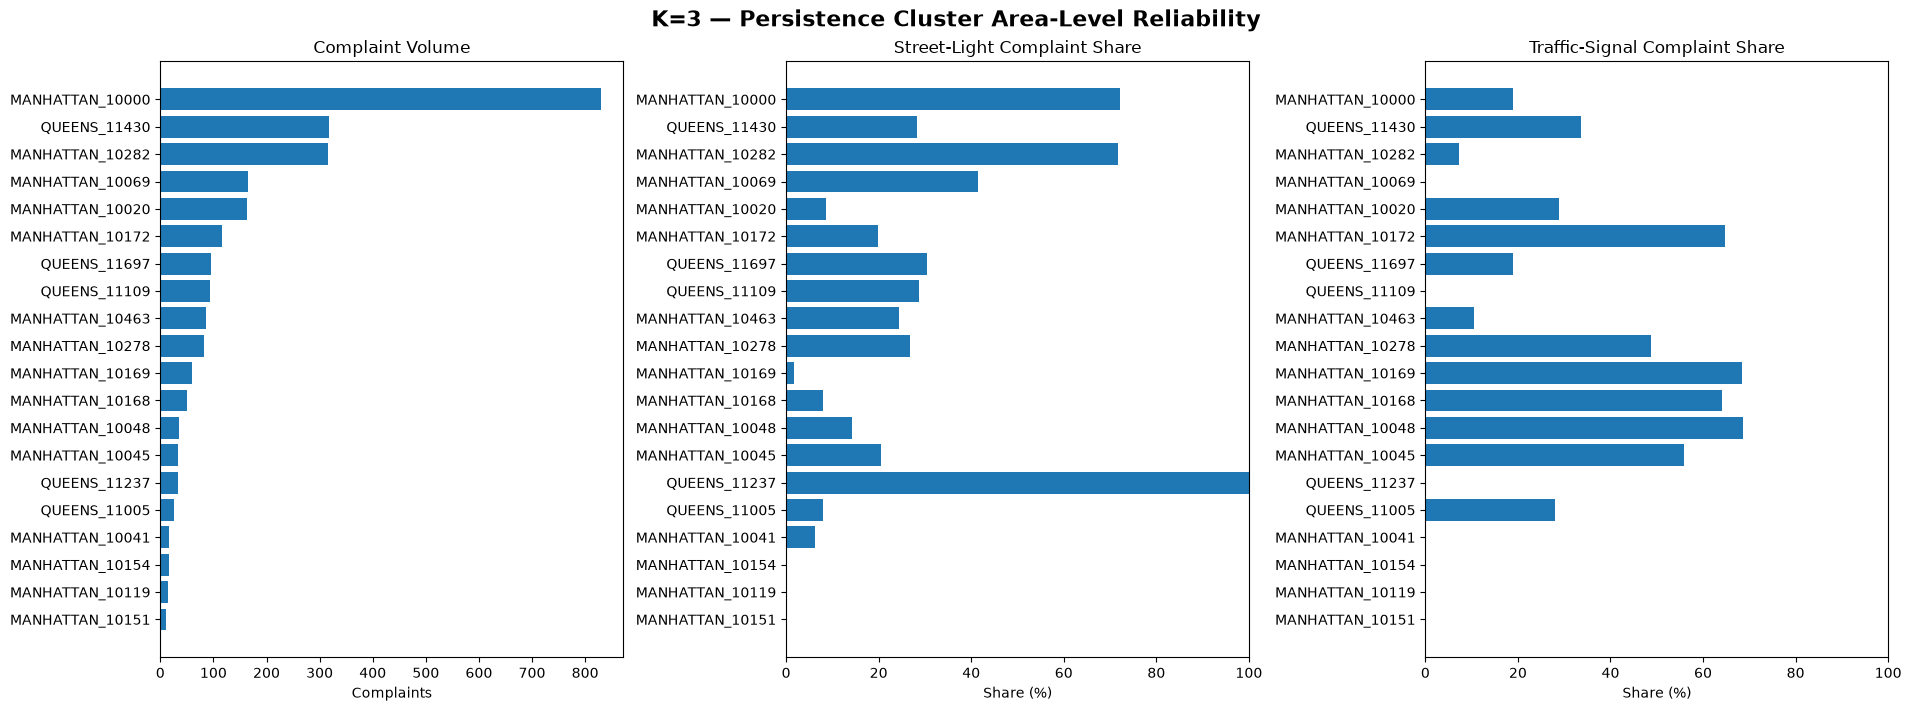

In [30]:
import matplotlib.pyplot as plt

plot_df = candidate_areas.sort_values(
    "total_complaints",
    ascending=False
).reset_index(drop=True)

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 7),
    constrained_layout=True
)

# Complaint volume
axes[0].barh(
    plot_df["area_id"],
    plot_df["total_complaints"]
)
axes[0].invert_yaxis()
axes[0].set_title("Complaint Volume")
axes[0].set_xlabel("Complaints")

# Lighting composition
axes[1].barh(
    plot_df["area_id"],
    plot_df[lighting] * 100
)
axes[1].invert_yaxis()
axes[1].set_title("Street-Light Complaint Share")
axes[1].set_xlabel("Share (%)")
axes[1].set_xlim(0, 100)

# Traffic-signal composition
axes[2].barh(
    plot_df["area_id"],
    plot_df[signals] * 100
)
axes[2].invert_yaxis()
axes[2].set_title("Traffic-Signal Complaint Share")
axes[2].set_xlabel("Share (%)")
axes[2].set_xlim(0, 100)

fig.suptitle(
    "K=3 — Persistence Cluster Area-Level Reliability",
    fontsize=16,
    fontweight="bold"
)

plt.savefig(
    KMEANS_FIGURES_DIR /
    "k3_persistence_cluster_area_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## K=3 — Persistence Cluster Reliability Summary

| Metric | Result |
|---|---:|
| Geographic Areas | 20 |
| Total Complaints | 2,561 |
| Areas With Fewer Than 30 Complaints | 5 |
| Areas With Street-Light Share >= 30% | 5 |
| Areas With Traffic-Signal Share >= 30% | 7 |
| Complaints From Top 3 Areas | 57.13% |
| Street-Light Complaint Contributions From Top 3 Areas | 77.94% |
| Median Repeated Complaint Rate | 79.17% |
| Median Persistent Complaint Rate | 60.00% |


Persistence: The cluster has high median repeated and persistent complaint rates, indicating a distinctive recurrence-oriented reporting profile.

Lighting specialization: Only 5 of the 20 areas have street-light shares of at least 30%. The three largest contributors account for 77.94% of the cluster's street-light complaint contribution. The weighted lighting share therefore does not represent all 20 areas equally.


## Selected Geographic Areas — Cluster 2

| Area ID | Complaints | Repeated Rate | Persistent Rate | Street-Light Share | Traffic-Signal Share |
|---|---:|---:|---:|---:|---:|
| MANHATTAN_10000 | 830 | 0.9687 | 0.9446 | 72.17% | 19.04% |
| QUEENS_11430 | 318 | 0.8805 | 0.7044 | 28.30% | 33.65% |
| MANHATTAN_10282 | 315 | 0.8413 | 0.7651 | 71.75% | 7.30% |
| MANHATTAN_10172 | 116 | 0.9655 | 0.9483 | 19.83% | 64.66% |
| MANHATTAN_10048 | 35 | 0.8857 | 0.8286 | 14.29% | 68.57% |
| QUEENS_11237 | 34 | 0.7353 | 0.1765 | 100.00% | 0.00% |


Geographic Identifier Integrity Check


##  Geographic Identifier Integrity Validation

### Objective

Verify that selected area IDs correspond consistently to the borough and ZIP information in the cleaned NYC 311 data.

### Areas Requiring Review

- MANHATTAN_10000
- MANHATTAN_10463
- QUEENS_11237
- MANHATTAN_10048

### Validation Principles

- Preserve original complaint records.
- Do not automatically change borough or ZIP assignments.
- Compare area-level counts with cleaned source records.
- Identify potential borough–ZIP inconsistencies.
- Document questionable identifiers for later geographic validation.
- Do not finalize spatial interpretations until geographic identifiers are verified.


In [31]:
import pandas as pd

suspect_ids = [
    "MANHATTAN_10000",
    "MANHATTAN_10463",
    "QUEENS_11237",
    "MANHATTAN_10048"
]

# Inspect current area-level features
area_check = source_df[
    source_df["area_id"].isin(suspect_ids)
].copy()

display(
    area_check[
        ["area_id", "total_complaints"]
    ].sort_values("area_id")
)

# Load corresponding source-record columns
cleaned_path = (
    PROCESSED_DATA_DIR /
    "nyc311_infrastructure_cleaned.csv"
)

source_records = pd.read_csv(
    cleaned_path,
    usecols=["borough", "incident_zip"],
    dtype="string",
    low_memory=False
)

# Standardize formatting for comparison only
source_records["borough_check"] = (
    source_records["borough"].str.strip().str.upper()
)

source_records["zip_check"] = (
    source_records["incident_zip"]
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

source_records["area_id_check"] = (
    source_records["borough_check"]
    + "_"
    + source_records["zip_check"]
)

# Count source records for each selected area
source_counts = (
    source_records[
        source_records["area_id_check"].isin(suspect_ids)
    ]
    .groupby("area_id_check")
    .size()
    .rename("source_record_count")
    .reset_index()
    .rename(columns={"area_id_check": "area_id"})
)

verification = area_check[
    ["area_id", "total_complaints"]
].merge(
    source_counts,
    on="area_id",
    how="left",
    validate="one_to_one"
)

verification["counts_match"] = (
    verification["total_complaints"]
    == verification["source_record_count"]
)

print("GEOGRAPHIC IDENTIFIER VERIFICATION")
display(verification)

verification.to_csv(
    KMEANS_TABLES_DIR /
    "geographic_identifier_verification.csv",
    index=False
)

,area_id,total_complaints
70,MANHATTAN_10000,830
112,MANHATTAN_10048,35
155,MANHATTAN_10463,86
170,QUEENS_11237,34


GEOGRAPHIC IDENTIFIER VERIFICATION


,area_id,total_complaints,source_record_count,counts_match
0,MANHATTAN_10000,830,830,True
1,MANHATTAN_10048,35,35,True
2,MANHATTAN_10463,86,86,True
3,QUEENS_11237,34,34,True


Inspect coordinates for questionable area IDs

In [32]:
import pandas as pd

check_ids = [
    "MANHATTAN_10000",
    "MANHATTAN_10048",
    "MANHATTAN_10463",
    "QUEENS_11237"
]

geo = pd.read_csv(
    PROCESSED_DATA_DIR / "nyc311_infrastructure_cleaned.csv",
    usecols=[
        "borough",
        "incident_zip",
        "latitude",
        "longitude"
    ],
    dtype={
        "borough": "string",
        "incident_zip": "string"
    },
    low_memory=False
)

geo["area_id"] = (
    geo["borough"].str.strip().str.upper()
    + "_"
    + geo["incident_zip"].str.strip()
        .str.replace(r"\.0$", "", regex=True)
)

geo = geo[geo["area_id"].isin(check_ids)].copy()

geo["latitude"] = pd.to_numeric(
    geo["latitude"], errors="coerce"
)
geo["longitude"] = pd.to_numeric(
    geo["longitude"], errors="coerce"
)

geo["valid_nyc_coordinates"] = (
    geo["latitude"].between(40.45, 40.95)
    & geo["longitude"].between(-74.30, -73.65)
)

summary = geo.groupby("area_id").agg(
    records=("area_id", "size"),
    valid_coordinate_records=("valid_nyc_coordinates", "sum"),
    median_latitude=("latitude", "median"),
    median_longitude=("longitude", "median")
).reset_index()

summary["valid_coordinate_pct"] = (
    100 * summary["valid_coordinate_records"]
    / summary["records"]
)

display(summary.round(4))

summary.to_csv(
    KMEANS_TABLES_DIR /
    "geographic_coordinate_diagnostics.csv",
    index=False
)

,area_id,records,valid_coordinate_records,median_latitude,median_longitude,valid_coordinate_pct
0,MANHATTAN_10000,830,822,40.7824,-73.9652,99.0361
1,MANHATTAN_10048,35,34,40.7137,-74.0138,97.1429
2,MANHATTAN_10463,86,66,40.8757,-73.9097,76.7442
3,QUEENS_11237,34,34,40.7054,-73.9151,100.0


Our existing clusters are built from area_id-level features. If source records were grouped under incorrect borough–ZIP combinations, their features may represent incorrectly assigned geographic areas.

That could affect geographic interpretation and later DBSCAN analysis, even if the K-Means algorithm itself runs successfully.

We should verify the borough at the individual complaint-coordinate level before changing any identifiers.

### Compare recorded boroughs with coordinate-derived boroughs

In [33]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [34]:
import geopandas as gpd
import pandas as pd
import numpy as np

# Official NYC borough boundaries
boundary_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "gthc-hcne/query.geojson?accessType=DOWNLOAD"
)

boroughs = gpd.read_file(boundary_url)

boroughs.columns = boroughs.columns.str.lower()

boroughs = boroughs[
    ["boroname", "geometry"]
].copy()

boroughs = boroughs.to_crs("EPSG:4326")

# Use record-level data created in Cell 46
records = geo.copy()

records["recorded_borough"] = (
    records["borough"].str.strip().str.upper()
)

records = records.reset_index(drop=True)
records["audit_row_id"] = np.arange(len(records))

# Exclude missing/out-of-range coordinates from spatial join
valid = records[
    records["valid_nyc_coordinates"]
].copy()

points = gpd.GeoDataFrame(
    valid,
    geometry=gpd.points_from_xy(
        valid["longitude"],
        valid["latitude"]
    ),
    crs="EPSG:4326"
)

matched = gpd.sjoin(
    points,
    boroughs,
    how="left",
    predicate="within"
)

# Handle points near boundaries or overlapping polygons
match_counts = matched.groupby(
    "audit_row_id"
)["boroname"].nunique()

assert match_counts.max() <= 1, (
    "Ambiguous borough matches require inspection."
)

matched["coordinate_borough"] = (
    matched["boroname"].str.upper()
)

matched["borough_match"] = (
    matched["recorded_borough"]
    == matched["coordinate_borough"]
)

matched["verification_status"] = np.select(
    [
        matched["coordinate_borough"].isna(),
        matched["borough_match"].fillna(False)
    ],
    [
        "No polygon match",
        "Match"
    ],
    default="Mismatch"
)

summary = pd.crosstab(
    matched["area_id"],
    matched["verification_status"]
)

display(summary)

matched.drop(
    columns=["geometry", "index_right"],
    errors="ignore"
).to_csv(
    KMEANS_TABLES_DIR /
    "borough_coordinate_validation.csv",
    index=False
)

verification_status,Match,Mismatch
area_id,,
MANHATTAN_10000,822,0
MANHATTAN_10048,34,0
MANHATTAN_10463,66,0
QUEENS_11237,15,19



##  Geographic Discrepancy Investigation

### Objective

Investigate inconsistent borough and ZIP identifiers before finalizing geographic interpretations of the K-Means results.

### Findings So Far

- QUEENS_11237 contains 19 coordinate-derived borough mismatches among 34 records.
- MANHATTAN_10463 has a potential borough-ZIP inconsistency even though its eligible coordinates match the recorded borough.
- 29 records across the four selected areas did not pass the earlier coordinate eligibility check.

### Methodological Decision

Preserve all original records and existing model results.

Do not automatically correct geographic identifiers until sufficient evidence is available.


In [35]:
import pandas as pd

# Use matched from Cell 47
geo_diagnostics = matched.copy()

# Compare recorded and coordinate-derived boroughs
borough_distribution = (
    geo_diagnostics.groupby(
        [
            "area_id",
            "recorded_borough",
            "coordinate_borough"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="records")
    .sort_values(
        ["area_id", "records"],
        ascending=[True, False]
    )
)

print("BOROUGH DISTRIBUTION ANALYSIS")
print("=" * 55)

display(borough_distribution)

# Inspect mismatched records separately
mismatch_records = geo_diagnostics[
    geo_diagnostics["verification_status"] == "Mismatch"
].copy()

print("\nTotal mismatched records:", len(mismatch_records))

display(
    mismatch_records[
        [
            "area_id",
            "recorded_borough",
            "coordinate_borough",
            "latitude",
            "longitude"
        ]
    ].head(25)
)

# Save diagnostics
borough_distribution.to_csv(
    KMEANS_TABLES_DIR /
    "borough_distribution_diagnostics.csv",
    index=False
)

mismatch_records.drop(
    columns=["geometry", "index_right"],
    errors="ignore"
).to_csv(
    KMEANS_TABLES_DIR /
    "geographic_mismatch_records.csv",
    index=False
)

print("\nGeographic discrepancy reports saved.")

BOROUGH DISTRIBUTION ANALYSIS


,area_id,recorded_borough,coordinate_borough,records
0,MANHATTAN_10000,MANHATTAN,MANHATTAN,822
1,MANHATTAN_10048,MANHATTAN,MANHATTAN,34
2,MANHATTAN_10463,MANHATTAN,MANHATTAN,66
3,QUEENS_11237,QUEENS,BROOKLYN,19
4,QUEENS_11237,QUEENS,QUEENS,15



Total mismatched records: 19


,area_id,recorded_borough,coordinate_borough,latitude,longitude
35,QUEENS_11237,QUEENS,BROOKLYN,40.707381,-73.918478
65,QUEENS_11237,QUEENS,BROOKLYN,40.706941,-73.917735
243,QUEENS_11237,QUEENS,BROOKLYN,40.692418,-73.902788
253,QUEENS_11237,QUEENS,BROOKLYN,40.702362,-73.912905
332,QUEENS_11237,QUEENS,BROOKLYN,40.708695,-73.920702
366,QUEENS_11237,QUEENS,BROOKLYN,40.699531,-73.911037
400,QUEENS_11237,QUEENS,BROOKLYN,40.701923,-73.912162
403,QUEENS_11237,QUEENS,BROOKLYN,40.708695,-73.920702
411,QUEENS_11237,QUEENS,BROOKLYN,40.699531,-73.911037
419,QUEENS_11237,QUEENS,BROOKLYN,40.704748,-73.914030



Geographic discrepancy reports saved.



##  Citywide Geographic Integrity Audit

### Objective

Validate borough consistency for all geocoded NYC 311 infrastructure complaints from 2023–2025.

### Methodology

1. Preserve original borough and ZIP values.
2. Derive boroughs independently from complaint coordinates.
3. Identify matches, mismatches, and unresolved locations.
4. Summarize discrepancies by geographic area.
5. Save audit results without modifying existing clustering datasets.

### Important Limitation

Coordinate-based borough verification does not independently validate ZIP-code accuracy. A borough-ZIP crosswalk is also required before geographic identifiers can be certified.


In [36]:
import geopandas as gpd
import pandas as pd
import numpy as np

cleaned_path = (
    PROCESSED_DATA_DIR /
    "nyc311_infrastructure_cleaned.csv"
)

audit_df = pd.read_csv(
    cleaned_path,
    usecols=[
        "borough",
        "incident_zip",
        "latitude",
        "longitude"
    ],
    dtype={
        "borough": "string",
        "incident_zip": "string"
    },
    low_memory=False
)

audit_df["recorded_borough"] = (
    audit_df["borough"].str.strip().str.upper()
)

audit_df["zip_check"] = (
    audit_df["incident_zip"]
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

audit_df["area_id"] = (
    audit_df["recorded_borough"]
    + "_"
    + audit_df["zip_check"]
)

audit_df["latitude"] = pd.to_numeric(
    audit_df["latitude"], errors="coerce"
)

audit_df["longitude"] = pd.to_numeric(
    audit_df["longitude"], errors="coerce"
)

audit_df["coordinate_plausible"] = (
    audit_df["latitude"].between(40.45, 40.95)
    & audit_df["longitude"].between(-74.30, -73.65)
)

audit_df["audit_row_id"] = np.arange(len(audit_df))

valid = audit_df[
    audit_df["coordinate_plausible"]
].copy()

points = gpd.GeoDataFrame(
    valid,
    geometry=gpd.points_from_xy(
        valid["longitude"],
        valid["latitude"]
    ),
    crs="EPSG:4326"
)

boundary = boroughs[
    ["boroname", "geometry"]
].to_crs("EPSG:4326")

matched_all = gpd.sjoin(
    points,
    boundary,
    how="left",
    predicate="within"
)

# Check for ambiguous matches before summarizing
assert not matched_all["audit_row_id"].duplicated().any(), (
    "Multiple borough matches detected; inspect boundaries."
)

matched_all["coordinate_borough"] = (
    matched_all["boroname"].str.upper()
)

# Fix nullable Boolean comparison
borough_matches = (
    matched_all["recorded_borough"]
    .eq(matched_all["coordinate_borough"])
    .fillna(False)
    .to_numpy(dtype=bool)
)

unresolved = (
    matched_all["coordinate_borough"]
    .isna()
    .to_numpy(dtype=bool)
)

# Assign geographic verification status
matched_all["status"] = np.select(
    [
        unresolved,
        borough_matches
    ],
    [
        "Unresolved",
        "Match"
    ],
    default="Mismatch"
)

print("Geographic verification statuses created successfully.")

# Include records without plausible coordinates
invalid = audit_df[
    ~audit_df["coordinate_plausible"]
].copy()

invalid["status"] = "Unresolved"

audit_results = pd.concat(
    [
        matched_all.drop(
            columns=["geometry", "index_right"],
            errors="ignore"
        ),
        invalid
    ],
    ignore_index=True
)

assert len(audit_results) == len(audit_df)

summary = (
    audit_results.groupby("status")
    .size()
    .rename("records")
    .reset_index()
)

summary["percentage"] = (
    100 * summary["records"] / len(audit_results)
)

print("CITYWIDE GEOGRAPHIC INTEGRITY AUDIT")
print("=" * 55)

print("Total records:", len(audit_results))
display(summary.round(2))

Geographic verification statuses created successfully.
CITYWIDE GEOGRAPHIC INTEGRITY AUDIT
Total records: 685284


,status,records,percentage
0,Match,609925,89.00
1,Mismatch,651,0.09
2,Unresolved,74708,10.90


In [37]:
assert len(audit_results) == 685284

assert audit_results["status"].value_counts().get(
    "Match", 0
) == 609925

assert audit_results["status"].value_counts().get(
    "Mismatch", 0
) == 651

assert audit_results["status"].value_counts().get(
    "Unresolved", 0
) == 74708

print("Citywide audit counts verified.")

Citywide audit counts verified.


In [38]:
# STEP 12.17 — Geographic mismatch distribution

area_mismatch_summary = (
    audit_results.groupby(["area_id", "status"], dropna=False)
    .size()
    .unstack(fill_value=0)
)

for col in ["Match", "Mismatch", "Unresolved"]:
    if col not in area_mismatch_summary.columns:
        area_mismatch_summary[col] = 0

area_mismatch_summary["total_records"] = (
    area_mismatch_summary[
        ["Match", "Mismatch", "Unresolved"]
    ].sum(axis=1)
)

area_mismatch_summary["mismatch_pct"] = (
    100 * area_mismatch_summary["Mismatch"]
    / area_mismatch_summary["total_records"]
)

# Focus on areas with at least one confirmed mismatch
affected_areas = (
    area_mismatch_summary[
        area_mismatch_summary["Mismatch"] > 0
    ]
    .sort_values("Mismatch", ascending=False)
)

print("GEOGRAPHIC MISMATCH DISTRIBUTION")
print("=" * 55)
print("Affected areas:", len(affected_areas))
print("Confirmed mismatched records:", affected_areas["Mismatch"].sum())

display(affected_areas.head(20).round(2))

affected_areas.to_csv(
    KMEANS_TABLES_DIR / "affected_geographic_areas.csv"
)

GEOGRAPHIC MISMATCH DISTRIBUTION
Affected areas: 15
Confirmed mismatched records: 651


status,Match,Mismatch,Unresolved,total_records,mismatch_pct
area_id,,,,,
BRONX_10463,3920,200,398,4518,4.43
UNSPECIFIED_11237,0,126,1,127,99.21
<NA>,92,92,16423,16607,0.55
UNSPECIFIED_11208,0,74,0,74,100.00
BROOKLYN_11237,3022,55,200,3277,1.68
BROOKLYN_11208,5604,38,415,6057,0.63
QUEENS_11385,8298,24,925,9247,0.26
QUEENS_11237,15,19,0,34,55.88
UNSPECIFIED_10463,0,7,0,7,100.00


In [39]:
import pandas as pd
import numpy as np

valid_boroughs = {
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
}

# Work on an audit copy; do not change source records
geo_review = audit_results.copy()

geo_review["valid_recorded_borough"] = (
    geo_review["recorded_borough"]
    .isin(valid_boroughs)
    .fillna(False)
)

geo_review["valid_area_id"] = (
    geo_review["area_id"].notna()
    & geo_review["valid_recorded_borough"]
)

# Compare against the actual modeling population
modeled_area_ids = set(
    source_df["area_id"].dropna().astype(str)
)

geo_review["in_modeling_population"] = (
    geo_review["area_id"].isin(modeled_area_ids)
)

# Classify originally reported mismatches
mismatches = geo_review.loc[
    geo_review["status"] == "Mismatch"
].copy()

mismatches["mismatch_group"] = np.select(
    [
        ~mismatches["valid_recorded_borough"].to_numpy(
            dtype=bool
        ),

        mismatches["area_id"].isna().to_numpy(
            dtype=bool
        ),

        mismatches["in_modeling_population"].to_numpy(
            dtype=bool
        )
    ],
    [
        "Missing or unspecified borough",
        "Missing area identifier",
        "Modeled geographic area"
    ],
    default="Other geographic area"
)

mismatch_group_summary = (
    mismatches.groupby("mismatch_group")
    .size()
    .rename("records")
    .reset_index()
)

mismatch_group_summary["percentage"] = (
    100 * mismatch_group_summary["records"]
    / len(mismatches)
)

assert len(geo_review) == 685284

assert (
    mismatch_group_summary["records"].sum()
    == 651
)

print("GEOGRAPHIC MISMATCH CLASSIFICATION")
print("=" * 55)

display(mismatch_group_summary.round(2))

mismatch_group_summary.to_csv(
    KMEANS_TABLES_DIR /
    "geographic_mismatch_classification.csv",
    index=False
)

GEOGRAPHIC MISMATCH CLASSIFICATION


,mismatch_group,records,percentage
0,Missing or unspecified borough,303,46.54
1,Modeled geographic area,348,53.46


In [40]:
modeled_mismatches = mismatches[
    mismatches["in_modeling_population"]
    & mismatches["valid_recorded_borough"]
].copy()

affected_model_areas = (
    modeled_mismatches.groupby("area_id")
    .size()
    .rename("mismatched_records")
    .reset_index()
)

# Use full area-level totals as denominators
affected_model_areas = (
    affected_model_areas.merge(
        source_df[
            ["area_id", "total_complaints"]
        ],
        on="area_id",
        how="left",
        validate="one_to_one"
    )
)

affected_model_areas["mismatch_pct"] = (
    100
    * affected_model_areas["mismatched_records"]
    / affected_model_areas["total_complaints"]
)

affected_model_areas = (
    affected_model_areas.sort_values(
        "mismatched_records",
        ascending=False
    )
)

print("MODELED GEOGRAPHIC AREAS AFFECTED")
print("=" * 55)

print(
    "Affected modeled areas:",
    len(affected_model_areas)
)

print(
    "Mismatch records in modeled areas:",
    len(modeled_mismatches)
)

display(affected_model_areas.head(20).round(2))

affected_model_areas.to_csv(
    KMEANS_TABLES_DIR /
    "modeled_area_geographic_mismatches.csv",
    index=False
)

MODELED GEOGRAPHIC AREAS AFFECTED
Affected modeled areas: 10
Mismatch records in modeled areas: 348


,area_id,mismatched_records,total_complaints,mismatch_pct
0,BRONX_10463,200,4518,4.43
2,BROOKLYN_11237,55,3277,1.68
1,BROOKLYN_11208,38,6057,0.63
7,QUEENS_11385,24,9247,0.26
5,QUEENS_11237,19,34,55.88
9,QUEENS_11421,5,3504,0.14
4,QUEENS_11208,4,12,33.33
3,BROOKLYN_11421,1,1,100.00
6,QUEENS_11370,1,2560,0.04
8,QUEENS_11416,1,2696,0.04


Check Whether the 10 Affected Areas Influence K-Means


##  Geographic Discrepancy Impact on K-Means

### Objective

Determine how the 10 geographic areas with confirmed borough-coordinate disagreements are distributed across the Baseline PCA90 K=2 and K=3 clustering solutions.

### Methodology

- Preserve all 238 geographic areas.
- Use existing Baseline PCA90 cluster assignments.
- Compare geographic mismatch percentages with cluster membership.
- Examine coordinate-derived boroughs for the affected records.
- Identify areas requiring independent ZIP and borough verification.
- Do not modify or retrain the clustering models.

### Research Question

Are geographic discrepancies concentrated in particular reporting profiles, and which areas should be prioritized for geographic correction sensitivity testing?


In [41]:
import pandas as pd
import numpy as np

# Existing affected-area audit
affected = affected_model_areas.copy()

# Existing Baseline PCA90 cluster assignments
k2_assignments = (
    profile_results[2][["area_id", "cluster_id"]]
    .rename(columns={"cluster_id": "k2_cluster"})
)

k3_assignments = (
    profile_results[3][["area_id", "cluster_id"]]
    .rename(columns={"cluster_id": "k3_cluster"})
)

# Align through area_id, never row position
impact_df = (
    affected
    .merge(
        k2_assignments,
        on="area_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        k3_assignments,
        on="area_id",
        how="left",
        validate="one_to_one"
    )
)

assert len(impact_df) == 10
assert impact_df["area_id"].is_unique
assert impact_df["k2_cluster"].notna().all()
assert impact_df["k3_cluster"].notna().all()

impact_df["low_support_flag"] = (
    impact_df["total_complaints"] < 30
)

impact_df = impact_df.sort_values(
    "mismatch_pct",
    ascending=False
)

print("GEOGRAPHIC IMPACT ON K-MEANS")
print("=" * 55)

display(impact_df.round(2))

impact_df.to_csv(
    KMEANS_TABLES_DIR /
    "geographic_mismatch_cluster_impact.csv",
    index=False
)

GEOGRAPHIC IMPACT ON K-MEANS


,area_id,mismatched_records,total_complaints,mismatch_pct,k2_cluster,k3_cluster,low_support_flag
7,BROOKLYN_11421,1,1,100.00,1,1,True
4,QUEENS_11237,19,34,55.88,0,2,False
6,QUEENS_11208,4,12,33.33,1,1,True
0,BRONX_10463,200,4518,4.43,0,0,False
1,BROOKLYN_11237,55,3277,1.68,0,0,False
2,BROOKLYN_11208,38,6057,0.63,0,0,False
3,QUEENS_11385,24,9247,0.26,0,0,False
5,QUEENS_11421,5,3504,0.14,0,0,False
8,QUEENS_11370,1,2560,0.04,0,0,False
9,QUEENS_11416,1,2696,0.04,0,0,False


In [42]:
# Select only the 348 mismatches in modeled areas
model_mismatch_records = audit_results.loc[
    (audit_results["status"] == "Mismatch")
    & (
        audit_results["area_id"].isin(
            affected["area_id"]
        )
    )
].copy()

destination_summary = (
    model_mismatch_records
    .groupby(
        ["area_id", "coordinate_borough"],
        dropna=False
    )
    .size()
    .rename("records")
    .reset_index()
    .sort_values(
        ["area_id", "records"],
        ascending=[True, False]
    )
)

assert destination_summary["records"].sum() == 348

print("COORDINATE-DERIVED BOROUGH DISTRIBUTION")
print("=" * 55)

display(destination_summary)

destination_summary.to_csv(
    KMEANS_TABLES_DIR /
    "mismatch_coordinate_borough_distribution.csv",
    index=False
)

COORDINATE-DERIVED BOROUGH DISTRIBUTION


,area_id,coordinate_borough,records
0,BRONX_10463,MANHATTAN,200
1,BROOKLYN_11208,QUEENS,38
2,BROOKLYN_11237,QUEENS,55
3,BROOKLYN_11421,QUEENS,1
4,QUEENS_11208,BROOKLYN,4
5,QUEENS_11237,BROOKLYN,19
6,QUEENS_11370,BRONX,1
7,QUEENS_11385,BROOKLYN,24
8,QUEENS_11416,BROOKLYN,1
9,QUEENS_11421,BROOKLYN,5


In [43]:
import pandas as pd
import numpy as np

geo_priority = impact_df.copy()

# Assessment priorities, not automatic corrections
geo_priority["review_priority"] = np.select(
    [
        geo_priority["mismatch_pct"] >= 25,
        geo_priority["mismatched_records"] >= 50
    ],
    [
        "High",
        "Moderate"
    ],
    default="Routine"
)

geo_priority["requires_zip_validation"] = True
geo_priority["correction_approved"] = False

geo_priority = geo_priority.sort_values(
    ["mismatch_pct", "mismatched_records"],
    ascending=[False, False]
)

display(
    geo_priority[
        [
            "area_id",
            "total_complaints",
            "mismatched_records",
            "mismatch_pct",
            "k2_cluster",
            "k3_cluster",
            "review_priority"
        ]
    ].round(2)
)

geo_priority.to_csv(
    KMEANS_TABLES_DIR /
    "geographic_correction_review_priorities.csv",
    index=False
)

print("Geographic review priorities saved.")
print("Existing dataset and clustering models unchanged.")

,area_id,total_complaints,mismatched_records,mismatch_pct,k2_cluster,k3_cluster,review_priority
7,BROOKLYN_11421,1,1,100.00,1,1,High
4,QUEENS_11237,34,19,55.88,0,2,High
6,QUEENS_11208,12,4,33.33,1,1,High
0,BRONX_10463,4518,200,4.43,0,0,Moderate
1,BROOKLYN_11237,3277,55,1.68,0,0,Moderate
2,BROOKLYN_11208,6057,38,0.63,0,0,Routine
3,QUEENS_11385,9247,24,0.26,0,0,Routine
5,QUEENS_11421,3504,5,0.14,0,0,Routine
8,QUEENS_11370,2560,1,0.04,0,0,Routine
9,QUEENS_11416,2696,1,0.04,0,0,Routine


Geographic review priorities saved.
Existing dataset and clustering models unchanged.



## Geographic Correction — Review Priority Summary

| Review Priority | Number of Areas | Mismatched Records | Recommended Action |
|---|---:|---:|---|
| High | 3 | 24 | Verify individual geographic records |
| Moderate | 2 | 255 | Investigate borough-boundary and ZIP consistency |
| Routine | 5 | 69 | Document and check alongside other records |
| **Total** | **10** | **348** | **No automatic corrections** |


In [44]:
import geopandas as gpd

zcta_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "35j5-n34v/query.geojson?accessType=DOWNLOAD"
)

zcta = gpd.read_file(zcta_url)

print("ZCTA records:", len(zcta))
print("Available columns:")
print(zcta.columns.tolist())

display(zcta.head(3))

ZCTA records: 221
Available columns:
[':id', ':version', ':created_at', ':updated_at', 'zcta5', 'arealand', 'areawater', 'centlat', 'centlon', 'intptlat', 'intptlon', 'geometry']


,:id,:version,:created_at,:updated_at,zcta5,arealand,areawater,centlat,centlon,intptlat,intptlon,geometry
0,row-ncum~5h7i-gbga,rv-wv4d~gbsx~qfbb,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,07305,14763292,13239409,+40.6930497,-074.0693224,+40.6930039,-074.0696505,"MULTIPOLYGON (((-74.0472 40.69079, -74.04719 4..."
1,row-cs88~pzn7~rg2v,rv-5tsi.p38z~bsw8,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,10001,1616221,0,+40.7506490,-073.9972976,+40.7506490,-073.9972976,"MULTIPOLYGON (((-74.00998 40.7526, -74.00849 4..."
2,row-8arp~gzmb_9mxy,rv-37w5_byqk_yhem,2026-04-10 14:10:02.473000+00:00,2026-04-10 14:10:02.473000+00:00,10002,2129725,0,+40.7159693,-073.9868946,+40.7159693,-073.9868946,"MULTIPOLYGON (((-73.99709 40.71462, -73.99681 ..."


In [45]:
import geopandas as gpd
import pandas as pd
import numpy as np

# Preserve ZIP codes as five-character strings
zcta_check = zcta[["zcta5", "geometry"]].copy()

zcta_check["zcta5"] = (
    zcta_check["zcta5"]
    .astype("string")
    .str.strip()
    .str.zfill(5)
)

zcta_check = zcta_check.rename(
    columns={"zcta5": "coordinate_zcta"}
)

# Ensure geographic coordinate reference system
zcta_check = zcta_check.to_crs("EPSG:4326")

assert zcta_check["coordinate_zcta"].notna().all()
assert zcta_check.geometry.notna().all()

print("ZIP geographic reference ready.")
print("ZCTA polygons:", len(zcta_check))
print("CRS:", zcta_check.crs)

ZIP geographic reference ready.
ZCTA polygons: 221
CRS: EPSG:4326


In [46]:
# Use the 348 modeled-area mismatch records from Cell 58
zip_audit = model_mismatch_records.copy().reset_index(drop=True)

assert len(zip_audit) == 348

# Normalize recorded ZIP codes
zip_audit["recorded_zip"] = (
    zip_audit["incident_zip"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Preserve a unique identifier for each audit observation
zip_audit["zip_audit_id"] = np.arange(len(zip_audit))

# Create geographic points
zip_points = gpd.GeoDataFrame(
    zip_audit,
    geometry=gpd.points_from_xy(
        zip_audit["longitude"],
        zip_audit["latitude"]
    ),
    crs="EPSG:4326"
)

# Match coordinates to ZCTA polygons
zip_joined = gpd.sjoin(
    zip_points,
    zcta_check,
    how="left",
    predicate="intersects"
)

# Check whether polygon intersections are ambiguous
match_counts = (
    zip_joined.groupby("zip_audit_id")
    ["coordinate_zcta"]
    .nunique()
)

ambiguous_ids = set(
    match_counts[match_counts > 1].index
)

# Determine whether the recorded ZIP matches any
# intersecting ZCTA polygon for each complaint
def classify_zip_matches(group):

    recorded = group["recorded_zip"].iloc[0]

    candidates = set(
        group["coordinate_zcta"]
        .dropna()
        .astype(str)
    )

    if pd.isna(recorded) or not candidates:
        status = "Unresolved"

    elif len(candidates) > 1:
        status = "Ambiguous ZCTA"

    elif str(recorded) in candidates:
        status = "ZIP Match"

    else:
        status = "ZIP Mismatch"

    return pd.Series({
        "recorded_zip": recorded,
        "coordinate_zcta": (
            ", ".join(sorted(candidates))
            if candidates else pd.NA
        ),
        "zip_status": status
    })

zip_results = (
    zip_joined.groupby("zip_audit_id")
    .apply(classify_zip_matches)
    .reset_index()
)

# Restore original area IDs
zip_results = zip_results.merge(
    zip_audit[
        ["zip_audit_id", "area_id"]
    ],
    on="zip_audit_id",
    how="left",
    validate="one_to_one"
)

assert len(zip_results) == 348
assert zip_results["zip_audit_id"].is_unique

print("ZIP-COORDINATE VALIDATION")
print("=" * 55)

zip_summary = (
    zip_results["zip_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="records")
)

zip_summary["percentage"] = (
    100 * zip_summary["records"] / len(zip_results)
)

display(zip_summary.round(2))

zip_results.to_csv(
    KMEANS_TABLES_DIR /
    "modeled_area_zip_coordinate_validation.csv",
    index=False
)

ZIP-COORDINATE VALIDATION


,status,records,percentage
0,ZIP Match,247,70.98
1,ZIP Mismatch,101,29.02


In [47]:
area_zip_summary = pd.crosstab(
    zip_results["area_id"],
    zip_results["zip_status"]
)

for col in [
    "ZIP Match",
    "ZIP Mismatch",
    "Unresolved",
    "Ambiguous ZCTA"
]:
    if col not in area_zip_summary.columns:
        area_zip_summary[col] = 0

area_zip_summary["total_records"] = (
    area_zip_summary[
        [
            "ZIP Match",
            "ZIP Mismatch",
            "Unresolved",
            "Ambiguous ZCTA"
        ]
    ].sum(axis=1)
)

area_zip_summary["zip_mismatch_pct"] = (
    100
    * area_zip_summary["ZIP Mismatch"]
    / area_zip_summary["total_records"]
)

area_zip_summary = area_zip_summary.sort_values(
    "ZIP Mismatch",
    ascending=False
)

print("AREA-LEVEL ZIP VERIFICATION")
display(area_zip_summary.round(2))

area_zip_summary.to_csv(
    KMEANS_TABLES_DIR /
    "area_zip_validation_summary.csv"
)

AREA-LEVEL ZIP VERIFICATION


zip_status,ZIP Match,ZIP Mismatch,Unresolved,Ambiguous ZCTA,total_records,zip_mismatch_pct
area_id,,,,,,
BROOKLYN_11237,0,55,0,0,55,100.00
BROOKLYN_11208,11,27,0,0,38,71.05
QUEENS_11385,12,12,0,0,24,50.00
QUEENS_11421,0,5,0,0,5,100.00
QUEENS_11416,0,1,0,0,1,100.00
QUEENS_11237,18,1,0,0,19,5.26
BRONX_10463,200,0,0,0,200,0.00
BROOKLYN_11421,1,0,0,0,1,0.00
QUEENS_11208,4,0,0,0,4,0.00



## Geographic Sensitivity Analysis

### Objective

Evaluate whether the 10 geographic areas with borough-coordinate disagreements materially influence K-Means clustering.

### Method

- Preserve the original 238-area dataset.
- Use Baseline PCA90 as the leading candidate representation.
- Compare K=2 and K=3.
- Temporarily exclude the 10 affected areas from a diagnostic K-Means fit.
- Compare assignments for the remaining 228 areas using Adjusted Rand Index.
- Examine silhouette scores and cluster-size distributions.
- Do not overwrite existing PCA or K-Means models.

### Limitation

This tests sensitivity to the presence of the flagged areas while holding the existing PCA transformation fixed. It does not simulate corrected complaint locations or a complete upstream model rebuild.


In [48]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score
)

REPRESENTATION = "Baseline PCA90"

# Original 238-area PCA representation
X = np.asarray(
    datasets[REPRESENTATION],
    dtype=float
)

# Validate row alignment against existing profile results
area_ids = source_aligned["area_id"].astype(str)

assert len(X) == len(area_ids) == 238
assert area_ids.is_unique
assert np.isfinite(X).all()

assert (
    profile_results[2]["area_id"].astype(str).tolist()
    == area_ids.tolist()
)

assert (
    profile_results[3]["area_id"].astype(str).tolist()
    == area_ids.tolist()
)

# Previously identified geographic discrepancy areas
affected_ids = set(
    affected_model_areas["area_id"].astype(str)
)

assert len(affected_ids) == 10
assert affected_ids.issubset(set(area_ids))

# Keep unaffected areas only in this diagnostic
keep_mask = (
    ~area_ids.isin(affected_ids)
).to_numpy()

X_diagnostic = X[keep_mask]

assert len(X_diagnostic) == 228

sensitivity_results = []

for k in [2, 3]:

    # Original clustering labels on all 238 areas
    original_labels = comparison_labels[
        (REPRESENTATION, k)
    ]

    original_common_labels = np.asarray(
        original_labels
    )[keep_mask]

    # Refit only K-Means on the diagnostic subset
    model = KMeans(
        n_clusters=k,
        n_init=50,
        max_iter=500,
        random_state=42
    )

    diagnostic_labels = model.fit_predict(
        X_diagnostic
    )

    ari = adjusted_rand_score(
        original_common_labels,
        diagnostic_labels
    )

    sensitivity_results.append({
        "k": k,
        "original_areas": 238,
        "diagnostic_areas": 228,
        "excluded_for_diagnostic": 10,
        "agreement_ari": ari,
        "diagnostic_silhouette": silhouette_score(
            X_diagnostic,
            diagnostic_labels
        ),
        "diagnostic_cluster_sizes": str(
            sorted(
                np.bincount(diagnostic_labels).tolist()
            )
        )
    })

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

print("GEOGRAPHIC SENSITIVITY RESULTS")
print("=" * 55)

display(sensitivity_df.round(4))

sensitivity_df.to_csv(
    KMEANS_TABLES_DIR /
    "kmeans_geographic_sensitivity.csv",
    index=False
)

print(
    "\nOriginal 238-area datasets and models remain unchanged."
)

GEOGRAPHIC SENSITIVITY RESULTS


,k,original_areas,diagnostic_areas,excluded_for_diagnostic,agreement_ari,diagnostic_silhouette,diagnostic_cluster_sizes
0,2,238,228,10,1.0,0.7793,"[43, 185]"
1,3,238,228,10,1.0,0.7239,"[19, 41, 168]"



Original 238-area datasets and models remain unchanged.



##  K-Means Model Selection Decision

### Primary Model
- Algorithm: K-Means
- Representation: Baseline PCA90
- Number of clusters: K=2
- Silhouette Score: 0.7782
- Davies-Bouldin Index: 0.3700
- Geographic Areas: 238

### Secondary Exploratory Model
- Algorithm: K-Means
- Representation: Baseline PCA90
- Number of clusters: K=3
- Silhouette Score: 0.7244
- Davies-Bouldin Index: 0.6082
- Geographic Areas: 238

### Geographic Sensitivity
- Temporarily excluded areas: 10
- Remaining areas: 228
- K=2 ARI: 1.0000
- K=3 ARI: 1.0000
- Original dataset preserved: Yes

### Interpretation

K=2 provides stronger separation between sustained and sparse reporting areas.

K=3 provides an additional lower-volume, high-persistence reporting profile that may be useful for exploratory infrastructure investigation.

### Limitations

1. Reporting profiles do not directly measure physical infrastructure quality.
2. Cluster assignments are influenced by complaint volume and reporting support.
3. Geographic inconsistencies remain documented but uncorrected.
4. Geographic sensitivity testing held the PCA transformation fixed.
5. K=3 interpretation remains exploratory rather than a validated infrastructure-risk classification.


select Baseline PCA90 with K=2 as the primary statistical clustering model, while preserving Baseline PCA90 with K=3 as a secondary exploratory model.

Why?
- K=2 has better Silhouette (0.7782) and Davies–Bouldin (0.3700) scores.
- Both models showed perfect membership stability in the geographic exclusion experiment.
- K=3 provides a potentially useful high-persistence group, but its additional separation is weaker and some category characteristics are concentrated in a few areas.
- We can retain K=3 for research analysis without forcing a three-cluster interpretation into the main GUI.


## Proposed K-Means Model Selection Strategy

| Model | Proposed Role | Reason |
|---|---|---|
| Baseline PCA90, K=2 | Statistical Benchmark | Strongest internal separation |
| Baseline PCA90, K=3 | Candidate Primary Descriptive Model | Adds a high-persistence reporting profile |
| Final Primary Model | Not yet finalized | Requires final robustness validation |
| Secondary Model | Retain for comparison | Preserve reproducibility and alternative interpretations |


In [49]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score
)

REPRESENTATION = "Baseline PCA90"
SUPPORT_THRESHOLD = 30

# Original full dataset representation
X = np.asarray(
    datasets[REPRESENTATION],
    dtype=float
)

# Area ordering verification
area_ids = source_aligned["area_id"].astype(str)

assert len(X) == len(area_ids) == 238
assert area_ids.is_unique
assert np.isfinite(X).all()

for k in [2, 3]:
    assert (
        profile_results[k]["area_id"].astype(str).tolist()
        == area_ids.tolist()
    )

# Diagnostic population
support_mask = (
    source_aligned["total_complaints"] >= SUPPORT_THRESHOLD
).to_numpy()

X_supported = X[support_mask]

print("Original areas:", len(X))
print("Higher-support areas:", len(X_supported))
print("Low-support areas:", (~support_mask).sum())

assert len(X_supported) == 191

support_sensitivity_rows = []
support_diagnostic_labels = {}

for k in [2, 3]:

    original_labels = np.asarray(
        comparison_labels[(REPRESENTATION, k)]
    )

    original_supported_labels = (
        original_labels[support_mask]
    )

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=50,
        max_iter=500,
        random_state=42
    )

    new_labels = model.fit_predict(X_supported)

    support_diagnostic_labels[k] = new_labels

    ari = adjusted_rand_score(
        original_supported_labels,
        new_labels
    )

    silhouette = silhouette_score(
        X_supported,
        new_labels
    )

    support_sensitivity_rows.append({
        "k": k,
        "original_areas": 238,
        "diagnostic_areas": len(X_supported),
        "excluded_for_diagnostic": int(
            (~support_mask).sum()
        ),
        "agreement_ari": ari,
        "diagnostic_silhouette": silhouette,
        "diagnostic_cluster_sizes": str(
            sorted(np.bincount(new_labels).tolist())
        )
    })

    print(f"\nK={k} — CLUSTER TRANSITION")

    transition = pd.crosstab(
        pd.Series(
            original_supported_labels,
            name="original_cluster"
        ),
        pd.Series(
            new_labels,
            name="diagnostic_cluster"
        )
    )

    display(transition)

    transition.to_csv(
        KMEANS_TABLES_DIR /
        f"k{k}_support_sensitivity_transition.csv"
    )

support_sensitivity_df = pd.DataFrame(
    support_sensitivity_rows
)

print("\nCOMPLAINT-SUPPORT SENSITIVITY RESULTS")
print("=" * 55)

display(support_sensitivity_df.round(4))

support_sensitivity_df.to_csv(
    KMEANS_TABLES_DIR /
    "k2_k3_support_sensitivity.csv",
    index=False
)

print("\nOriginal 238-area models remain unchanged.")

Original areas: 238
Higher-support areas: 191
Low-support areas: 47

K=2 — CLUSTER TRANSITION


diagnostic_cluster,0,1
original_cluster,,
0,174,16
1,0,1



K=3 — CLUSTER TRANSITION


diagnostic_cluster,0,1,2
original_cluster,,,
0,171,0,4
1,0,0,1
2,0,9,6



COMPLAINT-SUPPORT SENSITIVITY RESULTS


,k,original_areas,diagnostic_areas,excluded_for_diagnostic,agreement_ari,diagnostic_silhouette,diagnostic_cluster_sizes
0,2,238,191,47,0.0927,0.7427,"[17, 174]"
1,3,238,191,47,0.8527,0.7140,"[9, 11, 171]"



Original 238-area models remain unchanged.



##  Persistence Cluster Robustness Investigation

### Objective

Examine the higher-support geographic areas that originally belonged to the K=3 persistence cluster.

### Methodology

- Use the 191-area diagnostic population.
- Preserve all 238 areas in the original model.
- Compare original and diagnostic K=3 assignments.
- Examine complaint volume, recurrence, persistence, and temporal variability.
- Determine whether the nine-area and six-area groups represent similar reporting profiles.

### Research Question

Does the original K=3 persistence cluster represent one consistent reporting pattern, or does support filtering reveal multiple distinct patterns?

### Limitation

The sensitivity test holds the existing PCA90 transformation fixed. It does not refit preprocessing or PCA on the diagnostic population.


In [50]:
import numpy as np
import pandas as pd

# Original feature data for the 191 higher-support areas
supported_profiles = source_aligned.loc[
    support_mask
].copy().reset_index(drop=True)

# Attach both original and diagnostic K=3 labels
supported_profiles["original_k3"] = (
    np.asarray(comparison_labels[
        ("Baseline PCA90", 3)
    ])[support_mask]
)

supported_profiles["diagnostic_k3"] = (
    support_diagnostic_labels[3]
)

assert len(supported_profiles) == 191
assert supported_profiles["area_id"].is_unique

profile_cols = [
    "total_complaints",
    "active_months",
    "monthly_cv",
    "repeated_complaint_rate",
    "persistent_complaint_rate",
    "avg_recurrence_span_days"
]

# Profile every diagnostic cluster
diagnostic_profiles = (
    supported_profiles
    .groupby("diagnostic_k3")[profile_cols]
    .median()
    .round(4)
)

print("DIAGNOSTIC K=3 — ORIGINAL FEATURE MEDIANS")
display(diagnostic_profiles)

# Focus on original persistence cluster
persistence_subset = supported_profiles.loc[
    supported_profiles["original_k3"] == 2
].copy()

assert len(persistence_subset) == 15

persistence_profiles = (
    persistence_subset
    .groupby("diagnostic_k3")[profile_cols]
    .median()
    .round(4)
)

print("\nORIGINAL PERSISTENCE AREAS — DIAGNOSTIC PROFILES")
display(persistence_profiles)

print("\nPERSISTENCE AREA ASSIGNMENTS")

display(
    persistence_subset[
        [
            "area_id",
            "total_complaints",
            "repeated_complaint_rate",
            "persistent_complaint_rate",
            "diagnostic_k3"
        ]
    ].sort_values("diagnostic_k3")
)

# Save outputs
diagnostic_profiles.to_csv(
    KMEANS_TABLES_DIR /
    "k3_supported_diagnostic_profiles.csv"
)

persistence_profiles.to_csv(
    KMEANS_TABLES_DIR /
    "k3_persistence_support_robustness.csv"
)

persistence_subset.to_csv(
    KMEANS_TABLES_DIR /
    "k3_persistence_supported_area_assignments.csv",
    index=False
)

print("\nPersistence robustness results saved.")

DIAGNOSTIC K=3 — ORIGINAL FEATURE MEDIANS


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
diagnostic_k3,,,,,,
0,3485.0,36.0,0.2257,0.6633,0.3629,690.4246
1,82.0,23.0,1.3376,0.9268,0.8286,850.7442
2,95.0,33.0,0.7704,0.5323,0.1831,659.5926



ORIGINAL PERSISTENCE AREAS — DIAGNOSTIC PROFILES


,total_complaints,active_months,monthly_cv,repeated_complaint_rate,persistent_complaint_rate,avg_recurrence_span_days
diagnostic_k3,,,,,,
1,82.0,23.0,1.3376,0.9268,0.8286,850.7442
2,94.5,32.0,0.9391,0.6092,0.2912,709.0784



PERSISTENCE AREA ASSIGNMENTS


,area_id,total_complaints,repeated_complaint_rate,persistent_complaint_rate,diagnostic_k3
63,MANHATTAN_10000,830,0.968675,0.944578,1
103,MANHATTAN_10045,34,0.941176,0.941176,1
104,MANHATTAN_10048,35,0.885714,0.828571,1
109,MANHATTAN_10168,50,0.980000,0.840000,1
111,MANHATTAN_10172,116,0.965517,0.948276,1
110,MANHATTAN_10169,60,0.833333,0.766667,1
114,MANHATTAN_10282,315,0.841270,0.765079,1
112,MANHATTAN_10278,82,0.926829,0.731707,1
168,QUEENS_11430,318,0.880503,0.704403,1
81,MANHATTAN_10020,163,0.742331,0.460123,2



Persistence robustness results saved.


Check Stability Across Different Support Thresholds

In [51]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import numpy as np
import pandas as pd

X = np.asarray(datasets["Baseline PCA90"], dtype=float)

thresholds = [10, 20, 30, 50]

rows = []

for threshold in thresholds:

    mask = (
        source_aligned["total_complaints"] >= threshold
    ).to_numpy()

    X_subset = X[mask]

    for k in [2, 3]:

        original_labels = np.asarray(
            comparison_labels[("Baseline PCA90", k)]
        )[mask]

        model = KMeans(
            n_clusters=k,
            n_init=50,
            random_state=42,
            max_iter=500
        )

        new_labels = model.fit_predict(X_subset)

        rows.append({
            "threshold": threshold,
            "k": k,
            "areas_retained": len(X_subset),
            "ari": adjusted_rand_score(
                original_labels, new_labels
            ),
            "silhouette": silhouette_score(
                X_subset, new_labels
            ),
            "cluster_sizes": str(
                sorted(np.bincount(new_labels).tolist())
            )
        })

threshold_results = pd.DataFrame(rows)

print("SUPPORT THRESHOLD SENSITIVITY")
print("=" * 55)

display(threshold_results.round(4))

threshold_results.to_csv(
    KMEANS_TABLES_DIR /
    "kmeans_support_threshold_comparison.csv",
    index=False
)

print("Original models remain unchanged.")

SUPPORT THRESHOLD SENSITIVITY


,threshold,k,areas_retained,ari,silhouette,cluster_sizes
0,10,2,205,0.5102,0.7474,"[28, 177]"
1,10,3,205,0.9615,0.7429,"[15, 16, 174]"
2,20,2,193,0.1576,0.7428,"[19, 174]"
3,20,3,193,0.8930,0.7375,"[10, 11, 172]"
4,30,2,191,0.0927,0.7427,"[17, 174]"
5,30,3,191,0.8527,0.7140,"[9, 11, 171]"
6,50,2,187,0.0000,0.7246,"[14, 173]"
7,50,3,187,0.7906,0.6759,"[7, 10, 170]"


Original models remain unchanged.



## K-Means — Support-Threshold Sensitivity Results

| Minimum Complaints | Areas Retained | K=2 ARI | K=3 ARI | K=2 Silhouette | K=3 Silhouette |
|---|---:|---:|---:|---:|---:|
| 10 | 205 | 0.5102 | 0.9615 | 0.7474 | 0.7429 |
| 20 | 193 | 0.1576 | 0.8930 | 0.7428 | 0.7375 |
| 30 | 191 | 0.0927 | 0.8527 | 0.7427 | 0.7140 |
| 50 | 187 | 0.0000 | 0.7906 | 0.7246 | 0.6759 |


The main finding: K=3 maintains substantially higher agreement with its original clustering solution than K=2 across all four tested thresholds.

K=2: The agreement drops from 0.5102 at the 10-complaint threshold to 0.0000 at 50 complaints. This happens largely because removing sparse-reporting areas changes what K-Means uses its second cluster to represent.

An ARI of zero at the 50-complaint threshold means no chance-adjusted partition agreement in this comparison; it does not mean the clustering algorithm failed.

K=3: Agreement remains comparatively high, from 0.9615 at 10 complaints to 0.7906 at 50. This is more encouraging, but it does not prove that the 20-area persistence cluster remains intact.

These results strengthen the case for K=3 as a descriptive reporting-profile model, while K=2 remains the strongest statistical-separation benchmark.

In [52]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

X = np.asarray(datasets["Baseline PCA90"], dtype=float)

original_labels = np.asarray(
    comparison_labels[("Baseline PCA90", 3)]
)

counts = source_aligned["total_complaints"].to_numpy()

assert len(X) == len(original_labels) == len(counts) == 238
assert np.isfinite(X).all()

PERSISTENCE_CLUSTER = 2
thresholds = [10, 20, 30, 50]

retention_rows = []

for threshold in thresholds:

    mask = counts >= threshold

    X_subset = X[mask]
    original_subset = original_labels[mask]

    model = KMeans(
        n_clusters=3,
        n_init=50,
        random_state=42,
        max_iter=500
    )

    new_labels = model.fit_predict(X_subset)

    persistence_mask = (
        original_subset == PERSISTENCE_CLUSTER
    )

    n_persistence = persistence_mask.sum()

    # Find diagnostic cluster with greatest overlap
    overlaps = [
        np.sum(persistence_mask & (new_labels == c))
        for c in range(3)
    ]

    best_cluster = int(np.argmax(overlaps))
    retained = int(overlaps[best_cluster])

    diagnostic_size = int(
        np.sum(new_labels == best_cluster)
    )

    precision = retained / diagnostic_size
    recall = retained / n_persistence

    retention_rows.append({
        "threshold": threshold,
        "original_persistence_areas_retained": int(n_persistence),
        "best_diagnostic_cluster": best_cluster,
        "matching_persistence_areas": retained,
        "diagnostic_cluster_size": diagnostic_size,
        "precision": precision,
        "recall": recall,
        "jaccard": retained / (
            diagnostic_size + n_persistence - retained
        )
    })

retention_df = pd.DataFrame(retention_rows)

print("PERSISTENCE CLUSTER RETENTION")
print("=" * 55)

display(retention_df.round(4))

retention_df.to_csv(
    KMEANS_TABLES_DIR /
    "k3_persistence_threshold_retention.csv",
    index=False
)

PERSISTENCE CLUSTER RETENTION


,threshold,original_persistence_areas_retained,best_diagnostic_cluster,matching_persistence_areas,diagnostic_cluster_size,precision,recall,jaccard
0,10,20,2,15,15,1.0,0.7500,0.7500
1,20,16,1,11,11,1.0,0.6875,0.6875
2,30,15,1,9,9,1.0,0.6000,0.6000
3,50,12,1,7,7,1.0,0.5833,0.5833


A precision of 100% does not mean our K-Means model is overfitting. However, our results do indicate some cluster instability that we should take seriously.
1. What does 100% precision mean in our project?
At the 30-complaint threshold, we obtained:
Metric	Result
Original persistence areas retained	15
Areas grouped together after refitting	9
Precision	100%
Recall	60%
Jaccard similarity	60%

Interpretation:
- 100% precision: All 9 areas in the best-matching diagnostic cluster came from the original persistence cluster.
- 60% recall: Only 9 of the 15 eligible original persistence areas remained together.
- 60% Jaccard: The original and diagnostic groups overlap only partially.
Therefore, 100% precision does not mean 100% clustering accuracy.
2. Is this overfitting?
Overfitting usually means that a model captures patterns specific to its training data that do not generalize well to new data.

Our current experiment tests something different: cluster stability when low-support areas are excluded.

The results suggest:
- K=3 has a recognizable persistence-oriented subgroup.
- The complete persistence cluster is sensitive to changes in the modeling population.
- Some areas have less stable membership.
This is evidence of partial cluster instability, not proof of overfitting.
3. How can we actually test overfitting?
For our unsupervised K-Means project, we can investigate generalization and robustness through:
1. Bootstrap stability: Resample geographic areas and compare cluster assignments.
2. Temporal validation: Fit using 2023–2024 data and evaluate reporting profiles using 2025 data, with consistent feature definitions.
3. Feature sensitivity: Check whether clusters remain meaningful when complaint-volume or persistence features are modified.
4. Out-of-sample stability: Fit the complete preprocessing, PCA and clustering pipeline on training data, then assign held-out areas and evaluate their separation and profile consistency.
These tests can reveal whether the clusters reflect robust reporting patterns or are overly dependent on particular observations.
4. Should we still choose K=3?
Yes, K=3 remains a reasonable candidate for descriptive analysis, but we should not declare it fully validated yet.

K=3 provides useful additional reporting information, but its persistence cluster is not completely stable under support filtering.

For our project, I recommend:

K=3 as the provisional primary descriptive model, K=2 as the statistical benchmark, and a temporal or resampling stability check before claiming that the selected clusters generalize.

The key distinction is:

100% precision ≠ overfitting, and 100% precision ≠ perfect model performance.

In [53]:
import pandas as pd
import numpy as np

REPRESENTATION = "Baseline PCA90"

cluster_names = {
    0: "Sustained High-Volume Reporting",
    1: "Sparse Irregular Reporting",
    2: "Lower-Volume Persistence-Oriented Reporting"
}

# Original, area-aligned features
final_profiles = source_aligned[
    ["area_id", "total_complaints"]
].copy()

# Add labels from both original models
for k in [2, 3]:
    labels = np.asarray(
        comparison_labels[(REPRESENTATION, k)]
    )

    assert len(labels) == len(final_profiles)

    final_profiles[f"k{k}_cluster"] = labels

# Apply descriptive labels to selected K=3 solution
final_profiles["reporting_profile"] = (
    final_profiles["k3_cluster"].map(cluster_names)
)

# Retain reliability information
final_profiles["low_support_flag"] = (
    final_profiles["total_complaints"] < 30
)

affected_ids = set(
    affected_model_areas["area_id"].astype(str)
)

final_profiles["geographic_review_flag"] = (
    final_profiles["area_id"].astype(str)
    .isin(affected_ids)
)

# Validation
assert len(final_profiles) == 238
assert final_profiles["area_id"].is_unique
assert final_profiles["reporting_profile"].notna().all()

assert sorted(
    final_profiles["k3_cluster"].value_counts().tolist()
) == [20, 43, 175]

assert final_profiles["low_support_flag"].sum() == 47
assert final_profiles["geographic_review_flag"].sum() == 10

# Verify against previously aligned cluster profiles
for k in [2, 3]:
    assert np.array_equal(
        final_profiles[f"k{k}_cluster"].to_numpy(),
        profile_results[k]["cluster_id"].to_numpy()
    )

print("FINAL DESCRIPTIVE CLUSTER DISTRIBUTION")
display(
    final_profiles.groupby(
        ["k3_cluster", "reporting_profile"]
    ).agg(
        areas=("area_id", "size"),
        median_complaints=("total_complaints", "median"),
        low_support_areas=("low_support_flag", "sum"),
        geographic_review_areas=(
            "geographic_review_flag", "sum"
        )
    )
)

output_path = (
    KMEANS_TABLES_DIR /
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

final_profiles.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("All 238 geographic areas retained.")

FINAL DESCRIPTIVE CLUSTER DISTRIBUTION


,,areas,median_complaints,low_support_areas,geographic_review_areas
k3_cluster,reporting_profile,,,,
0,Sustained High-Volume Reporting,175,3471.0,0,7
1,Sparse Irregular Reporting,43,5.0,42,2
2,Lower-Volume Persistence-Oriented Reporting,20,71.0,5,1



Saved: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\kmeans\kmeans_full_data_k3_descriptive_profiles.csv
All 238 geographic areas retained.



## K-Means Model Artifact Verification

### Objective

Identify the fitted artifacts required to reproduce the Baseline PCA90 K-Means results for future dashboard integration.

### Selected Models

- Primary descriptive model: Baseline PCA90, K=3
- Statistical benchmark: Baseline PCA90, K=2

### Required Artifacts

- Original feature-column ordering
- Fitted preprocessing transformations
- Fitted PCA90 transformation
- Fitted K-Means estimators
- Cluster-name mappings
- Geographic-area assignments
- Dataset and model version metadata

### Validation Rule

Do not export models until their prediction outputs reproduce the saved 238-area cluster assignments.


In [54]:
import numpy as np
import pandas as pd

print("MODEL ARTIFACT INSPECTION")
print("=" * 55)

print("\nSelected representation:")
print("Baseline PCA90")

print("\nPCA90 input shape:")
print(np.asarray(datasets["Baseline PCA90"]).shape)

print("\nAvailable comparison models:")
for key, model in comparison_models.items():
    print(
        key,
        "| Type:", type(model).__name__,
        "| Fitted:", hasattr(model, "cluster_centers_")
    )

print("\nPossible preprocessing / PCA objects:")

candidate_names = [
    "scaler",
    "standard_scaler",
    "robust_scaler",
    "pca",
    "pca_baseline",
    "baseline_pca",
    "pca_baseline_90",
    "baseline_pca90",
    "feature_columns",
    "modeling_features"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)
    else:
        print(name, "-> Not found")

print("\nK-Means prediction verification:")

X_pca90 = np.asarray(
    datasets["Baseline PCA90"],
    dtype=float
)

for k in [2, 3]:
    model = comparison_models[("Baseline PCA90", k)]
    expected = np.asarray(
        comparison_labels[("Baseline PCA90", k)]
    )
    predicted = model.predict(X_pca90)

    assert np.array_equal(predicted, expected), (
        f"K={k}: Predictions do not match stored assignments"
    )

    print(f"K={k}: All 238 assignments reproduced — PASSED")

print("\nArtifact inspection completed.")

MODEL ARTIFACT INSPECTION

Selected representation:
Baseline PCA90

PCA90 input shape:
(238, 2)

Available comparison models:
('Baseline', 2) | Type: KMeans | Fitted: True
('Baseline', 3) | Type: KMeans | Fitted: True
('Balanced', 2) | Type: KMeans | Fitted: True
('Balanced', 3) | Type: KMeans | Fitted: True
('Baseline PCA90', 2) | Type: KMeans | Fitted: True
('Baseline PCA90', 3) | Type: KMeans | Fitted: True
('Balanced PCA90', 2) | Type: KMeans | Fitted: True
('Balanced PCA90', 3) | Type: KMeans | Fitted: True

Possible preprocessing / PCA objects:
scaler -> Not found
standard_scaler -> Not found
robust_scaler -> Not found
pca -> PCA
pca_baseline -> Not found
baseline_pca -> Not found
pca_baseline_90 -> Not found
baseline_pca90 -> Not found
feature_columns -> Not found
modeling_features -> Not found

K-Means prediction verification:
K=2: All 238 assignments reproduced — PASSED
K=3: All 238 assignments reproduced — PASSED

Artifact inspection completed.



## PCA90 Artifact and Variance Verification

### Objective

Verify that the stored PCA object is the transformation used to generate the selected Baseline PCA90 representation.

### Validation Criteria

- PCA retains at least 90% cumulative explained variance.
- PCA has two output components.
- PCA input feature count is consistent with the baseline representation.
- The PCA object reproduces the stored Baseline PCA90 matrix.
- No model artifacts are overwritten during verification.

### Important

A PCA object named `pca` must not be treated as the correct fitted artifact until its transformation has been verified.


In [55]:
import numpy as np
from sklearn.decomposition import PCA

print("PCA90 ARTIFACT VERIFICATION")
print("=" * 55)

X_baseline = np.asarray(
    datasets["Baseline"],
    dtype=float
)

X_pca90 = np.asarray(
    datasets["Baseline PCA90"],
    dtype=float
)

print("Baseline shape:", X_baseline.shape)
print("Baseline PCA90 shape:", X_pca90.shape)

# Find fitted PCA estimators available in the notebook
pca_candidates = {
    name: obj
    for name, obj in globals().copy().items()
    if isinstance(obj, PCA)
    and hasattr(obj, "components_")
}

print("\nFitted PCA objects found:", len(pca_candidates))

for name, model in pca_candidates.items():

    print(f"\nObject: {name}")
    print("Components:", model.n_components_)
    print("Input features:", model.n_features_in_)

    explained = model.explained_variance_ratio_.sum()

    print(
        "Cumulative explained variance:",
        round(explained * 100, 4), "%"
    )

    if model.n_features_in_ != X_baseline.shape[1]:
        print("Input dimensionality differs from baseline.")
        continue

    transformed = model.transform(X_baseline)

    if transformed.shape != X_pca90.shape:
        print("Output shape differs from Baseline PCA90.")
        continue

    matches = np.allclose(
        transformed,
        X_pca90,
        rtol=1e-6,
        atol=1e-8
    )

    print("Reproduces Baseline PCA90:", matches)

    if matches:
        print("MATCHING PCA OBJECT:", name)
        print("90% variance threshold met:", explained >= 0.90)

PCA90 ARTIFACT VERIFICATION
Baseline shape: (238, 19)
Baseline PCA90 shape: (238, 2)

Fitted PCA objects found: 2

Object: pca
Components: 19
Input features: 19
Cumulative explained variance: 100.0 %
Output shape differs from Baseline PCA90.

Object: obj
Components: 19
Input features: 19
Cumulative explained variance: 100.0 %
Output shape differs from Baseline PCA90.


c:\Users\Administrator\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Administrator\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [56]:
import numpy as np
from sklearn.decomposition import PCA

print("PCA90 TRANSFORMATION VERIFICATION")
print("=" * 55)

X_baseline = datasets["Baseline"]
X_expected = np.asarray(
    datasets["Baseline PCA90"],
    dtype=float
)

# Locate fitted PCA objects
pca_candidates = {
    name: value
    for name, value in globals().copy().items()
    if isinstance(value, PCA)
    and hasattr(value, "components_")
}

matching_pca_objects = []

for name, model in pca_candidates.items():

    print(f"\nChecking: {name}")

    if model.n_features_in_ != X_baseline.shape[1]:
        print("Input feature count mismatch")
        continue

    # Check feature ordering
    if hasattr(model, "feature_names_in_"):
        if not hasattr(X_baseline, "columns"):
            print("Baseline feature names unavailable")
            continue

        if list(model.feature_names_in_) != list(X_baseline.columns):
            print("Feature ordering mismatch")
            continue

    transformed = model.transform(X_baseline)

    first_two = transformed[:, :2]

    matches = np.allclose(
        first_two,
        X_expected,
        rtol=1e-6,
        atol=1e-8
    )

    retained_variance = (
        model.explained_variance_ratio_[:2].sum()
    )

    print("First two components match:", matches)

    print(
        "Explained variance:",
        round(retained_variance * 100, 4),
        "%"
    )

    print(
        "PCA90 threshold satisfied:",
        retained_variance >= 0.90 - 1e-10
    )

    if matches:
        matching_pca_objects.append(name)

print("\nFINAL VERIFICATION")
print("=" * 55)
print("Matching PCA objects:", matching_pca_objects)

PCA90 TRANSFORMATION VERIFICATION

Checking: pca
First two components match: False
Explained variance: 78.9991 %
PCA90 threshold satisfied: False

Checking: model
First two components match: False
Explained variance: 78.9991 %
PCA90 threshold satisfied: False

Checking: obj
First two components match: False
Explained variance: 78.9991 %
PCA90 threshold satisfied: False

FINAL VERIFICATION
Matching PCA objects: []


In [57]:
import inspect
import numpy as np

print("PCA90 CREATION LOGIC INSPECTION")
print("=" * 60)

print("\n1. Dataset representations")

for name, X in datasets.items():
    print(name, ":", np.asarray(X).shape)

print("\n2. Existing PCA-related variables")

for name, value in globals().copy().items():

    if any(
        keyword in name.lower()
        for keyword in ["pca", "baseline", "variance"]
    ):

        if name.startswith("_"):
            continue

        print(
            name,
            "->",
            type(value).__name__,
            "| shape:",
            getattr(value, "shape", "N/A")
        )

print("\n3. PCA-related functions")

for name, value in globals().copy().items():

    if inspect.isfunction(value) and (
        "pca" in name.lower()
        or "dataset" in name.lower()
    ):

        print("\nFunction:", name)

        try:
            print(inspect.getsource(value))
        except (OSError, TypeError):
            print("Source unavailable")

PCA90 CREATION LOGIC INSPECTION

1. Dataset representations
Baseline : (238, 19)
Balanced : (238, 19)
Baseline PCA90 : (238, 2)
Balanced PCA90 : (238, 5)

2. Existing PCA-related variables
PCA_DIR -> WindowsPath | shape: N/A
PCA_TABLES_DIR -> WindowsPath | shape: N/A
baseline_df -> DataFrame | shape: (238, 20)
X_baseline -> DataFrame | shape: (238, 19)
pca_audit_rows -> list | shape: N/A
pca_component_counts -> dict | shape: N/A
pca_model_paths -> dict | shape: N/A
pca -> PCA | shape: N/A
pca_name -> str | shape: N/A
pca_audit -> DataFrame | shape: (2, 4)
X_pca90 -> ndarray | shape: (238, 2)
PCA -> ABCMeta | shape: N/A
pca_candidates -> dict | shape: N/A
matching_pca_objects -> list | shape: N/A
retained_variance -> float64 | shape: ()

3. PCA-related functions


In [58]:
import pandas as pd
from pathlib import Path

print("SAVED PCA MODEL INSPECTION")
print("=" * 60)

print("\n1. PCA MODEL PATHS")
print(pca_model_paths)

print("\n2. PCA COMPONENT COUNTS")
print(pca_component_counts)

print("\n3. PCA AUDIT TABLE")
display(pca_audit)

print("\n4. SAVED MODEL FILE VERIFICATION")

for name, path in pca_model_paths.items():

    model_path = Path(path)

    print(f"\nRepresentation: {name}")
    print("Path:", model_path)
    print("File exists:", model_path.exists())

    if model_path.exists():
        print(
            "File size:",
            model_path.stat().st_size,
            "bytes"
        )

SAVED PCA MODEL INSPECTION

1. PCA MODEL PATHS
{'Baseline PCA90': 'D:\\Urban-Infrastructure-Pulse-Intelligence\\models\\pca\\baseline_pca_model.joblib', 'Balanced PCA90': 'D:\\Urban-Infrastructure-Pulse-Intelligence\\models\\pca\\balanced_pca_model.joblib'}

2. PCA COMPONENT COUNTS
{'Baseline PCA90': 2, 'Balanced PCA90': 5}

3. PCA AUDIT TABLE


,representation,components_90pct,variance_retained_pct,areas
0,Baseline PCA90,2,90.142379,238
1,Balanced PCA90,5,90.686460,238



4. SAVED MODEL FILE VERIFICATION

Representation: Baseline PCA90
Path: D:\Urban-Infrastructure-Pulse-Intelligence\models\pca\baseline_pca_model.joblib
File exists: True
File size: 5822 bytes

Representation: Balanced PCA90
Path: D:\Urban-Infrastructure-Pulse-Intelligence\models\pca\balanced_pca_model.joblib
File exists: True
File size: 5831 bytes


## Load and Verify Saved PCA90 Models

In [60]:
import joblib
from sklearn.decomposition import PCA

print("SAVED PCA FILE STRUCTURE INSPECTION")
print("=" * 60)

for representation, path in pca_model_paths.items():

    print(f"\nRepresentation: {representation}")

    saved_data = joblib.load(path)

    print("Loaded object type:", type(saved_data).__name__)

    if isinstance(saved_data, dict):

        print("\nDictionary contents:")

        for key, value in saved_data.items():

            print(
                f"  {key}: "
                f"{type(value).__name__}"
            )

            if isinstance(value, PCA):

                print(
                    "    Fitted PCA:",
                    hasattr(value, "components_")
                )

                if hasattr(value, "components_"):
                    print(
                        "    Input features:",
                        value.n_features_in_
                    )
                    print(
                        "    Components:",
                        value.n_components_
                    )

    else:
        print("Saved object is not a dictionary.")

print("\nInspection completed.")

SAVED PCA FILE STRUCTURE INSPECTION

Representation: Baseline PCA90
Loaded object type: dict

Dictionary contents:
  pca: PCA
    Fitted PCA: True
    Input features: 19
    Components: 19
  feature_order: list
  area_count_at_fit: int
  input_matrix: str
  variance_thresholds: dict

Representation: Balanced PCA90
Loaded object type: dict

Dictionary contents:
  pca: PCA
    Fitted PCA: True
    Input features: 19
    Components: 19
  feature_order: list
  area_count_at_fit: int
  input_matrix: str
  variance_thresholds: dict

Inspection completed.


In [61]:
import joblib
import numpy as np
import pandas as pd

print("SAVED PCA90 REPRODUCIBILITY VERIFICATION")
print("=" * 60)

verified_pca_models = {}

input_mapping = {
    "Baseline PCA90": "Baseline",
    "Balanced PCA90": "Balanced"
}

for representation, input_name in input_mapping.items():

    print(f"\nChecking: {representation}")

    # Load saved PCA bundle
    saved_bundle = joblib.load(
        pca_model_paths[representation]
    )

    # Extract the fitted PCA estimator
    saved_pca = saved_bundle["pca"]

    # Load the corresponding input matrix
    X_input = datasets[input_name]

    X_expected = np.asarray(
        datasets[representation],
        dtype=float
    )

    # Verify feature dimensionality
    assert saved_pca.n_features_in_ == X_input.shape[1]

    # Verify saved feature ordering
    saved_feature_order = saved_bundle["feature_order"]

    assert list(X_input.columns) == list(
        saved_feature_order
    ), f"{representation}: Feature ordering mismatch"

    # Verify feature names recorded by PCA
    if hasattr(saved_pca, "feature_names_in_"):
        assert list(saved_pca.feature_names_in_) == list(
            X_input.columns
        )

    # Apply the original fitted PCA transformation
    X_transformed = saved_pca.transform(X_input)

    # Select the number of components used originally
    n_components = pca_component_counts[representation]

    X_reproduced = X_transformed[:, :n_components]

    # Check reproduction
    matches = np.allclose(
        X_reproduced,
        X_expected,
        rtol=1e-6,
        atol=1e-8
    )

    max_difference = np.max(
        np.abs(X_reproduced - X_expected)
    )

    explained_variance = (
        saved_pca.explained_variance_ratio_[
            :n_components
        ].sum() * 100
    )

    print("Input features:", saved_pca.n_features_in_)
    print("Selected components:", n_components)

    print(
        "Explained variance:",
        round(explained_variance, 4), "%"
    )

    print("Matrix reproduction:", matches)
    print("Maximum absolute difference:", max_difference)

    assert matches, (
        f"{representation}: PCA transformation mismatch."
    )

    assert explained_variance >= 90.0 - 1e-8, (
        f"{representation}: Explained variance below 90%."
    )

    verified_pca_models[representation] = saved_pca

    print("STATUS: PASSED")

print("\nALL SAVED PCA90 TRANSFORMATIONS VERIFIED")

SAVED PCA90 REPRODUCIBILITY VERIFICATION

Checking: Baseline PCA90
Input features: 19
Selected components: 2
Explained variance: 90.1424 %
Matrix reproduction: True
Maximum absolute difference: 0.0
STATUS: PASSED

Checking: Balanced PCA90
Input features: 19
Selected components: 5
Explained variance: 90.6865 %
Matrix reproduction: True
Maximum absolute difference: 0.0
STATUS: PASSED

ALL SAVED PCA90 TRANSFORMATIONS VERIFIED



## Preprocessing Artifact Verification

### Objective

Identify and verify the preprocessing transformations required to reproduce the final K-Means feature matrix.

### Required Components

- Feature ordering
- Numerical transformations
- Fitted scaling parameters
- Feature-group weighting parameters
- Baseline feature matrix
- Fitted PCA90 transformation
- Fitted K-Means estimators

### Validation Principle

Only export the complete deployment pipeline after confirming that the saved preprocessing artifacts reproduce the original 19-feature baseline matrix.

The current PCA and K-Means models must remain unchanged.


In [62]:
from pathlib import Path
import joblib

print("PREPROCESSING ARTIFACT INSPECTION")
print("=" * 60)

search_dirs = [
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "outputs" / "reports",
    PROJECT_ROOT / "data" / "processed"
]

artifact_files = []

for directory in search_dirs:

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if path.is_file() and path.suffix.lower() in [
            ".joblib", ".pkl", ".pickle"
        ]:
            artifact_files.append(path)

artifact_files = sorted(set(artifact_files))

print("Total serialized artifacts found:", len(artifact_files))

for path in artifact_files:

    print(
        path.relative_to(PROJECT_ROOT),
        "| Size:",
        path.stat().st_size,
        "bytes"
    )

print("\nInspection completed.")

PREPROCESSING ARTIFACT INSPECTION
Total serialized artifacts found: 8
models\hierarchical\balanced_support30_ward_linkage.joblib | Size: 9630 bytes
models\hierarchical\baseline_support30_ward_linkage.joblib | Size: 9630 bytes
models\kmeans\balanced_k3_kmeans_model.joblib | Size: 2937 bytes
models\kmeans\balanced_pca90_k3_kmeans_model.joblib | Size: 2217 bytes
models\kmeans\baseline_k3_kmeans_model.joblib | Size: 2928 bytes
models\kmeans\baseline_pca90_k3_kmeans_model.joblib | Size: 2110 bytes
models\pca\balanced_pca_model.joblib | Size: 5831 bytes
models\pca\baseline_pca_model.joblib | Size: 5822 bytes

Inspection completed.


In [63]:
from sklearn.base import BaseEstimator

print("PREPROCESSING OBJECT STRUCTURE")
print("=" * 60)

preprocessing_candidates = []

for path in artifact_files:

    if not any(
        word in path.name.lower()
        for word in [
            "preprocess",
            "scaler",
            "transform",
            "feature",
            "balance"
        ]
    ):
        continue

    print(f"\nArtifact: {path.name}")

    obj = joblib.load(path)

    print("Object type:", type(obj).__name__)

    if isinstance(obj, dict):

        for key, value in obj.items():

            print(
                f"  {key}: {type(value).__name__}"
            )

            if isinstance(value, BaseEstimator):

                print(
                    "    Fitted:",
                    any(
                        attr.endswith("_")
                        for attr in vars(value)
                    )
                )

    preprocessing_candidates.append(path)

print("\nPreprocessing candidate files:",
      len(preprocessing_candidates))

PREPROCESSING OBJECT STRUCTURE

Artifact: balanced_support30_ward_linkage.joblib
Object type: dict
  linkage: ndarray
  representation: str
  support_threshold: int
  area_ids: list

Artifact: balanced_k3_kmeans_model.joblib
Object type: dict
  model: KMeans
    Fitted: True
  representation: str
  k: int
  feature_order: list
  training_area_count: int
  random_state: int
  low_support_threshold: int
  pca_source_model: NoneType
  preprocessing_input_file: str
  status: str

Artifact: balanced_pca90_k3_kmeans_model.joblib
Object type: dict
  model: KMeans
    Fitted: True
  representation: str
  k: int
  feature_order: list
  training_area_count: int
  random_state: int
  low_support_threshold: int
  pca_source_model: str
  preprocessing_input_file: str
  status: str

Artifact: balanced_pca_model.joblib
Object type: dict
  pca: PCA
    Fitted: True
  feature_order: list
  area_count_at_fit: int
  input_matrix: str
  variance_thresholds: dict

Preprocessing candidate files: 4


### Trace Original K-Means Preprocessing

In [64]:
import joblib
from pathlib import Path

print("K-MEANS PREPROCESSING LINEAGE INSPECTION")
print("=" * 65)

model_dir = PROJECT_ROOT / "models" / "kmeans"

model_files = sorted(model_dir.glob("*.joblib"))

for model_path in model_files:

    print("\n" + "-" * 65)
    print("Model file:", model_path.name)

    bundle = joblib.load(model_path)

    if not isinstance(bundle, dict):
        print("Unexpected bundle type:", type(bundle).__name__)
        continue

    for key in [
        "representation",
        "k",
        "training_area_count",
        "feature_order",
        "preprocessing_input_file",
        "pca_source_model",
        "status"
    ]:

        value = bundle.get(key, "NOT STORED")

        if key == "feature_order" and isinstance(value, list):
            print(f"\n{key}:")
            print("Feature count:", len(value))

            for i, feature in enumerate(value, start=1):
                print(f"  {i:02d}. {feature}")

        else:
            print(f"{key}: {value}")

print("\nLINEAGE INSPECTION COMPLETED")

K-MEANS PREPROCESSING LINEAGE INSPECTION

-----------------------------------------------------------------
Model file: balanced_k3_kmeans_model.joblib
representation: Balanced
k: 3
training_area_count: 238

feature_order:
Feature count: 19
  01. total_complaints_log
  02. monthly_cv_log
  03. repeated_complaint_rate
  04. persistent_complaint_rate_log
  05. avg_recurrence_span_days
  06. share_curb_condition
  07. share_root_sewer_sidewalk_condition
  08. share_sewer
  09. share_sewer_maintenance
  10. share_sidewalk_condition
  11. share_street_condition
  12. share_street_light_condition
  13. share_street_sign_-_damaged
  14. share_street_sign_-_dangling
  15. share_street_sign_-_missing
  16. share_traffic_signal_condition
  17. share_water_drainage
  18. share_water_leak
  19. share_water_maintenance
preprocessing_input_file: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\kmeans_pca_input_balanced.csv
pca_source_model: None
status: candidate_not_final

----------------

#### Identify the Exact Preprocessing Input

In [65]:
import joblib
from pathlib import Path

print("PRIMARY K-MEANS MODEL LINEAGE")
print("=" * 60)

model_path = (
    PROJECT_ROOT
    / "models"
    / "kmeans"
    / "baseline_pca90_k3_kmeans_model.joblib"
)

bundle = joblib.load(model_path)

print("Representation:", bundle.get("representation"))
print("Number of clusters:", bundle.get("k"))
print("Training areas:", bundle.get("training_area_count"))
print("Status:", bundle.get("status"))

print("\nPREPROCESSING INPUT FILE")
input_file = bundle.get("preprocessing_input_file")
print("Stored path:", input_file)

if input_file:
    input_path = Path(input_file)
    if not input_path.is_absolute():
        input_path = PROJECT_ROOT / input_path

    print("Resolved path:", input_path)
    print("File exists:", input_path.is_file())

print("\nPCA SOURCE MODEL")
pca_file = bundle.get("pca_source_model")
print("Stored path:", pca_file)

if pca_file:
    print("File exists:", Path(pca_file).is_file())

print("\nFEATURE ORDER")
features = bundle.get("feature_order", [])

print("Feature count:", len(features))

for index, feature in enumerate(features, start=1):
    print(f"{index:02d}. {feature}")

print("\nSAVED ESTIMATOR")
model = bundle.get("model")

print("Estimator type:", type(model).__name__)
print("Fitted:", hasattr(model, "cluster_centers_"))

if hasattr(model, "cluster_centers_"):
    print("Cluster centers shape:", model.cluster_centers_.shape)

print("\nINSPECTION COMPLETED")

PRIMARY K-MEANS MODEL LINEAGE
Representation: Baseline PCA90
Number of clusters: 3
Training areas: 238
Status: candidate_not_final

PREPROCESSING INPUT FILE
Stored path: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\kmeans_pca_input.csv
Resolved path: D:\Urban-Infrastructure-Pulse-Intelligence\data\processed\kmeans_pca_input.csv
File exists: True

PCA SOURCE MODEL
Stored path: D:\Urban-Infrastructure-Pulse-Intelligence\models\pca\baseline_pca_model.joblib
File exists: True

FEATURE ORDER
Feature count: 2
01. PC1
02. PC2

SAVED ESTIMATOR
Estimator type: KMeans
Fitted: True
Cluster centers shape: (3, 2)

INSPECTION COMPLETED


### Primary K-Means Model Lineage Verified

Your output confirms that our saved Baseline PCA90 K=3 model has the correct structure for the selected clustering representation.
Property	Verified result
Representation	Baseline PCA90
Number of clusters	3
Geographic areas	238
Model input features	PC1, PC2
Cluster centers	3 × 2
PCA source file	Exists
Preprocessing input CSV	Exists
Saved model status	candidate_not_final

In [67]:
#Verify the Saved K=3 Model
import joblib
import numpy as np

print("SAVED K=3 MODEL REPRODUCIBILITY")
print("=" * 60)

representation = "Baseline PCA90"
k = 3

# Load the saved estimator
model_path = (
    PROJECT_ROOT
    / "models"
    / "kmeans"
    / "baseline_pca90_k3_kmeans_model.joblib"
)

saved_bundle = joblib.load(model_path)
saved_model = saved_bundle["model"]

# Original verified PCA90 coordinates
X = np.asarray(
    datasets[representation],
    dtype=float
)

# Original cluster assignments
original_labels = np.asarray(
    comparison_labels[(representation, k)]
)

# Predict with saved model
saved_labels = saved_model.predict(X)

# Compare exact assignments
matches = np.array_equal(
    original_labels,
    saved_labels
)

agreement = np.mean(
    original_labels == saved_labels
) * 100

print("Representation:", representation)
print("Number of clusters:", k)
print("Areas:", len(X))

print("\nSaved model input dimensions:",
      saved_model.n_features_in_)

print("Exact assignment match:", matches)
print("Assignment agreement:", round(agreement, 4), "%")

print("\nCluster sizes:")

for cluster_id in sorted(np.unique(saved_labels)):
    print(
        f"Cluster {cluster_id}:",
        np.sum(saved_labels == cluster_id),
        "areas"
    )

assert matches, (
    "Saved K=3 model assignments differ from "
    "the original clustering results."
)

print("\nSTATUS: PASSED")

SAVED K=3 MODEL REPRODUCIBILITY
Representation: Baseline PCA90
Number of clusters: 3
Areas: 238

Saved model input dimensions: 2
Exact assignment match: True
Assignment agreement: 100.0 %

Cluster sizes:
Cluster 0: 175 areas
Cluster 1: 43 areas
Cluster 2: 20 areas

STATUS: PASSED


### Saved K-Means K=3 Verification Passed

In [68]:
import pandas as pd
import numpy as np

print("FINAL K=3 PROFILE CSV VERIFICATION")
print("=" * 60)

profile_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

profiles = pd.read_csv(profile_path)

print("Profile CSV exists:", profile_path.exists())
print("Profile rows:", len(profiles))

required_columns = [
    "area_id",
    "k3_cluster",
    "reporting_profile",
    "low_support_flag",
    "geographic_review_flag"
]

missing = [
    col for col in required_columns
    if col not in profiles.columns
]

assert not missing, (
    f"Missing columns: {missing}"
)

assert len(profiles) == 238, (
    "Expected exactly 238 geographic areas."
)

assert profiles["area_id"].is_unique, (
    "Duplicate geographic area IDs detected."
)

# Original area ordering used by clustering
assert "area_id" in source_aligned.columns, (
    "source_aligned must contain area_id."
)

model_area_ids = source_aligned["area_id"].astype(str)

# Align the exported profiles with the model input
aligned_profiles = profiles.set_index(
    profiles["area_id"].astype(str)
).loc[model_area_ids]

# Compare with the already verified saved model predictions
exported_labels = aligned_profiles[
    "k3_cluster"
].to_numpy()

matches = np.array_equal(
    exported_labels,
    saved_labels
)

print("\nCluster assignment agreement:", matches)

print(
    "Matching geographic areas:",
    np.sum(exported_labels == saved_labels),
    "/ 238"
)

print("\nProfile distribution:")
print(
    profiles.groupby(
        ["k3_cluster", "reporting_profile"]
    ).size().to_string()
)

assert matches, (
    "Exported profile CSV labels do not match "
    "the saved K=3 model predictions."
)

print("\nSTATUS: PASSED")

FINAL K=3 PROFILE CSV VERIFICATION
Profile CSV exists: True
Profile rows: 238

Cluster assignment agreement: True
Matching geographic areas: 238 / 238

Profile distribution:
k3_cluster  reporting_profile                          
0           Sustained High-Volume Reporting                175
1           Sparse Irregular Reporting                      43
2           Lower-Volume Persistence-Oriented Reporting     20

STATUS: PASSED


### Identify the Original Feature Scaling


##  Original Feature Preprocessing Lineage

### Objective

Identify the exact transformation that produced the 19-feature Baseline matrix used for PCA and K-Means.

### Verification Requirements

- Locate the original preprocessing input CSV.
- Inspect its feature names and dimensionality.
- Compare the saved baseline matrix with the preprocessing input.
- Identify whether additional scaling or normalization was applied.
- Preserve feature ordering for future GUI predictions.

### Constraint

Do not refit or overwrite existing PCA or K-Means models.


In [69]:
import pandas as pd
import numpy as np
import joblib

print("ORIGINAL FEATURE PREPROCESSING INSPECTION")
print("=" * 65)

# Load the original input
input_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "kmeans_pca_input.csv"
)

input_df = pd.read_csv(input_path)

# Retrieve the saved PCA feature order
pca_bundle = joblib.load(
    pca_model_paths["Baseline PCA90"]
)

feature_order = pca_bundle["feature_order"]

print("\n1. Input CSV")
print("Shape:", input_df.shape)
print("Columns:", len(input_df.columns))
print("Area ID available:", "area_id" in input_df.columns)

print("\n2. Required modeling features")
print("Feature count:", len(feature_order))

missing = [
    col for col in feature_order
    if col not in input_df.columns
]

print("Missing features:", missing)

assert not missing, "Required modeling features are missing."

print("\n3. Compare input with Baseline matrix")

X_input = input_df[feature_order].to_numpy(dtype=float)

X_baseline = np.asarray(
    datasets["Baseline"],
    dtype=float
)

print("Input features shape:", X_input.shape)
print("Baseline matrix shape:", X_baseline.shape)

if X_input.shape == X_baseline.shape:

    # Positional comparison is only valid after confirming
    # that both matrices use the same geographic area ordering.
    if (
        "area_id" in input_df.columns
        and "area_id" in source_aligned.columns
    ):
        same_order = np.array_equal(
            input_df["area_id"].astype(str).to_numpy(),
            source_aligned["area_id"].astype(str).to_numpy()
        )
    else:
        same_order = False

    print("Geographic area order matches:", same_order)

    if same_order:
        exact_match = np.allclose(
            X_input,
            X_baseline,
            rtol=1e-10,
            atol=1e-12
        )

        print("Input equals Baseline matrix:", exact_match)

        print(
            "Maximum absolute difference:",
            np.max(np.abs(X_input - X_baseline))
        )
    else:
        print("Direct comparison skipped: area order not verified.")

else:
    print("Input and Baseline dimensions differ.")

print("\n4. Feature statistics")

stats = pd.DataFrame({
    "feature": feature_order,
    "input_mean": X_input.mean(axis=0),
    "input_std": X_input.std(axis=0),
    "input_min": X_input.min(axis=0),
    "input_max": X_input.max(axis=0)
})

display(stats.round(4))

print("\nINSPECTION COMPLETED")

ORIGINAL FEATURE PREPROCESSING INSPECTION

1. Input CSV
Shape: (238, 20)
Columns: 20
Area ID available: True

2. Required modeling features
Feature count: 19
Missing features: []

3. Compare input with Baseline matrix
Input features shape: (238, 19)
Baseline matrix shape: (238, 19)
Geographic area order matches: True
Input equals Baseline matrix: True
Maximum absolute difference: 0.0

4. Feature statistics


,feature,input_mean,input_std,input_min,input_max
0,total_complaints_log,0.0000,1.0000,-2.2532,1.0147
1,monthly_cv_log,-0.0000,1.0000,-0.7233,2.9365
2,repeated_complaint_rate,0.0000,0.5774,-1.7271,1.1110
3,persistent_complaint_rate_log,-0.0000,0.5774,-1.0251,1.6035
4,avg_recurrence_span_days,0.0000,0.5774,-1.1987,0.7789
5,share_curb_condition,0.1377,0.0946,0.0000,0.7071
6,share_root_sewer_sidewalk_condition,0.1429,0.1134,0.0000,0.5774
7,share_sewer,0.2857,0.1484,0.0000,0.7071
8,share_sewer_maintenance,0.0428,0.0395,0.0000,0.3015
9,share_sidewalk_condition,0.3261,0.1651,0.0000,1.0000



INSPECTION COMPLETED



##  K-Means Prediction Module Integration Test

### Objective

Verify that the reusable `KMeansReportingPredictor` module reproduces the original K=3 clustering assignments.

### Test Conditions

- Load the original 238-area modeling dataset.
- Import the predictor from `src/models/kmeans_predictor.py`.
- Generate predictions using the saved deployment bundle.
- Match predictions to the verified descriptive profile CSV by area ID.
- Confirm cluster IDs, reporting labels and PCA dimensions.

### Success Criteria

- 238 predictions generated.
- Exact assignment agreement: 100%.
- Reporting profile agreement: 100%.
- Cluster distribution: [175, 43, 20].
- No model refitting or artifact modification.


In [1]:
from pathlib import Path
import sys
import importlib

import numpy as np
import pandas as pd

print("K-MEANS PREDICTOR MODULE INTEGRATION TEST")
print("=" * 65)

# 1. Resolve project root
root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# 2. Import the reusable predictor
import src.models.kmeans_predictor as predictor_module

importlib.reload(predictor_module)

KMeansReportingPredictor = (
    predictor_module.KMeansReportingPredictor
)

# 3. Load original area-level modeling features
raw = pd.read_csv(
    root / "data/processed/selected_modeling_features.csv"
)

# 4. Load verified reporting profiles
profiles = pd.read_csv(
    root / "outputs/tables/kmeans/"
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

# 5. Initialize the predictor
predictor = KMeansReportingPredictor()

# 6. Generate predictions
results = predictor.predict(raw)

print("\nPREDICTION OUTPUT")
print("-" * 65)

print("Input areas:", len(raw))
print("Predicted areas:", len(results))
print("Output columns:", results.columns.tolist())

display(results.head())

# 7. Validate geographic area IDs
assert len(results) == 238
assert results["area_id"].is_unique
assert profiles["area_id"].is_unique

assert set(results["area_id"].astype(str)) == set(
    profiles["area_id"].astype(str)
)

# 8. Align profiles by area ID
reference = profiles.set_index(
    profiles["area_id"].astype(str)
).loc[results["area_id"].astype(str)]

# 9. Compare cluster IDs
cluster_match = np.array_equal(
    results["cluster_id"].to_numpy(dtype=int),
    reference["k3_cluster"].to_numpy(dtype=int)
)

# 10. Compare descriptive profile labels
profile_match = np.array_equal(
    results["reporting_profile"].to_numpy(),
    reference["reporting_profile"].to_numpy()
)

# 11. Verify PCA coordinates
assert np.isfinite(
    results[["PC1", "PC2"]].to_numpy(dtype=float)
).all()

# 12. Verify cluster distribution
counts = (
    results["cluster_id"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
    .tolist()
)

print("\nMODULE INTEGRATION RESULTS")
print("-" * 65)

print("Cluster assignment match:", cluster_match)
print("Reporting profile match:", profile_match)
print("Cluster distribution:", counts)
print("PCA coordinates finite: True")

assert cluster_match, "Cluster assignments differ."
assert profile_match, "Reporting profile labels differ."
assert counts == [175, 43, 20]

print("\nSTATUS: PASSED")
print("K-MEANS PREDICTION MODULE VERIFIED")

K-MEANS PREDICTOR MODULE INTEGRATION TEST

PREDICTION OUTPUT
-----------------------------------------------------------------
Input areas: 238
Predicted areas: 238
Output columns: ['area_id', 'cluster_id', 'reporting_profile', 'PC1', 'PC2']


,area_id,cluster_id,reporting_profile,PC1,PC2
0,BRONX_10451,0,Sustained High-Volume Reporting,-1.122850,0.327497
1,BRONX_10452,0,Sustained High-Volume Reporting,-0.958897,0.163365
2,BRONX_10453,0,Sustained High-Volume Reporting,-0.921685,0.219711
3,BRONX_10454,0,Sustained High-Volume Reporting,-0.912685,0.262067
4,BRONX_10455,0,Sustained High-Volume Reporting,-1.076465,0.380289



MODULE INTEGRATION RESULTS
-----------------------------------------------------------------
Cluster assignment match: True
Reporting profile match: True
Cluster distribution: [175, 43, 20]
PCA coordinates finite: True

STATUS: PASSED
K-MEANS PREDICTION MODULE VERIFIED



##  Single-Area Prediction and Input Validation

### Objective

Verify that the K-Means prediction module supports individual geographic-area predictions and rejects invalid data.

### Tests

| Test | Expected Result |
|---|---|
| Single Geographic Area | Prediction successful |
| Missing Required Feature | ValueError |
| Negative Complaint Count | ValueError |
| Invalid Category Share Sum | ValueError |
| Missing Numeric Value | ValueError |
| Empty DataFrame | ValueError |

### Acceptance Criteria

All six tests must pass without modifying the trained models or preprocessing artifacts.


In [2]:
import pandas as pd
import numpy as np

print("K-MEANS PREDICTOR INPUT VALIDATION TEST")
print("=" * 65)

# Reuse the verified predictor from Step 12.64.2
predictor = KMeansReportingPredictor()

raw = pd.read_csv(
    root / "data/processed/selected_modeling_features.csv"
)

test_area = raw.iloc[[0]].copy()

test_results = []

# Test 1 — Single area prediction
try:
    result = predictor.predict(test_area)

    assert len(result) == 1
    assert result["cluster_id"].iloc[0] in [0, 1, 2]
    assert result["reporting_profile"].notna().all()
    assert np.isfinite(
        result[["PC1", "PC2"]].to_numpy(dtype=float)
    ).all()

    test_results.append(
        ("Single-area prediction", "PASSED")
    )

    print("\nSINGLE-AREA PREDICTION")
    display(result)

except Exception as exc:
    test_results.append(
        ("Single-area prediction", f"FAILED: {exc}")
    )


# Helper for expected validation errors
def expect_validation_error(test_name, invalid_input):

    try:
        predictor.predict(invalid_input)

        test_results.append(
            (test_name, "FAILED: No error raised")
        )

    except ValueError:
        test_results.append(
            (test_name, "PASSED")
        )

    except Exception as exc:
        test_results.append(
            (
                test_name,
                f"FAILED: Unexpected {type(exc).__name__}: {exc}"
            )
        )


# Test 2 — Missing required feature
invalid = test_area.drop(
    columns=["total_complaints"]
)

expect_validation_error(
    "Missing required feature",
    invalid
)


# Test 3 — Negative complaint count
invalid = test_area.copy()
invalid["total_complaints"] = -10

expect_validation_error(
    "Negative complaint count",
    invalid
)


# Test 4 — Invalid category share sum
invalid = test_area.copy()

share_columns = [
    col for col in invalid.columns
    if col.startswith("share_")
]

invalid[share_columns] = 0.0

expect_validation_error(
    "Invalid category share sum",
    invalid
)


# Test 5 — Missing numeric value
invalid = test_area.copy()
invalid["monthly_cv"] = np.nan

expect_validation_error(
    "Missing numeric value",
    invalid
)


# Test 6 — Empty DataFrame
invalid = test_area.iloc[0:0].copy()

expect_validation_error(
    "Empty DataFrame",
    invalid
)


# Display test summary
summary = pd.DataFrame(
    test_results,
    columns=["Test", "Status"]
)

print("\nINPUT VALIDATION TEST RESULTS")
print("-" * 65)

display(summary)

passed = summary["Status"].eq("PASSED").sum()
total = len(summary)

print(f"\nTests passed: {passed}/{total}")

assert passed == total, (
    "One or more predictor validation tests failed."
)

print("\nSTATUS: PASSED")
print("K-MEANS PREDICTOR INPUT VALIDATION VERIFIED")

K-MEANS PREDICTOR INPUT VALIDATION TEST

SINGLE-AREA PREDICTION


,area_id,cluster_id,reporting_profile,PC1,PC2
0,BRONX_10451,0,Sustained High-Volume Reporting,-1.12285,0.327497



INPUT VALIDATION TEST RESULTS
-----------------------------------------------------------------


,Test,Status
0,Single-area prediction,PASSED
1,Missing required feature,PASSED
2,Negative complaint count,PASSED
3,Invalid category share sum,PASSED
4,Missing numeric value,PASSED
5,Empty DataFrame,PASSED



Tests passed: 6/6

STATUS: PASSED
K-MEANS PREDICTOR INPUT VALIDATION VERIFIED




## Predictor Batch and Row-Order Stability

### Objective

Verify that predictions remain consistent when geographic-area rows are reordered or processed in smaller batches.

### Acceptance Criteria

- Batch predictions match full-dataset predictions.
- Reordered inputs reproduce the original assignments after alignment by area ID.
- PCA coordinates remain numerically consistent.
- The predictor does not refit any model components.

This test measures prediction reproducibility, not clustering generalization.


In [3]:
import numpy as np
import pandas as pd

print("K-MEANS PREDICTOR STABILITY AUDIT")
print("=" * 65)

# Load the original 238-area input
raw = pd.read_csv(
    root / "data/processed/selected_modeling_features.csv"
)

predictor = KMeansReportingPredictor()

# Original full-dataset predictions
full = predictor.predict(raw)

# Predict in separate batches
batch_results = []

for start in range(0, len(raw), 25):
    batch = raw.iloc[start:start + 25].copy()
    batch_results.append(predictor.predict(batch))

batched = pd.concat(batch_results, ignore_index=True)

# Predict after independently reordering rows
shuffled_input = raw.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

shuffled = predictor.predict(shuffled_input)

# Align all outputs by geographic area
def align_results(frame):
    assert frame["area_id"].is_unique
    return frame.set_index(
        frame["area_id"].astype(str)
    ).sort_index()

full_aligned = align_results(full)
batch_aligned = align_results(batched)
shuffle_aligned = align_results(shuffled)

assert full_aligned.index.equals(batch_aligned.index)
assert full_aligned.index.equals(shuffle_aligned.index)

# Compare cluster labels and reporting profiles
columns = ["cluster_id", "reporting_profile"]

batch_labels_match = full_aligned[columns].equals(
    batch_aligned[columns]
)

shuffle_labels_match = full_aligned[columns].equals(
    shuffle_aligned[columns]
)

# Compare PCA coordinates
pca_columns = ["PC1", "PC2"]

batch_pca_match = np.allclose(
    full_aligned[pca_columns].to_numpy(),
    batch_aligned[pca_columns].to_numpy(),
    rtol=1e-10,
    atol=1e-12
)

shuffle_pca_match = np.allclose(
    full_aligned[pca_columns].to_numpy(),
    shuffle_aligned[pca_columns].to_numpy(),
    rtol=1e-10,
    atol=1e-12
)

print("\nSTABILITY RESULTS")
print("-" * 65)

print("Full dataset areas:", len(full))
print("Batch size:", 25)
print("Batch label agreement:", batch_labels_match)
print("Shuffled label agreement:", shuffle_labels_match)
print("Batch PCA agreement:", batch_pca_match)
print("Shuffled PCA agreement:", shuffle_pca_match)

assert batch_labels_match
assert shuffle_labels_match
assert batch_pca_match
assert shuffle_pca_match

print("\nSTATUS: PASSED")
print("PREDICTOR BATCH AND ROW-ORDER STABILITY VERIFIED")

K-MEANS PREDICTOR STABILITY AUDIT

STABILITY RESULTS
-----------------------------------------------------------------
Full dataset areas: 238
Batch size: 25
Batch label agreement: True
Shuffled label agreement: True
Batch PCA agreement: True
Shuffled PCA agreement: True

STATUS: PASSED
PREDICTOR BATCH AND ROW-ORDER STABILITY VERIFIED


In [4]:
from pathlib import Path
from datetime import datetime, timezone
import json

print("FINAL K-MEANS VERIFICATION REPORT")
print("=" * 60)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

report_path = (
    root / "outputs" / "tables" / "kmeans"
    / "kmeans_deployment_verification_v1.json"
)

report = {
    "project": "Urban Infrastructure Pulse Intelligence",
    "model": "KMeans",
    "representation": "Baseline PCA90",
    "k": 3,
    "model_role": "primary_descriptive",
    "training_period": "2023-2025",
    "training_areas": 238,
    "model_features": 19,
    "pca_components": 2,
    "pca_variance_retained_pct": 90.1424,
    "cluster_sizes": {
        "0": 175,
        "1": 43,
        "2": 20
    },
    "verification": {
        "preprocessing_reproduction": "PASSED",
        "pca_reproduction": "PASSED",
        "saved_kmeans_reproduction": "PASSED",
        "profile_csv_agreement": "238/238",
        "deployment_bundle_reproduction": "PASSED",
        "predictor_integration": "PASSED",
        "input_validation_tests": "6/6",
        "batch_prediction_stability": "PASSED",
        "row_order_stability": "PASSED"
    },
    "artifact": (
        "models/deployment/"
        "baseline_pca90_k3_pipeline_v1.joblib"
    ),
    "limitations": [
        "Reporting profiles are not physical infrastructure risk scores.",
        "Unseen-area and future-period validation remains pending.",
        "Low-support and geographic-review flags require caution.",
        "K=3 is selected for descriptive interpretability; "
        "K=2 has stronger overall clustering separation."
    ],
    "verified_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

# Do not overwrite a previous verification report.
if report_path.exists():
    raise FileExistsError(
        f"Verification report already exists: {report_path}"
    )

report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# Verify saved contents.
loaded = json.loads(
    report_path.read_text(encoding="utf-8")
)

assert loaded["training_areas"] == 238
assert loaded["k"] == 3
assert loaded["cluster_sizes"] == {
    "0": 175, "1": 43, "2": 20
}

print("Report saved:", report_path)
print("Reload verification: PASSED")
print("\nK-MEANS VERIFICATION REPORT EXPORTED")

FINAL K-MEANS VERIFICATION REPORT
Report saved: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\kmeans\kmeans_deployment_verification_v1.json
Reload verification: PASSED

K-MEANS VERIFICATION REPORT EXPORTED


In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    r"D:\Urban-Infrastructure-Pulse-Intelligence"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.kmeans_predictor import KMeansReportingPredictor

print("K-MEANS GUI INPUT VALIDATION TESTS")
print("=" * 65)

predictor = KMeansReportingPredictor()

source = pd.read_csv(
    PROJECT_ROOT
    / "data"
    / "processed"
    / "selected_modeling_features.csv"
)

valid_area = source.iloc[[0]].copy()

share_columns = predictor.bundle[
    "feature_groups"
]["composition"]

test_cases = {}

# Test 1: Valid single-area input
test_cases["Valid single area"] = (
    valid_area.copy(),
    False
)

# Test 2: Missing required feature
missing_feature = valid_area.drop(
    columns=["total_complaints"]
)

test_cases["Missing required feature"] = (
    missing_feature,
    True
)

# Test 3: Negative complaint count
negative_count = valid_area.copy()
negative_count["total_complaints"] = -10

test_cases["Negative complaint count"] = (
    negative_count,
    True
)

# Test 4: Invalid category-share total
invalid_shares = valid_area.copy()
invalid_shares[share_columns] = 0.0

test_cases["Category shares not summing to 1"] = (
    invalid_shares,
    True
)

# Test 5: Missing numerical value
missing_value = valid_area.copy()
missing_value["monthly_cv"] = np.nan

test_cases["Missing numerical value"] = (
    missing_value,
    True
)

# Test 6: Infinite numerical value
infinite_value = valid_area.copy()
infinite_value["repeated_complaint_rate"] = np.inf

test_cases["Infinite numerical value"] = (
    infinite_value,
    True
)

# Test 7: Empty DataFrame
test_cases["Empty DataFrame"] = (
    valid_area.iloc[0:0].copy(),
    True
)

# Test 8: Wrong input type
test_cases["Non-DataFrame input"] = (
    valid_area.to_dict("records"),
    True
)

results = []

for test_name, (test_input, should_reject) in test_cases.items():

    try:
        prediction = predictor.predict(test_input)

        rejected = False
        outcome = "Accepted"

    except (ValueError, TypeError) as error:
        rejected = True
        outcome = f"Rejected: {type(error).__name__}"

    except Exception as error:
        rejected = False
        outcome = (
            f"Unexpected error: {type(error).__name__}"
        )

    passed = rejected == should_reject

    results.append({
        "test": test_name,
        "expected": "Reject" if should_reject else "Accept",
        "actual": outcome,
        "passed": passed
    })

results_df = pd.DataFrame(results)

print("\nVALIDATION TEST RESULTS")
display(results_df)

passed_count = int(results_df["passed"].sum())
total_count = len(results_df)

print(f"\nTests passed: {passed_count}/{total_count}")

if passed_count == total_count:
    print("\nSTATUS: PASSED")
    print("ALL GUI INPUT VALIDATION TESTS PASSED")
else:
    print("\nSTATUS: NEEDS ATTENTION")
    print("Some input validation tests failed.")


K-MEANS GUI INPUT VALIDATION TESTS

VALIDATION TEST RESULTS


,test,expected,actual,passed
0,Valid single area,Accept,Accepted,True
1,Missing required feature,Reject,Rejected: ValueError,True
2,Negative complaint count,Reject,Rejected: ValueError,True
3,Category shares not summing to 1,Reject,Rejected: ValueError,True
4,Missing numerical value,Reject,Rejected: ValueError,True
5,Infinite numerical value,Reject,Rejected: ValueError,True
6,Empty DataFrame,Reject,Rejected: ValueError,True
7,Non-DataFrame input,Reject,Rejected: TypeError,True



Tests passed: 8/8

STATUS: PASSED
ALL GUI INPUT VALIDATION TESTS PASSED


In [2]:

import sys
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    r"D:\Urban-Infrastructure-Pulse-Intelligence"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.kmeans_predictor import KMeansReportingPredictor

print("FINAL GUI BACKEND INTEGRATION TEST")
print("=" * 65)

predictor = KMeansReportingPredictor()

# Load original area-level features
source = pd.read_csv(
    PROJECT_ROOT
    / "data/processed/selected_modeling_features.csv"
)

# Load final reference profiles
reference = pd.read_csv(
    PROJECT_ROOT
    / "outputs/tables/kmeans/"
    "kmeans_full_data_k3_descriptive_profiles.csv"
)

assert source["area_id"].is_unique
assert reference["area_id"].is_unique

# Test A: Batch prediction
batch_results = predictor.predict(source)

assert len(batch_results) == 238
assert batch_results["area_id"].is_unique

print("\nTEST A — BATCH PREDICTION")
print("Predicted areas:", len(batch_results))

# Test B: Single-area prediction
single_area = source.iloc[[0]].copy()
single_result = predictor.predict(single_area)

print("\nTEST B — SINGLE-AREA PREDICTION")
print("Area ID:", single_result.iloc[0]["area_id"])
print("Cluster ID:", single_result.iloc[0]["cluster_id"])
print("Profile:", single_result.iloc[0]["reporting_profile"])

# Test C: Single vs batch consistency
same_cluster = (
    int(single_result.iloc[0]["cluster_id"])
    == int(batch_results.iloc[0]["cluster_id"])
)

same_profile = (
    single_result.iloc[0]["reporting_profile"]
    == batch_results.iloc[0]["reporting_profile"]
)

same_coordinates = np.allclose(
    single_result[["PC1", "PC2"]].to_numpy(),
    batch_results.iloc[[0]][["PC1", "PC2"]].to_numpy(),
    rtol=1e-10,
    atol=1e-12
)

assert same_cluster
assert same_profile
assert same_coordinates

print("\nTEST C — SINGLE VS BATCH CONSISTENCY")
print("Cluster match:", same_cluster)
print("Profile match:", same_profile)
print("PCA coordinates match:", same_coordinates)

# Test D: Reference assignment consistency
aligned_reference = reference.set_index(
    reference["area_id"].astype(str)
).loc[batch_results["area_id"].astype(str)]

cluster_match = np.array_equal(
    batch_results["cluster_id"].to_numpy(dtype=int),
    aligned_reference["k3_cluster"].to_numpy(dtype=int)
)

profile_match = np.array_equal(
    batch_results["reporting_profile"].to_numpy(),
    aligned_reference["reporting_profile"].to_numpy()
)

assert cluster_match
assert profile_match

print("\nTEST D — REFERENCE CONSISTENCY")
print("All cluster assignments match:", cluster_match)
print("All reporting profiles match:", profile_match)

print("\nSTATUS: PASSED")
print("GUI BACKEND INTEGRATION VERIFIED")


FINAL GUI BACKEND INTEGRATION TEST

TEST A — BATCH PREDICTION
Predicted areas: 238

TEST B — SINGLE-AREA PREDICTION
Area ID: BRONX_10451
Cluster ID: 0
Profile: Sustained High-Volume Reporting

TEST C — SINGLE VS BATCH CONSISTENCY
Cluster match: True
Profile match: True
PCA coordinates match: True

TEST D — REFERENCE CONSISTENCY
All cluster assignments match: True
All reporting profiles match: True

STATUS: PASSED
GUI BACKEND INTEGRATION VERIFIED
